# Analisis Sentimen Masyarakat terhadap Program Makan Bergizi Gratis (MBG)

**Fokus terbaru:** bagian 18–26 memilih pipeline berdasarkan **accuracy**, dengan sasaran >70% untuk ketiga classifier. Hasil final berada di bagian 25 dan audit mandiri di bagian 26. Eksperimen awal berbasis macro F1 tetap dipertahankan sebagai riwayat; test lanjutan bersifat eksploratif karena data test telah digunakan sebelumnya.

## Perbandingan Support Vector Machine, K-Nearest Neighbors, dan Multinomial Naive Bayes
Penelitian berbasis dataset komentar aktual. Semua tahapan, fungsi, konfigurasi, dan inferensi berada di notebook ini. Jalankan **Run All** dari folder proyek atau `notebooks/` setelah memasang `requirements.txt`. Seed: 42. Hasil test tidak digunakan untuk memilih model.

## 1. Business Understanding
### Latar belakang
Program Makan Bergizi Gratis (MBG) merupakan kebijakan publik yang memunculkan beragam respons masyarakat. Komentar publik dapat digunakan untuk mempelajari kecenderungan sentimen positif, netral, dan negatif pada korpus yang dikumpulkan.
### Rumusan masalah
1.Bagaimana komposisi tiga kategori sentimen dan karakteristik teks komentar mengenai program MBG pada dataset yang digunakan?
2.Bagaimana tahapan prapemrosesan bahasa Indonesia dan ekstraksi fitur TF-IDF diterapkan untuk membentuk data masukan bagi tiga algoritma klasifikasi?
3.Bagaimana perbandingan hasil klasifikasi sentimen menggunakan Support Vector Machine, K-Nearest Neighbors dan Multinomial Naive Bayes berdasarkan metrik evaluasi yang tersedia?

### Tujuan dan kaitan output
EDA menjawab distribusi sentimen; pipeline preprocessing dan TF-IDF menjelaskan implementasi; validasi dan pengujian menghasilkan perbandingan yang terukur; analisis kesalahan menjelaskan batas kemampuan model. Model dipilih berdasarkan macro F1 validasi, kemudian diuji sekali setelah pelatihan ulang. Distribusi korpus bukan estimasi opini seluruh masyarakat Indonesia karena kerangka sampling, waktu, platform, serta kualitas anotasi belum terdokumentasi.


In [1]:
from pathlib import Path
import re, html, json, time, hashlib, warnings, sys, platform, importlib.metadata
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk, joblib
from nltk.tokenize import RegexpTokenizer
from tqdm import tqdm
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
from joblib import wrap_non_picklable_objects
from IPython.display import display, Markdown
SEED=42
np.random.seed(SEED)
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'MBG-Sentiment-Research'] if (p/'dataset/MBG-label.csv').exists())
OUT=ROOT/'outputs'
for p in ['figures','tables','models','reports']: (OUT/p).mkdir(parents=True,exist_ok=True)
CLASSES=['positif','netral','negatif']
sns.set_theme(style='whitegrid',palette='Set2')
plt.rcParams.update({'figure.figsize':(9,5),'figure.dpi':110})
def table(df,name):
    df.to_csv(OUT/'tables'/f'{name}.csv',index=False)
    display(df)
def figure(name):
    plt.tight_layout(); plt.savefig(OUT/'figures'/f'{name}.png',dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def note(text): display(Markdown(text))
versions={p:importlib.metadata.version(p) for p in ['pandas','numpy','matplotlib','seaborn','scikit-learn','Sastrawi','nltk','joblib','scipy','tqdm','cloudpickle','nbformat','nbclient','ipykernel']}
(ROOT/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n',encoding='utf-8')
(OUT/'reports/environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'versions':versions},indent=2))
print('Root:',ROOT)


ModuleNotFoundError: No module named 'Sastrawi'

## 2. Data Understanding
Tujuan: memeriksa skema dan kualitas data sebelum memilih kolom. Nama kolom dan nilai label diperiksa terlebih dahulu; tidak ada label buatan. Grafik awal memakai label asli yang distandarkan hanya bila pemetaan eksplisit tersedia.

,comment,sentiment
0,"pusing denger bahas pemerintah, ga ada bener nya",negatif
1,Anak gue baru tk dpt jg mbg buat apaan cba.. u...,netral
2,Program ini sudah ada di jaman Suharto waktu s...,netral
3,"Aku gak setuju bukan karena program nya gagal,...",negatif
4,Indonesia saya perhatikan melaksanakan proyek...,negatif
5,Indonesia saya perhatikan melaksanakan proyek...,negatif
6,"Presiden kampanye mbg boleh aja , tapi rencana...",negatif
7,17:30\nGw juga setuju kalau MBG ini biar yang ...,netral
8,GARA2 GIBRAN MBG ( SKRNG PRESIDEN KLW GAK ADA ...,negatif
9,1.MAKAN BERGIZI GRATIS YG ADA DI PIKIRKAN PRES...,negatif


,kolom,dtype,missing
0,comment,str,0
1,sentiment,str,0


Ukuran aktual:

 (4968, 2) Duplikat baris: 69
Kolom terdeteksi: comment sentiment Label unik: <StringArray>
['negatif', 'netral', 'positif']
Length: 3, dtype: str


,Sentimen,Jumlah
0,positif,270
1,netral,2212
2,negatif,2486


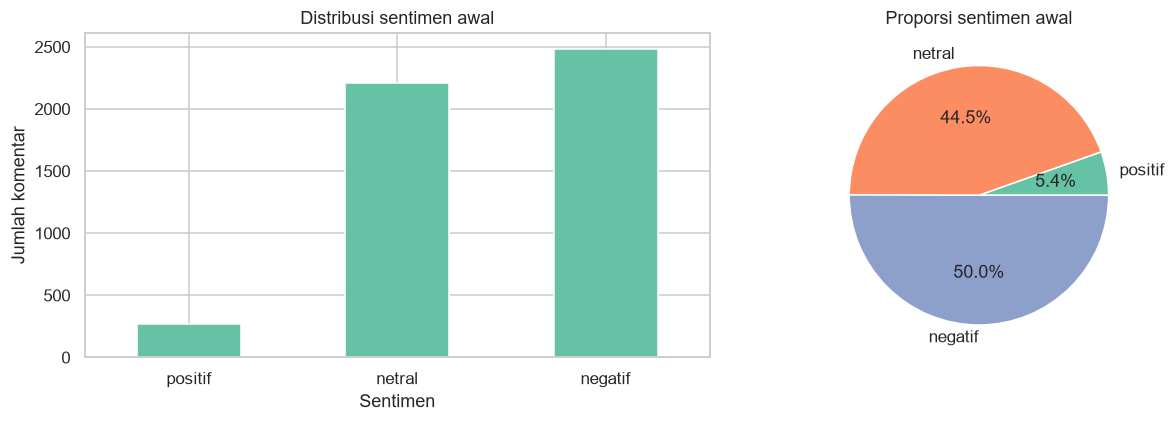

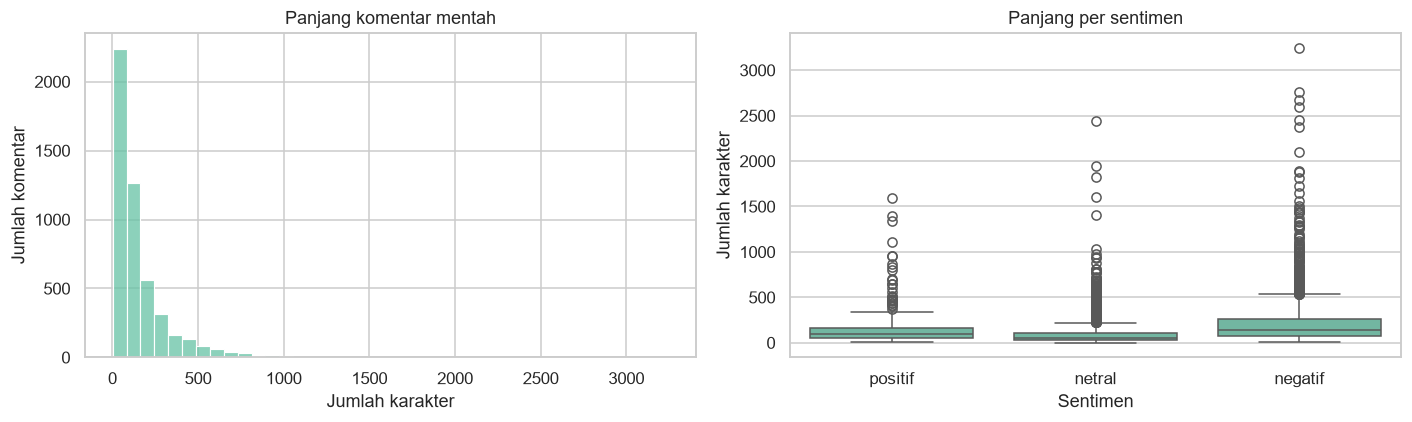

Dataset memiliki **4,968** baris. Rasio kelas terbesar/terkecil **9.21**; macro F1 dipilih agar kelas minoritas tetap berkontribusi setara.

In [ ]:
raw=pd.read_csv(ROOT/'dataset/MBG-label.csv')
display(raw.head(10))
table(pd.DataFrame({'kolom':raw.columns,'dtype':raw.dtypes.astype(str).values,'missing':raw.isna().sum().values}),'schema')
print('Ukuran aktual:',raw.shape,'Duplikat baris:',raw.duplicated().sum())
text_candidates=[c for c in raw.columns if c.lower().strip() in ['comment','komentar','text','teks','full_text']]
label_candidates=[c for c in raw.columns if c.lower().strip() in ['sentiment','sentimen','label']]
assert len(text_candidates)==len(label_candidates)==1,'Kolom ambigu/tidak ditemukan; periksa skema sebelum melanjutkan.'
TEXT,LABEL=text_candidates[0],label_candidates[0]
print('Kolom terdeteksi:',TEXT,LABEL,'Label unik:',raw[LABEL].unique())
LABEL_MAP={'positif':'positif','positive':'positif','netral':'netral','neutral':'netral','negatif':'negatif','negative':'negatif'}
label_norm=raw[LABEL].astype('string').str.strip().str.lower()
unknown=set(label_norm.dropna())-set(LABEL_MAP)-{''}
assert not unknown,f'Label tidak dikenali: {unknown}; wajib audit anotasi.'
initial_counts=label_norm.map(LABEL_MAP).value_counts().reindex(CLASSES,fill_value=0)
table(initial_counts.rename_axis('Sentimen').reset_index(name='Jumlah'),'raw_distribution')
fig,axs=plt.subplots(1,2,figsize=(12,4))
initial_counts.plot.bar(ax=axs[0],rot=0,title='Distribusi sentimen awal',xlabel='Sentimen',ylabel='Jumlah komentar')
axs[1].pie(initial_counts,labels=CLASSES,autopct='%1.1f%%'); axs[1].set_title('Proporsi sentimen awal'); figure('eda_distribution')
eda=pd.DataFrame({'sentimen':label_norm.map(LABEL_MAP),'panjang':raw[TEXT].fillna('').astype(str).str.len()})
fig,axs=plt.subplots(1,2,figsize=(13,4))
sns.histplot(data=eda,x='panjang',bins=40,ax=axs[0]); axs[0].set(title='Panjang komentar mentah',xlabel='Jumlah karakter',ylabel='Jumlah komentar')
sns.boxplot(data=eda,x='sentimen',y='panjang',order=CLASSES,ax=axs[1]); axs[1].set(title='Panjang per sentimen',xlabel='Sentimen',ylabel='Jumlah karakter'); figure('eda_length')
note(f'Dataset memiliki **{len(raw):,}** baris. Rasio kelas terbesar/terkecil **{initial_counts.max()/initial_counts.min():.2f}**; macro F1 dipilih agar kelas minoritas tetap berkontribusi setara.')


## 3. Data Preparation
Tujuan: menghilangkan missing value, duplikat, dan konflik label secara dapat diaudit. Identitas komentar menggunakan lowercase dan spasi tunggal. Seluruh kelompok dengan label bertentangan dikeluarkan karena tidak ada dasar untuk memilih anotasi yang benar; duplikat berlabel sama diambil satu. Pemeriksaan kedua menggunakan hasil preprocessing ber-stemming sebelum pembagian data untuk mencegah representasi identik melintasi subset. Aturan preprocessing bersifat tetap, tidak belajar dari label atau vocabulary korpus.

In [ ]:
audit=[{'Tahapan':'Dataset awal','Jumlah data':len(raw),'Data dihapus':0}]
def record(stage,n):
    audit.append({'Tahapan':stage,'Jumlah data':n,'Data dihapus':audit[-1]['Jumlah data']-n})
df=raw[[TEXT,LABEL]].copy().rename(columns={TEXT:'raw_text',LABEL:'label'})
df['source_row']=df.index+2
df['raw_text']=df.raw_text.astype('string').str.replace(r'\s+',' ',regex=True).str.strip()
df['label']=df.label.astype('string').str.strip().str.lower().map(LABEL_MAP)
df=df.dropna(subset=['raw_text','label']); df=df[df.raw_text.ne('')].copy()
record('Setelah missing value',len(df))
df['raw_key']=df.raw_text.str.lower()
conflict_keys=df.groupby('raw_key').label.nunique().loc[lambda s:s>1].index
conflicts=df[df.raw_key.isin(conflict_keys)].copy()
conflicts.to_csv(OUT/'tables/raw_label_conflicts.csv',index=False)
df=df[~df.raw_key.isin(conflict_keys)].drop_duplicates('raw_key').copy()
record('Setelah penanganan duplikat mentah dan konflik',len(df))
print('Kelompok konflik mentah:',len(conflict_keys))


Kelompok konflik mentah: 0


## 4. Text Preprocessing Bahasa Indonesia
Tujuan: normalisasi deterministik dengan pelestarian negasi. Alur: **Mentah → lowercase → cleaning → normalisasi → tokenisasi → stopword → stemming → final**.
URL, mention, dan tag HTML dihapus; isi hashtag dipertahankan. Emoji yang dipetakan menjadi token deskriptif, tanpa menjadikannya label sentimen; emoji lain menjadi token `emoji_lain` agar keberadaannya tidak hilang. Tanda seru/tanya menjadi token, angka dipertahankan. Stopword memakai daftar Sastrawi; negasi dan penguat penting dikecualikan. Tokenisasi NLTK tidak memerlukan unduhan korpus. Kamus slang eksplisit bukan hasil pembelajaran data. Stemming Sastrawi bersifat kontekstual terbatas; perbandingan tanpa stemming disediakan pada CV dan validasi yang sama.

Pencarian membership pada kamus Sastrawi dioptimalkan menggunakan frozenset dengan anggota identik; algoritma morfologi tetap Sastrawi. Cache fungsi diserialisasi by-value dan dibangun kembali saat model dimuat.

,Raw Text,Lowercase,Cleaned,Tokenized,Normalized,Final Text
0,"pusing denger bahas pemerintah, ga ada bener nya","pusing denger bahas pemerintah, ga ada bener nya",pusing denger bahas pemerintah ga ada bener nya,"['pusing', 'denger', 'bahas', 'pemerintah', 'g...","['pusing', 'denger', 'bahas', 'pemerintah', 't...",pusing denger bahas perintah tidak benar nya
1,Anak gue baru tk dpt jg mbg buat apaan cba.. u...,anak gue baru tk dpt jg mbg buat apaan cba.. u...,anak gue baru tk dpt jg mbg buat apaan cba uju...,"['anak', 'gue', 'baru', 'tk', 'dpt', 'jg', 'mb...","['anak', 'saya', 'baru', 'tk', 'dapat', 'juga'...",anak baru tk mbg buat apa coba ujung emaknya m...
2,Program ini sudah ada di jaman Suharto waktu s...,program ini sudah ada di jaman suharto waktu s...,program ini sudah ada di jaman suharto waktu s...,"['program', 'ini', 'sudah', 'ada', 'di', 'jama...","['program', 'ini', 'sudah', 'ada', 'di', 'jama...",program jaman suharto waktu sd langsung kelola...
3,"Aku gak setuju bukan karena program nya gagal,...","aku gak setuju bukan karena program nya gagal,...",aku gak setuju bukan karena program nya gagal ...,"['aku', 'gak', 'setuju', 'bukan', 'karena', 'p...","['aku', 'tidak', 'setuju', 'bukan', 'karena', ...",aku tidak tuju bukan program nya gagal tapi ti...
4,Indonesia saya perhatikan melaksanakan proyek ...,indonesia saya perhatikan melaksanakan proyek ...,indonesia saya perhatikan melaksanakan proyek ...,"['indonesia', 'saya', 'perhatikan', 'melaksana...","['indonesia', 'saya', 'perhatikan', 'melaksana...",indonesia perhati laksana proyek nya selalu ge...
5,"Presiden kampanye mbg boleh aja , tapi rencana...","presiden kampanye mbg boleh aja , tapi rencana...",presiden kampanye mbg boleh aja tapi rencana i...,"['presiden', 'kampanye', 'mbg', 'boleh', 'aja'...","['presiden', 'kampanye', 'mbg', 'boleh', 'saja...",presiden kampanye mbg tapi rencana kalau uang ...
6,17:30 Gw juga setuju kalau MBG ini biar yang m...,17:30 gw juga setuju kalau mbg ini biar yang m...,17 30 gw juga setuju kalau mbg ini biar yang m...,"['17', '30', 'gw', 'juga', 'setuju', 'kalau', ...","['17', '30', 'saya', 'juga', 'setuju', 'kalau'...",17 30 tuju kalau mbg biar kelola pihak wali mu...
7,GARA2 GIBRAN MBG ( SKRNG PRESIDEN KLW GAK ADA ...,gara2 gibran mbg ( skrng presiden klw gak ada ...,gara2 gibran mbg skrng presiden klw gak ada mb...,"['gara2', 'gibran', 'mbg', 'skrng', 'presiden'...","['gara2', 'gibran', 'mbg', 'skrng', 'presiden'...",gara2 gibran mbg skrng presiden klw tidak mbg ...
8,1.MAKAN BERGIZI GRATIS YG ADA DI PIKIRKAN PRES...,1.makan bergizi gratis yg ada di pikirkan pres...,1 makan bergizi gratis yg ada di pikirkan pres...,"['1', 'makan', 'bergizi', 'gratis', 'yg', 'ada...","['1', 'makan', 'bergizi', 'gratis', 'yang', 'a...",1 makan gizi gratis pikir presiden real lapang...
9,"Ko aku mau ikutan sharing juga tentang MBG,aku...","ko aku mau ikutan sharing juga tentang mbg,aku...",ko aku mau ikutan sharing juga tentang mbg aku...,"['ko', 'aku', 'mau', 'ikutan', 'sharing', 'jug...","['ko', 'aku', 'mau', 'ikutan', 'sharing', 'jug...",ko aku mau ikut sharing mbg aku kan kerja rant...



Preprocessing:   0%|          | 0/4889 [00:00<?, ?it/s]


Preprocessing:   1%|          | 51/4889 [00:00<00:10, 463.33it/s]


Preprocessing:   3%|▎         | 129/4889 [00:00<00:07, 627.02it/s]


Preprocessing:   4%|▍         | 206/4889 [00:00<00:06, 685.05it/s]

...


Preprocessing:  93%|█████████▎| 4557/4889 [00:02<00:00, 3401.43it/s]


Preprocessing: 100%|██████████| 4889/4889 [00:02<00:00, 1776.92it/s]

Komentar menjadi kosong: 13


,Tahapan,Jumlah data,Data dihapus
0,Dataset awal,4968,0
1,Setelah missing value,4968,0
2,Setelah penanganan duplikat mentah dan konflik,4889,79
3,Setelah teks kosong preprocessing,4876,13
4,Dataset siap olah,4847,29


,Tahap,Rata-rata karakter,Rata-rata token
0,Sebelum,163.637095,25.677739
1,Sesudah,125.893130,20.481122


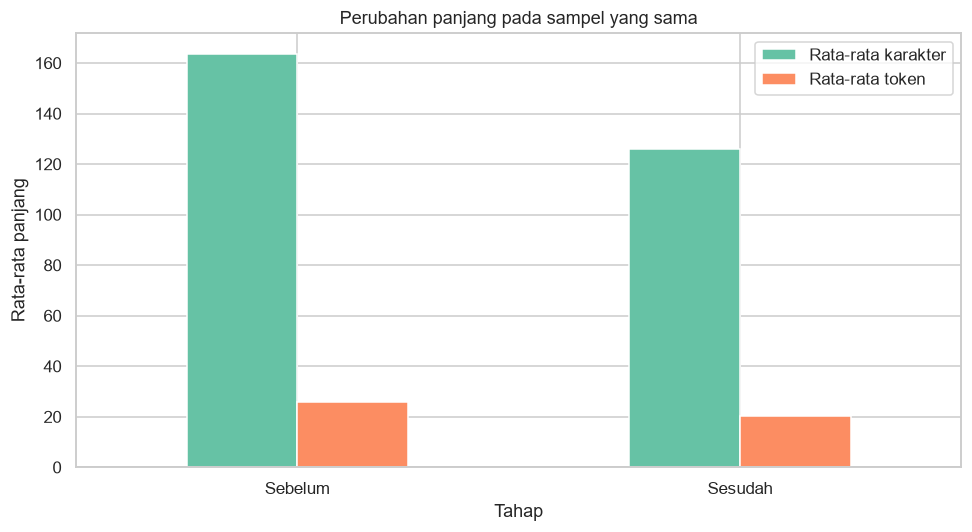

Data siap olah: **4,847** komentar. Terdapat **0** kelompok konflik representasi preprocessing, dikeluarkan seluruhnya. Dampak eksklusi terhadap distribusi kelas perlu diperhatikan; anotasi ulang adalah langkah lanjutan yang lebih baik.

In [ ]:
SLANG={'ga':'tidak','gak':'tidak','nggak':'tidak','gk':'tidak','ngga':'tidak','tdk':'tidak','tak':'tidak','bkn':'bukan','blm':'belum','jgn':'jangan','yg':'yang','dgn':'dengan','utk':'untuk','krn':'karena','karna':'karena','klo':'kalau','kalo':'kalau','aja':'saja','udah':'sudah','udh':'sudah','sdh':'sudah','dpt':'dapat','dapet':'dapat','bgt':'banget','bgtt':'banget','jg':'juga','jga':'juga','emang':'memang','gimana':'bagaimana','gmna':'bagaimana','gmn':'bagaimana','gue':'saya','gw':'saya','lu':'kamu','dr':'dari','dlm':'dalam','tp':'tapi','tpi':'tapi','pd':'pada','sy':'saya','sm':'sama','org':'orang','anak2':'anak anak','mkn':'makan','cba':'coba','bener':'benar'}
NEGATIONS={'tidak','bukan','belum','jangan','tak','tanpa','kurang','banget','sangat','tapi','namun'}
STOPWORDS=set(StopWordRemoverFactory().get_stop_words())-NEGATIONS
EMOJI={'🤣':'emoji_tertawa','😂':'emoji_tertawa','😊':'emoji_senyum','👍':'emoji_jempol','❤':'emoji_hati','❤️':'emoji_hati','😡':'emoji_marah','😢':'emoji_sedih','😭':'emoji_menangis','🙏':'emoji_doa','🤮':'emoji_muntah','🤢':'emoji_mual'}
tokenizer=RegexpTokenizer(r'[a-z0-9_]+')
stemmer=StemmerFactory().create_stemmer()
# Optimasi membership kamus; aturan morfologi dan himpunan kata tidak berubah.
dictionary=stemmer.delegatedStemmer.dictionary
original_words=tuple(dictionary.words)
dictionary.words=frozenset(original_words)
assert all(dictionary.contains(w) for w in original_words)

@lru_cache(maxsize=100000)
def stem_word(word):
    return word if word in NEGATIONS or word.startswith('emoji_') else stemmer.stem(word)
@lru_cache(maxsize=50000)
def stages(text,stem=True):
    lower=html.unescape(str(text)).lower()
    cleaned=re.sub(r'https?://\S+|www\.\S+|@\w+|<[^>]*>',' ',lower)
    for symbol,token in sorted(EMOJI.items(),key=lambda x:-len(x[0])): cleaned=cleaned.replace(symbol,' '+token+' ')
    cleaned=re.sub(r'[\U0001F000-\U0001FAFF\u2600-\u27BF]',' emoji_lain ',cleaned)
    cleaned=cleaned.replace('!',' tanda_seru ').replace('?',' tanda_tanya ')
    cleaned=re.sub(r'[^a-z0-9_\s]',' ',cleaned)
    cleaned=re.sub(r'\s+',' ',cleaned).strip()
    tokens=RegexpTokenizer(r'[a-z0-9_]+').tokenize(cleaned)
    normalized=' '.join(SLANG.get(t,t) for t in tokens).split()
    filtered=[t for t in normalized if t not in STOPWORDS]
    final=' '.join(stem_word(t) if stem else t for t in filtered)
    return lower,cleaned,tokens,normalized,final
# Wrapper joblib menyimpan fungsi notebook by-value untuk pemuatan di proses Python baru.
@wrap_non_picklable_objects
def preprocess_batch(texts,stem=True): return [stages(str(t),stem)[-1] for t in texts]
records=[{'Raw Text':t,'Lowercase':stages(t)[0],'Cleaned':stages(t)[1],'Tokenized':str(stages(t)[2]),'Normalized':str(stages(t)[3]),'Final Text':stages(t)[4]} for t in df.raw_text.head(10)]
table(pd.DataFrame(records),'preprocessing_examples')
df['final_text']=[stages(t)[-1] for t in tqdm(df.raw_text,desc='Preprocessing')]
empty=df.final_text.eq('')
print('Komentar menjadi kosong:',int(empty.sum()))
df[empty].to_csv(OUT/'tables/empty_after_preprocessing.csv',index=False)
df=df[~empty].copy(); record('Setelah teks kosong preprocessing',len(df))
pre_conflicts=df.groupby('final_text').label.nunique().loc[lambda x:x>1].index
df[df.final_text.isin(pre_conflicts)].to_csv(OUT/'tables/normalized_label_conflicts.csv',index=False)
df=df[~df.final_text.isin(pre_conflicts)].drop_duplicates('final_text').reset_index(drop=True)
record('Dataset siap olah',len(df)); table(pd.DataFrame(audit),'preparation_audit')
df.to_csv(OUT/'tables/prepared_dataset.csv',index=False)
lengths=pd.DataFrame({'Tahap':['Sebelum','Sesudah'],'Rata-rata karakter':[df.raw_text.str.len().mean(),df.final_text.str.len().mean()],'Rata-rata token':[df.raw_text.str.split().str.len().mean(),df.final_text.str.split().str.len().mean()]})
table(lengths,'preprocessing_lengths')
lengths.set_index('Tahap').plot.bar(rot=0,title='Perubahan panjang pada sampel yang sama',ylabel='Rata-rata panjang'); figure('preprocessing_length')
note(f'Data siap olah: **{len(df):,}** komentar. Terdapat **{len(pre_conflicts)}** kelompok konflik representasi preprocessing, dikeluarkan seluruhnya. Dampak eksklusi terhadap distribusi kelas perlu diperhatikan; anotasi ulang adalah langkah lanjutan yang lebih baik.')


## 5. Data Splitting dan Audit Leakage
Tujuan: menyimpan test terkunci. Stratifikasi 70/15/15 dengan seed 42, pembulatan ukuran mengikuti scikit-learn. Setiap komentar/representasi final unik. Jika minoritas <7, penelitian tiga subset dihentikan dengan peringatan; alternatif yang layak adalah menambah anotasi atau nested stratified CV, bukan mengarang hasil. Jumlah fold CV dikurangi otomatis bila training tidak mendukung 5 fold.

,Dataset,positif,netral,negatif,Total,Proporsi
0,Training,183,1479,1730,3392,0.699814
1,Validation,39,317,371,727,0.149990
2,Testing,40,317,371,728,0.150196


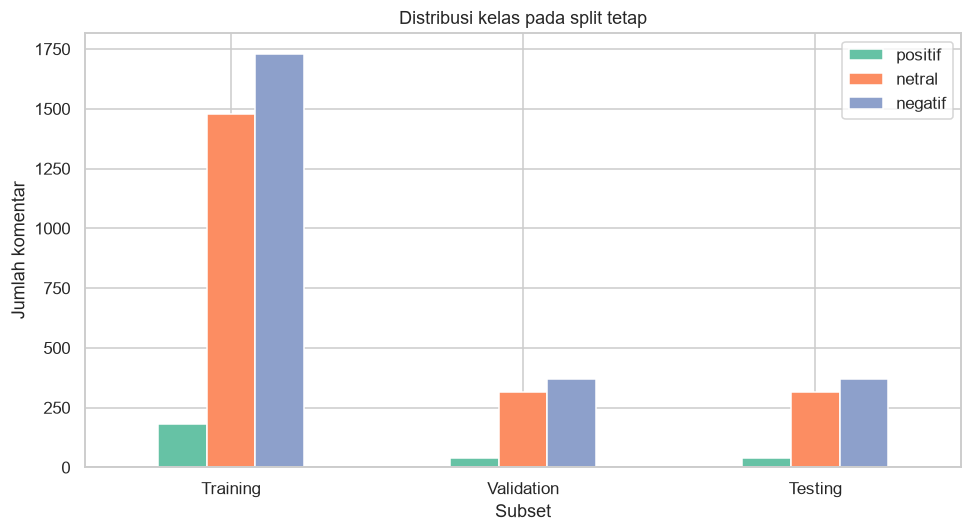

Leakage identitas/representasi: LULUS; CV folds: 5


In [ ]:
counts=df.label.value_counts()
if counts.min()<7:
    warnings.warn('Kelas minoritas tidak memadai; gunakan tambahan anotasi atau nested stratified CV.')
    raise ValueError('Tidak cukup data untuk tiga subset stratified yang dapat dibandingkan.')
train,hold=train_test_split(df,test_size=.30,stratify=df.label,random_state=SEED)
valid,test=train_test_split(hold,test_size=.50,stratify=hold.label,random_state=SEED)
for a,b in [(train,valid),(train,test),(valid,test)]:
    assert not set(a.raw_key)&set(b.raw_key)
    assert not set(a.final_text)&set(b.final_text)
    assert not set(a.source_row)&set(b.source_row)
subsets={'Training':train,'Validation':valid,'Testing':test}
split_table=pd.DataFrame([{'Dataset':name,**part.label.value_counts().reindex(CLASSES,fill_value=0).to_dict(),'Total':len(part),'Proporsi':len(part)/len(df)} for name,part in subsets.items()])
table(split_table,'split_distribution')
split_table.set_index('Dataset')[CLASSES].plot.bar(rot=0,title='Distribusi kelas pada split tetap',xlabel='Subset',ylabel='Jumlah komentar'); figure('split_distribution')
pd.concat([part.assign(subset=name) for name,part in subsets.items()]).to_csv(OUT/'tables/split_manifest.csv',index=False)
folds=min(5,int(train.label.value_counts().min()))
cv=list(StratifiedKFold(n_splits=folds,shuffle=True,random_state=SEED).split(train.raw_text,train.label))
if folds<5: warnings.warn(f'CV menggunakan {folds} fold karena keterbatasan minoritas.')
print('Leakage identitas/representasi: LULUS; CV folds:',folds)
Xtr,ytr=train.raw_text,train.label
Xv,yv=valid.raw_text,valid.label
Xte,yte=test.raw_text,test.label


## 6. Feature Engineering TF-IDF dan Baseline
Tujuan: mempelajari vocabulary hanya dari training. Unigram dan unigram+bigram dibandingkan. Grid memakai max_features=10000, min_df=1, max_df=1.0 dan sublinear_tf=True yang ditetapkan untuk membatasi biaya komputasi serta menghindari vocabulary kosong pada fold kecil. TF-IDF berada di dalam pipeline pada setiap fold. Baseline mayoritas dan konfigurasi awal ketiga algoritma dievaluasi pada validasi sebelum tuning.

(1, 1) ukuran matriks: (3392, 7375) contoh fitur: ['00' '000' '00000000001' '00017' '00n' '01' '02' '03' '05' '06' '07' '08'
 '09' '10' '100' '1000' '10000' '100000' '10000000000' '1000tinggal'
 '100gr' '100k' '107' '10k' '10m']


(1, 2) ukuran matriks: (3392, 10000) contoh fitur: ['00' '000' '000 000' '01' '02' '03' '07' '08' '09' '09 55' '10' '10 000'
 '10 15' '10 36' '10 orang' '10 rb' '10 ribu' '10 tahun' '10 tidak' '100'
 '100 siswa' '1000' '1000 broker' '1000 hari' '10k']


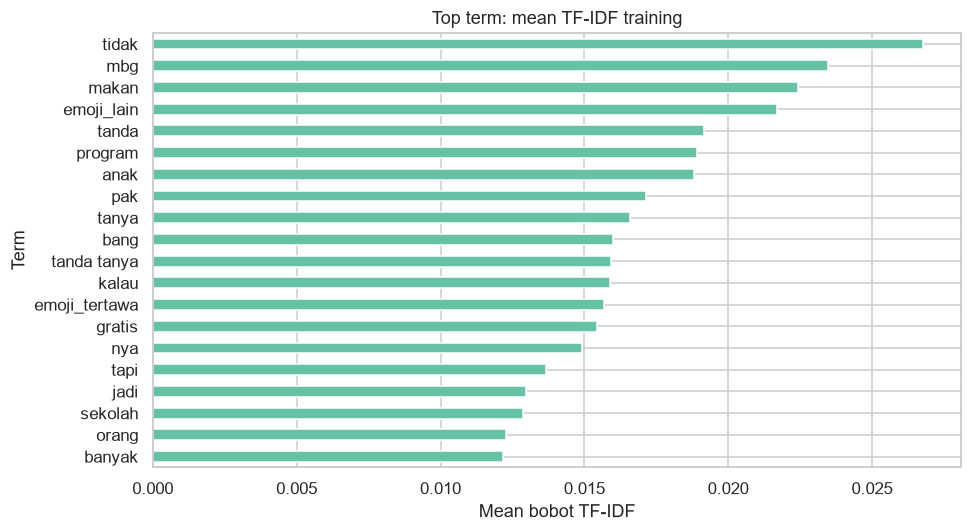

,label,komentar,top_terms
0,positif,Makan Siang Gratis itu program yg baik dan bag...,"awal, pernah, tidak pernah, bagus kalau, progr..."
1,netral,bang keluar dari managementnya dedi ko bazer b...,"males, bang kalau, logo, logo close, dedi, kya..."
2,negatif,Seakan akan negara menutup mata akan kebenaran...,"sebut kelola, sebut, negara, beda, koruptor, b..."


,ngram,baris,fitur,nonzero
0,"(1, 1)",3392,7375,56607
1,"(1, 2)",3392,10000,76290


,Model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,fit_seconds,predict_seconds
0,Mayoritas,0.510316,0.170105,0.333333,0.225258,0.260423,0.510316,0.344859,NaN,NaN
1,SVM,0.723521,0.621316,0.583366,0.597056,0.717023,0.723521,0.719357,0.149820,0.109368
2,KNN,0.594223,0.650557,0.468162,0.488632,0.613164,0.594223,0.585968,0.111776,0.110301
3,Naive Bayes,0.605227,0.441253,0.408797,0.374322,0.620142,0.605227,0.543015,0.114220,0.020940


In [ ]:
def make_pipeline(model,stem=True,ngram=(1,1)):
    return Pipeline([('preprocess',FunctionTransformer(preprocess_batch,kw_args={'stem':stem})),('tfidf',TfidfVectorizer(ngram_range=ngram,max_features=10000,min_df=1,max_df=1.0,sublinear_tf=True)),('model',model)])
feature_rows=[]
for ngram in [(1,1),(1,2)]:
    p=make_pipeline(LinearSVC(random_state=SEED),ngram=ngram)
    matrix=p[:-1].fit_transform(Xtr)
    vector=p.named_steps['tfidf']; names=vector.get_feature_names_out()
    feature_rows.append({'ngram':str(ngram),'baris':matrix.shape[0],'fitur':matrix.shape[1],'nonzero':matrix.nnz})
    print(ngram,'ukuran matriks:',matrix.shape,'contoh fitur:',names[:25])
    if ngram==(1,2):
        weights=np.asarray(matrix.mean(axis=0)).ravel(); top=np.argsort(weights)[-20:]
        pd.Series(weights[top],index=names[top]).plot.barh(title='Top term: mean TF-IDF training',xlabel='Mean bobot TF-IDF',ylabel='Term'); figure('top_tfidf_terms')
        sample_terms=[]
        for label in CLASSES:
            i=int(np.flatnonzero(ytr.to_numpy()==label)[0]); row=matrix.getrow(i); idx=row.indices[np.argsort(row.data)[-8:]]
            sample_terms.append({'label':label,'komentar':Xtr.iloc[i],'top_terms':', '.join(names[idx])})
        table(pd.DataFrame(sample_terms),'representative_features')
table(pd.DataFrame(feature_rows),'feature_counts')
def metrics(y,pred):
    result={'accuracy':accuracy_score(y,pred)}
    for avg in ['macro','weighted']:
        prec,rec,f1,_=precision_recall_fscore_support(y,pred,labels=CLASSES,average=avg,zero_division=0)
        result.update({f'precision_{avg}':prec,f'recall_{avg}':rec,f'f1_{avg}':f1})
    return result
models={'SVM':LinearSVC(random_state=SEED,max_iter=10000),'KNN':KNeighborsClassifier(n_neighbors=5,metric='cosine',algorithm='brute',n_jobs=1),'Naive Bayes':MultinomialNB()}
base_rows=[]
dummy=DummyClassifier(strategy='most_frequent').fit(np.zeros((len(ytr),1)),ytr)
base_rows.append({'Model':'Mayoritas',**metrics(yv,dummy.predict(np.zeros((len(yv),1))))})
for name,model in models.items():
    p=make_pipeline(clone(model)); start=time.perf_counter(); p.fit(Xtr,ytr); fit_seconds=time.perf_counter()-start
    start=time.perf_counter(); pred=p.predict(Xv); predict_seconds=time.perf_counter()-start
    base_rows.append({'Model':name,**metrics(yv,pred),'fit_seconds':fit_seconds,'predict_seconds':predict_seconds})
table(pd.DataFrame(base_rows),'baseline_validation')


## 7. Modeling, Tuning, dan Eksperimen Preprocessing
Tujuan: membandingkan tiga algoritma menggunakan split dan fold yang identik. GridSearchCV mengoptimalkan macro F1 hanya pada training. Seluruh nilai C, class_weight, k, weights, metric, alpha yang diminta dicoba, dengan dua ngram dan dua kebijakan stemming. KNN brute kompatibel dengan sparse cosine/euclidean. Evaluasi tanpa/ber-stemming merupakan perbandingan konfigurasi yang dituning, bukan klaim kausal murni stemming. Konfigurasi per algoritma dipilih dari hasil CV; algoritma pemenang dipilih berdasarkan macro F1 validasi, CV sebagai pemecah seri. Test belum digunakan.

Tuning SVM


SVM CV: 0.6796562547339238 waktu: 53.11 detik


Tuning KNN


KNN CV: 0.5018235003736634 waktu: 200.54 detik


Tuning Naive Bayes


Naive Bayes CV: 0.4586043394914131 waktu: 46.18 detik


,Model,best_params,cv_mean,cv_std,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,tuning_seconds,refit_seconds,predict_seconds
0,SVM,"{""model__C"": 0.1, ""model__class_weight"": ""bala...",0.679656,0.013617,0.751032,0.654080,0.671243,0.661878,0.753902,0.751032,0.752328,53.113564,0.279737,0.048026
1,KNN,"{""model__metric"": ""cosine"", ""model__n_neighbor...",0.501824,0.022667,0.587345,0.640714,0.458164,0.470781,0.615325,0.587345,0.575383,200.538856,0.221259,0.190995
2,Naive Bayes,"{""model__alpha"": 0.01, ""preprocess__kw_args"": ...",0.458604,0.017081,0.632737,0.592476,0.459201,0.464692,0.630273,0.632737,0.609793,46.175357,0.662881,0.072806


,Model,stemming,cv_mean,cv_std,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,params
0,SVM,True,0.679656,0.013617,0.751032,0.654080,0.671243,0.661878,0.753902,0.751032,0.752328,"{""model__C"": 0.1, ""model__class_weight"": ""bala..."
1,SVM,False,0.679106,0.012539,0.745530,0.666809,0.659083,0.662683,0.744070,0.745530,0.744564,"{""model__C"": 0.1, ""model__class_weight"": ""bala..."
2,KNN,True,0.501824,0.022667,0.587345,0.640714,0.458164,0.470781,0.615325,0.587345,0.575383,"{""model__metric"": ""cosine"", ""model__n_neighbor..."
3,KNN,False,0.501285,0.028817,0.614856,0.621491,0.484700,0.499279,0.636259,0.614856,0.604720,"{""model__metric"": ""cosine"", ""model__n_neighbor..."
4,Naive Bayes,True,0.458604,0.017081,0.632737,0.592476,0.459201,0.464692,0.630273,0.632737,0.609793,"{""model__alpha"": 0.01, ""preprocess__kw_args"": ..."
5,Naive Bayes,False,0.456922,0.017551,0.649243,0.619675,0.493999,0.511521,0.649548,0.649243,0.631105,"{""model__alpha"": 0.01, ""preprocess__kw_args"": ..."


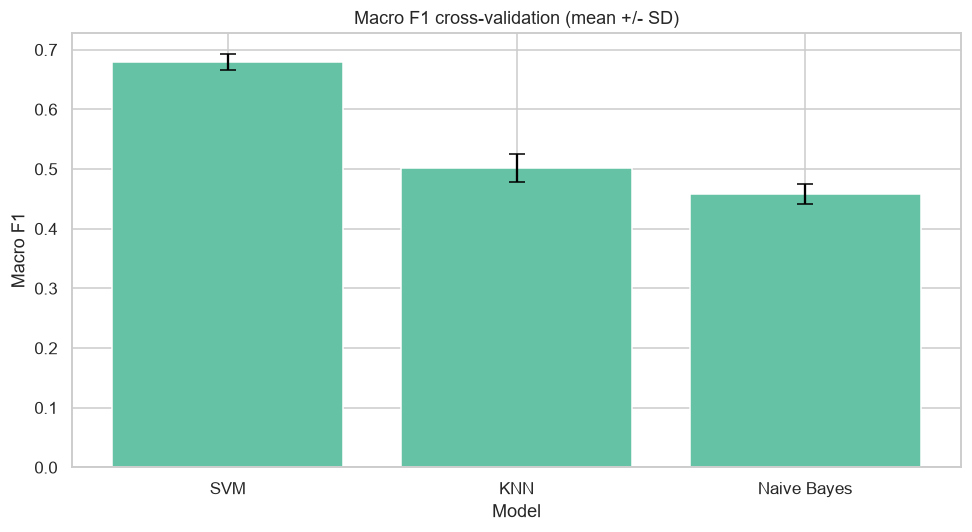

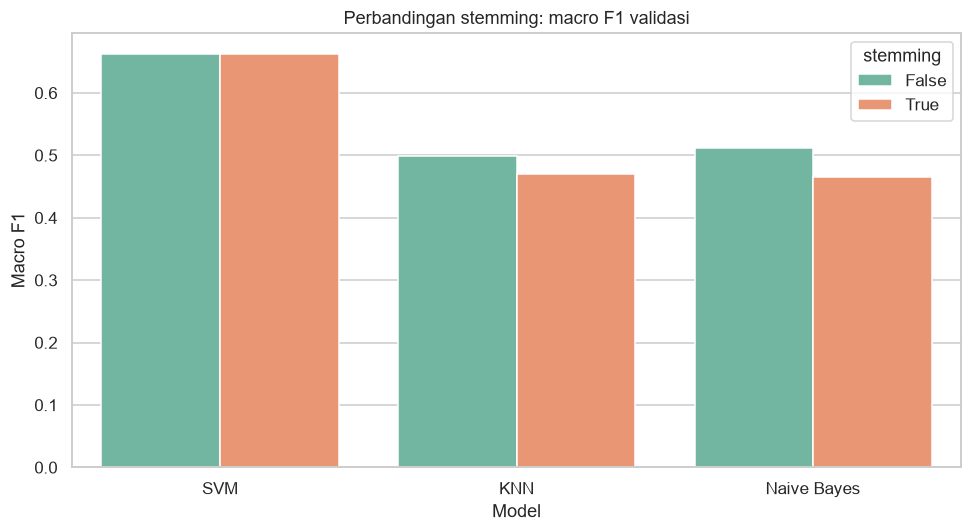

Model terpilih sebelum membuka test: **SVM**, macro F1 validasi **0.6619**. Skor CV dan validasi dapat berbeda karena komposisi sampel dan variasi kelas minoritas. SD antar-fold bukan confidence interval.

258

In [ ]:
shared={'tfidf__ngram_range':[(1,1),(1,2)],'preprocess__kw_args':[{'stem':True},{'stem':False}]}
min_fold_train=min(len(i) for i,j in cv)
ks=[k for k in [3,5,7,9,11] if k<=min_fold_train]
grids={'SVM':{**shared,'model__C':[.01,.1,1,10],'model__class_weight':[None,'balanced']},'KNN':{**shared,'model__n_neighbors':ks,'model__weights':['uniform','distance'],'model__metric':['cosine','euclidean']},'Naive Bayes':{**shared,'model__alpha':[.01,.1,.5,1.,2.]}}
searches={}; validation_rows=[]; ablation=[]
for name,model in models.items():
    print('Tuning',name,flush=True); start=time.perf_counter()
    search=GridSearchCV(make_pipeline(clone(model)),grids[name],scoring='f1_macro',cv=cv,n_jobs=1,refit=True,error_score='raise',return_train_score=False)
    search.fit(Xtr,ytr); elapsed=time.perf_counter()-start
    searches[name]=search
    results=pd.DataFrame(search.cv_results_)
    results.to_csv(OUT/'tables'/f'tuning_{name.replace(" ","_")}.csv',index=False)
    start=time.perf_counter(); prediction=search.predict(Xv); pred_time=time.perf_counter()-start
    best=search.best_index_
    validation_rows.append({'Model':name,'best_params':json.dumps(search.best_params_),'cv_mean':search.best_score_,'cv_std':results.loc[best,'std_test_score'],**metrics(yv,prediction),'tuning_seconds':elapsed,'refit_seconds':search.refit_time_,'predict_seconds':pred_time})
    for stemming in [True,False]:
        mask=results['param_preprocess__kw_args'].map(lambda x:x['stem']==stemming)
        idx=results.loc[mask,'mean_test_score'].idxmax(); params=results.loc[idx,'params']
        p=make_pipeline(clone(model)).set_params(**params).fit(Xtr,ytr)
        ablation.append({'Model':name,'stemming':stemming,'cv_mean':results.loc[idx,'mean_test_score'],'cv_std':results.loc[idx,'std_test_score'],**metrics(yv,p.predict(Xv)),'params':json.dumps(params)})
    print(name,'CV:',search.best_score_,'waktu:',round(elapsed,2),'detik',flush=True)
validation=pd.DataFrame(validation_rows).sort_values(['f1_macro','cv_mean','Model'],ascending=[False,False,True])
table(validation,'validation_comparison'); table(pd.DataFrame(ablation),'stemming_ablation')
winner=validation.iloc[0]['Model']
plt.bar(validation.Model,validation.cv_mean,yerr=validation.cv_std,capsize=5)
plt.title('Macro F1 cross-validation (mean +/- SD)'); plt.ylabel('Macro F1'); plt.xlabel('Model'); figure('cv_comparison')
sns.barplot(data=pd.DataFrame(ablation),x='Model',y='f1_macro',hue='stemming'); plt.title('Perbandingan stemming: macro F1 validasi'); plt.ylabel('Macro F1'); figure('stemming_comparison')
note(f'Model terpilih sebelum membuka test: **{winner}**, macro F1 validasi **{validation.iloc[0].f1_macro:.4f}**. Skor CV dan validasi dapat berbeda karena komposisi sampel dan variasi kelas minoritas. SD antar-fold bukan confidence interval.')
(OUT/'reports/selection.json').write_text(json.dumps({'winner':winner,'criterion':'validation macro F1; CV tie-break','params':searches[winner].best_params_},indent=2))


## 8. Final Testing dan Evaluasi
Tujuan: mengestimasi kemampuan generalisasi pada test terkunci. Ketiga konfigurasi hasil CV dilatih ulang pada training+validation yang sama. Masing-masing menghasilkan satu prediksi test yang digunakan untuk semua metrik dan grafik. Hasil test tidak mengubah pemenang yang telah dipilih. Precision/recall/F1 weighted melengkapi macro; zero_division=0 mengungkap kegagalan prediksi kelas melalui skor nol.

,kelas,precision,recall,f1-score,support
0,positif,0.418182,0.575000,0.484211,40.000000
1,netral,0.722772,0.690852,0.706452,317.000000
2,negatif,0.802703,0.800539,0.801619,371.000000
3,accuracy,0.740385,0.740385,0.740385,0.740385
4,macro avg,0.647886,0.688797,0.664094,728.000000
5,weighted avg,0.746770,0.740385,0.742740,728.000000


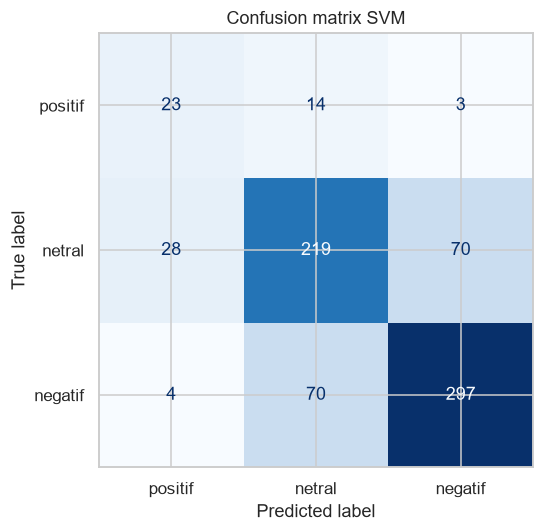

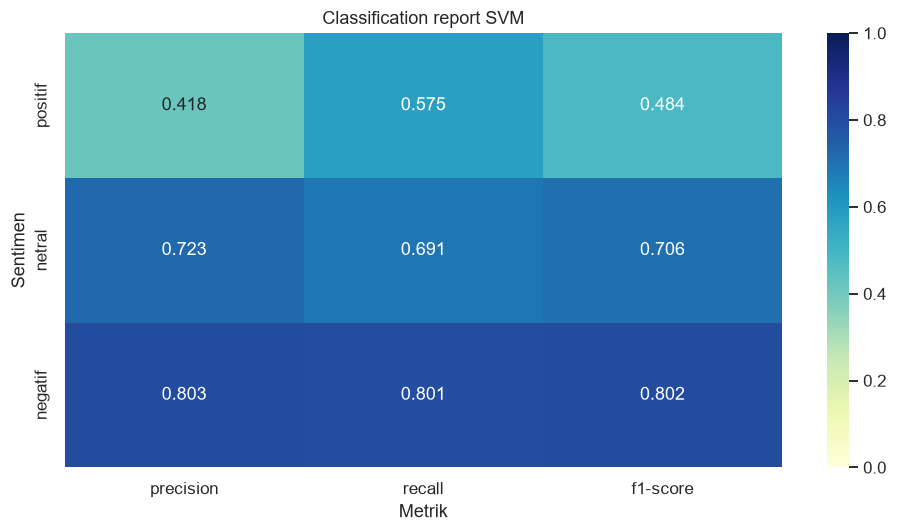

,kelas,precision,recall,f1-score,support
0,positif,0.400000,0.200000,0.266667,40.000000
1,netral,0.514806,0.712934,0.597884,317.000000
2,negatif,0.669145,0.485175,0.562500,371.000000
3,accuracy,0.568681,0.568681,0.568681,0.568681
4,macro avg,0.527984,0.466036,0.475683,728.000000
5,weighted avg,0.587152,0.568681,0.561653,728.000000


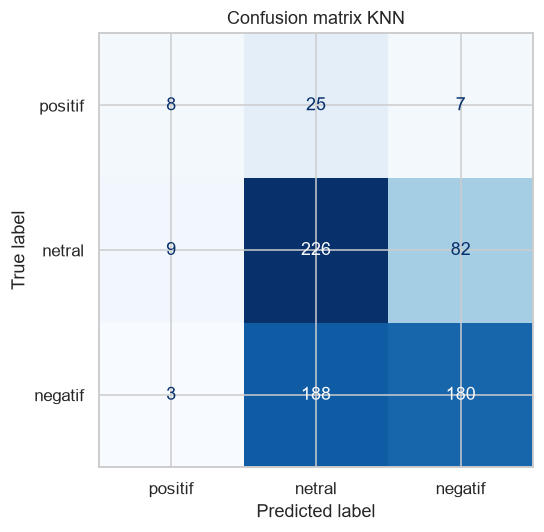

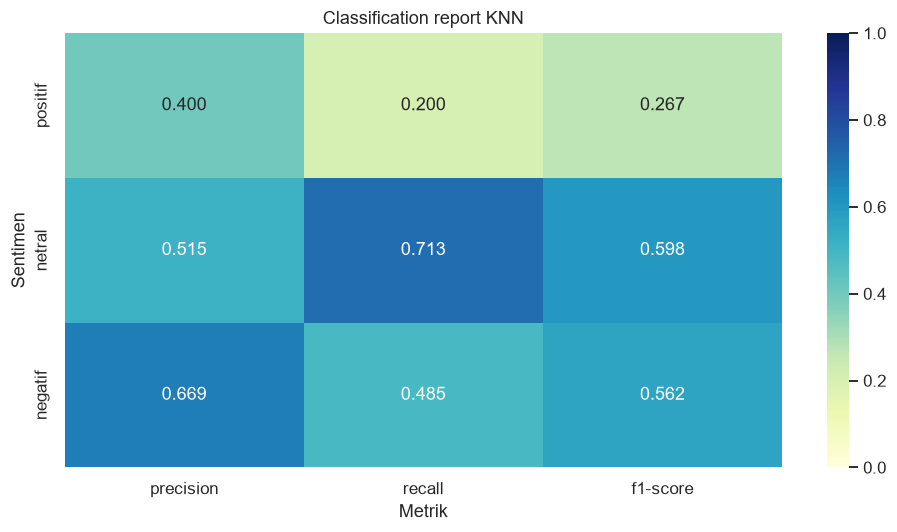

,kelas,precision,recall,f1-score,support
0,positif,0.333333,0.100000,0.153846,40.000000
1,netral,0.637795,0.511041,0.567426,317.000000
2,negatif,0.662338,0.824798,0.734694,371.000000
3,accuracy,0.648352,0.648352,0.648352,0.648352
4,macro avg,0.544489,0.478613,0.485322,728.000000
5,weighted avg,0.633574,0.648352,0.629944,728.000000


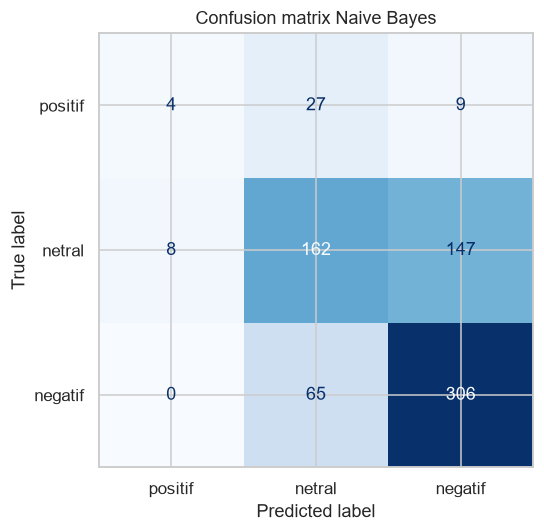

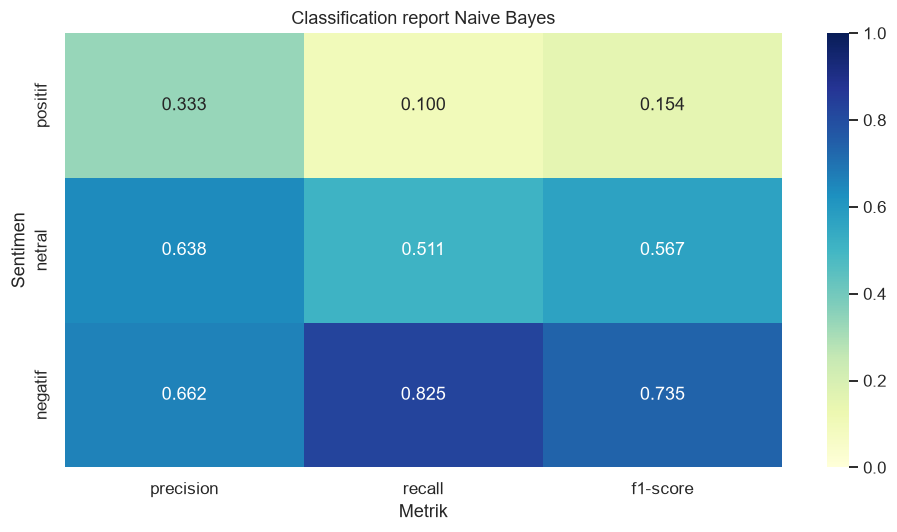

,Model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,fit_seconds,predict_seconds
0,SVM,0.740385,0.647886,0.688797,0.664094,0.746770,0.740385,0.742740,0.300415,0.208410
1,KNN,0.568681,0.527984,0.466036,0.475683,0.587152,0.568681,0.561653,0.254044,0.202508
2,Naive Bayes,0.648352,0.544489,0.478613,0.485322,0.633574,0.648352,0.629944,0.298866,0.037914


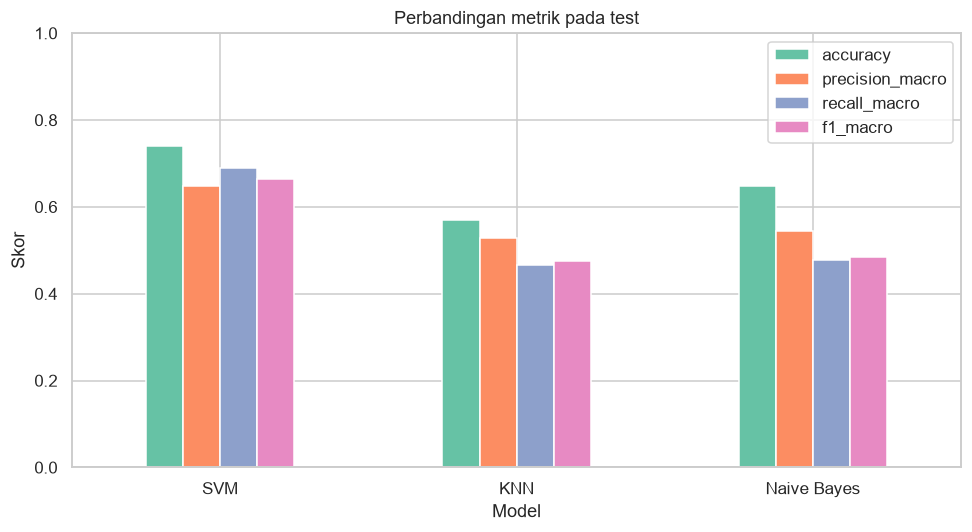

,kelas,precision,recall,f1-score,support,Model
0,positif,0.418182,0.575000,0.484211,40.0,SVM
1,netral,0.722772,0.690852,0.706452,317.0,SVM
2,negatif,0.802703,0.800539,0.801619,371.0,SVM
3,positif,0.400000,0.200000,0.266667,40.0,KNN
4,netral,0.514806,0.712934,0.597884,317.0,KNN
5,negatif,0.669145,0.485175,0.562500,371.0,KNN
6,positif,0.333333,0.100000,0.153846,40.0,Naive Bayes
7,netral,0.637795,0.511041,0.567426,317.0,Naive Bayes
8,negatif,0.662338,0.824798,0.734694,371.0,Naive Bayes


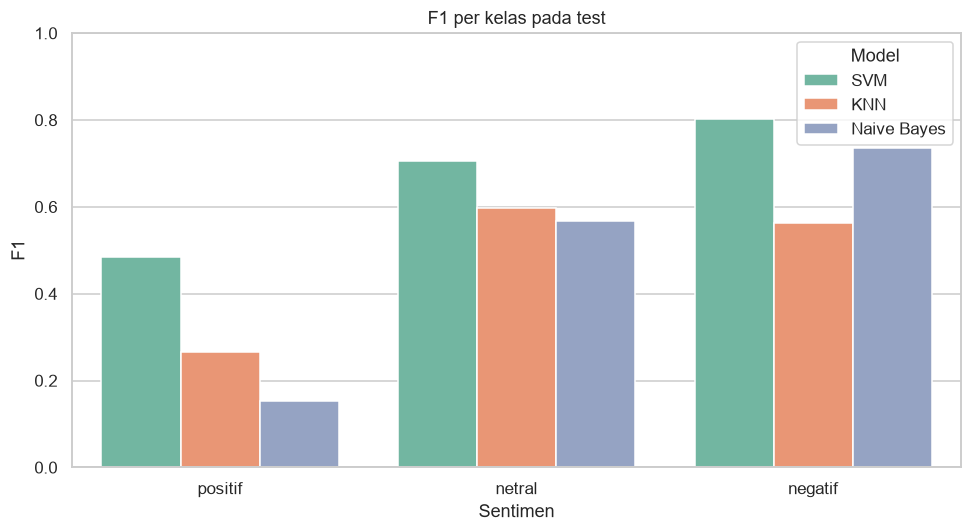

In [ ]:
trainval=pd.concat([train,valid])
final_models={}; predictions={}; final_rows=[]; reports=[]
for name,search in searches.items():
    p=clone(search.best_estimator_); start=time.perf_counter(); p.fit(trainval.raw_text,trainval.label); fit_seconds=time.perf_counter()-start
    start=time.perf_counter(); pred=p.predict(Xte); predict_seconds=time.perf_counter()-start
    final_models[name]=p; predictions[name]=pred
    final_rows.append({'Model':name,**metrics(yte,pred),'fit_seconds':fit_seconds,'predict_seconds':predict_seconds})
    report=pd.DataFrame(classification_report(yte,pred,labels=CLASSES,output_dict=True,zero_division=0)).T
    table(report.rename_axis('kelas').reset_index(),f'classification_report_{name.replace(" ","_")}')
    reports.append(report.loc[CLASSES].assign(Model=name).rename_axis('kelas').reset_index())
    ConfusionMatrixDisplay.from_predictions(yte,pred,labels=CLASSES,cmap='Blues',colorbar=False)
    plt.title('Confusion matrix '+name); figure('confusion_'+name.replace(' ','_'))
    sns.heatmap(report.loc[CLASSES,['precision','recall','f1-score']],annot=True,fmt='.3f',vmin=0,vmax=1,cmap='YlGnBu'); plt.title('Classification report '+name); plt.xlabel('Metrik'); plt.ylabel('Sentimen'); figure('report_heatmap_'+name.replace(' ','_'))
final=pd.DataFrame(final_rows); table(final,'test_evaluation')
final.set_index('Model')[['accuracy','precision_macro','recall_macro','f1_macro']].plot.bar(rot=0,ylim=(0,1),title='Perbandingan metrik pada test',ylabel='Skor',xlabel='Model'); figure('test_metrics')
perclass=pd.concat(reports,ignore_index=True); table(perclass,'per_class_metrics')
sns.barplot(data=perclass,x='kelas',y='f1-score',hue='Model',order=CLASSES); plt.ylim(0,1); plt.title('F1 per kelas pada test'); plt.xlabel('Sentimen'); plt.ylabel('F1'); figure('per_class_f1')


## 9. Error Analysis
Tujuan: mengidentifikasi arah kesalahan dan contoh nyata untuk audit manual. Kata negasi/slang dan penanda tanda baca/emoji hanya indikator yang dapat diperiksa; tidak membuktikan sarkasme atau penyebab kesalahan. Tidak ada label sarkasme pada dataset. Kesalahan juga dapat berasal dari label ambigu atau ketidakjelasan konteks.

In [ ]:
errors=[]
for name,pred in predictions.items():
    e=test[['source_row','raw_text','label']].copy(); e['Prediksi']=pred; e['Model']=name
    e=e[e.label!=e.Prediksi].rename(columns={'raw_text':'Komentar','label':'Label Aktual'})
    e['indikator_negasi']=e.Komentar.str.lower().str.contains(r'\b(?:tidak|bukan|belum|jangan|tak|ga|gak|nggak)\b',regex=True)
    e['indikator_slang']=e.Komentar.str.lower().map(lambda t:any(w in SLANG for w in re.findall(r'\w+',t)))
    e['indikator_ambigu_perlu_review']=e.Komentar.str.contains(r'[!?🤣😂]',regex=True)
    errors.append(e)
errors=pd.concat(errors,ignore_index=True)
errors.to_csv(OUT/'tables/all_errors.csv',index=False)
table(errors.groupby(['Model','Label Aktual'],sort=False).head(5),'error_examples')
if len(errors):
    pairs=errors.groupby(['Model','Label Aktual','Prediksi']).size().reset_index(name='Jumlah').sort_values('Jumlah',ascending=False)
    table(pairs,'error_pairs')
    table(errors.groupby('Model')[['indikator_negasi','indikator_slang','indikator_ambigu_perlu_review']].mean().reset_index(),'error_indicators')
hardest=perclass.loc[perclass.groupby('Model')['recall'].idxmin(),['Model','kelas','recall','f1-score']]
table(hardest,'hardest_classes')
for row in hardest.itertuples(index=False): note(f'Pada **{row.Model}**, kelas dengan recall terendah adalah **{row.kelas}** ({row.recall:.3f}). Ini menunjukkan kelas tersebut paling sering terlewat, bukan bukti penyebab linguistik tertentu.')
note('Tabel contoh dipisahkan per model dan label aktual agar kesalahan positif, netral, dan negatif dapat diperiksa. Indikasi sarkasme memerlukan pembacaan konteks/thread dan anotasi manusia; token tertawa tidak cukup sebagai bukti. Slang yang belum tercakup, negasi berjangkauan panjang, dan opini campuran adalah hipotesis untuk audit lanjutan.')


,source_row,Komentar,Label Aktual,Prediksi,Model,indikator_negasi,indikator_slang,indikator_ambigu_perlu_review
0,2094,MBG = Makan Bergizi Gratis ❌ MBG = Mari Bersyu...,negatif,netral,SVM,False,False,False
1,4243,aku yakin pak presiden baik... aku bangga puny...,netral,positif,SVM,False,False,False
2,1218,gw malah setuju idenya pak Ahok yang memberday...,netral,negatif,SVM,True,True,False
3,2784,Gimana kalo diberikan bahan makanan bergizi sa...,netral,negatif,SVM,False,True,False
4,1920,Mungkin buat mereka yg kelas menegah keatas dg...,positif,negatif,SVM,True,True,False
5,4162,Yang meminta program MBG di stop mereka belum ...,negatif,netral,SVM,True,False,False
6,4684,"keracunan semakin banyak. evaluasi 1,dapur max...",netral,negatif,SVM,False,False,False
7,2385,gua setuju kaya pa Ahok bilang tapi versi dika...,netral,negatif,SVM,True,False,False
8,2922,@nzz1004 gada ceritanya susu & roti bikin obes...,negatif,netral,SVM,False,True,False
9,4439,"lebih k sayang anggaran aja sih, yg harusnya 1...",negatif,netral,SVM,False,True,False


,Model,Label Aktual,Prediksi,Jumlah
0,KNN,negatif,netral,188
7,Naive Bayes,netral,negatif,147
2,KNN,netral,negatif,82
13,SVM,netral,negatif,70
11,SVM,negatif,netral,70
6,Naive Bayes,negatif,netral,65
14,SVM,netral,positif,28
10,Naive Bayes,positif,netral,27
5,KNN,positif,netral,25
16,SVM,positif,netral,14


,Model,indikator_negasi,indikator_slang,indikator_ambigu_perlu_review
0,KNN,0.394904,0.649682,0.219745
1,Naive Bayes,0.246094,0.566406,0.175781
2,SVM,0.296296,0.608466,0.227513


,Model,kelas,recall,f1-score
3,KNN,positif,0.200,0.266667
6,Naive Bayes,positif,0.100,0.153846
0,SVM,positif,0.575,0.484211


Pada **KNN**, kelas dengan recall terendah adalah **positif** (0.200). Ini menunjukkan kelas tersebut paling sering terlewat, bukan bukti penyebab linguistik tertentu.

Pada **Naive Bayes**, kelas dengan recall terendah adalah **positif** (0.100). Ini menunjukkan kelas tersebut paling sering terlewat, bukan bukti penyebab linguistik tertentu.

Pada **SVM**, kelas dengan recall terendah adalah **positif** (0.575). Ini menunjukkan kelas tersebut paling sering terlewat, bukan bukti penyebab linguistik tertentu.

Tabel contoh dipisahkan per model dan label aktual agar kesalahan positif, netral, dan negatif dapat diperiksa. Indikasi sarkasme memerlukan pembacaan konteks/thread dan anotasi manusia; token tertawa tidak cukup sebagai bukti. Slang yang belum tercakup, negasi berjangkauan panjang, dan opini campuran adalah hipotesis untuk audit lanjutan.

## 10. Research Insight, Penyimpanan, dan Prediksi Baru
Tujuan: menyajikan hasil korpus dan menyimpan pipeline lengkap. Distribusi dihitung dari label anotasi dataset siap olah; bukan prediksi terhadap seluruh penduduk. Model `.joblib` menyertakan preprocessing notebook melalui wrapper cloudpickle, vocabulary TF-IDF, serta classifier. Demo adalah prediksi aktual. Muat hanya artefak joblib yang dipercaya, dan gunakan versi dependensi tercatat.

In [ ]:
distribution=df.label.value_counts().reindex(CLASSES,fill_value=0).rename_axis('Sentimen').reset_index(name='Jumlah')
distribution['Persentase']=distribution.Jumlah/len(df)*100
table(distribution,'research_distribution')
best_model=final_models[winner]
model_path=OUT/'models/best_pipeline.joblib'
import copyreg
def restore_cached_function(function,parameters):
    return lru_cache(**parameters)(function)
def reduce_cached_function(function):
    return restore_cached_function,(function.__wrapped__,function.cache_parameters())
copyreg.pickle(type(stages),reduce_cached_function)
joblib.dump(best_model,model_path)
loaded=joblib.load(model_path)
new_comments=['Program MBG sangat membantu anak sekolah']
demo=pd.DataFrame({'Komentar':new_comments,'Prediksi Sentimen':loaded.predict(new_comments)})
table(demo,'prediction_demo')
note('Demo menampilkan prediksi model, bukan label kebenaran. Jika hasil tampak bertentangan dengan makna kalimat, catat sebagai keterbatasan model; jangan mengubah output agar sesuai ekspektasi.')
assert np.array_equal(best_model.predict(new_comments),loaded.predict(new_comments))
best_test=final.set_index('Model').loc[winner]
conclusion=f"""# Kesimpulan Penelitian MBG

Dataset awal memuat {len(raw):,} komentar; setelah audit tersisa {len(df):,}. Distribusi anotasi dataset siap olah: {', '.join(f'{r.Sentimen} {r.Persentase:.2f}%' for r in distribution.itertuples())}. Hasil ini mendeskripsikan korpus, bukan seluruh masyarakat Indonesia.

Ketiga algoritma menggunakan preprocessing, TF-IDF, split stratified, dan fold CV yang konsisten. Pemenang berdasarkan macro F1 validasi adalah **{winner}**, dengan skor {validation.iloc[0].f1_macro:.4f}. Setelah refit training+validation, model ini mendapat accuracy test {best_test.accuracy:.4f}, precision macro {best_test.precision_macro:.4f}, recall macro {best_test.recall_macro:.4f}, dan F1 macro {best_test.f1_macro:.4f}.

Perbandingan macro F1 test: {', '.join(f'{r.Model} {r.f1_macro:.4f}' for r in final.itertuples())}. Peringkat test dilaporkan deskriptif dan tidak mengubah pilihan model berdasarkan validasi. Perbedaan angka tidak otomatis membuktikan signifikansi statistik.

Keterbatasan: minoritas positif kecil, asal dan waktu sampling belum terverifikasi, reliabilitas anotator tidak tersedia, serta kebijakan eksklusi komentar dapat mengubah komposisi data. Audit menemukan {len(conflict_keys)} kelompok konflik mentah dan {len(pre_conflicts)} kelompok konflik normalisasi. Duplikat setelah normalisasi dikeluarkan sehingga estimand berubah menjadi komentar unik yang dapat diproses. Kesamaan semantik/parafrasa dan komentar dari pengguna/thread yang sama belum dapat dipisahkan karena metadata tidak tersedia. Model bag-of-words terbatas untuk sarkasme, konteks, dan negasi kompleks. Peninjauan contoh salah klasifikasi dibutuhkan untuk menguji hipotesis ini.

Rekomendasi: audit dan anotasi ulang konflik dengan beberapa anotator, laporkan inter-annotator agreement, perluas kelas positif serta sumber/waktu sampling, lakukan pengujian eksternal/temporal dan interval ketidakpastian, lalu evaluasi representasi kontekstual. Perubahan berikutnya memerlukan test baru untuk menjaga independensi evaluasi.
"""
(OUT/'reports/conclusion.md').write_text(conclusion,encoding='utf-8')
display(Markdown(conclusion))


,Sentimen,Jumlah,Persentase
0,positif,262,5.405405
1,netral,2113,43.593976
2,negatif,2472,51.000619


,Komentar,Prediksi Sentimen
0,Program MBG sangat membantu anak sekolah,negatif


Demo menampilkan prediksi model, bukan label kebenaran. Jika hasil tampak bertentangan dengan makna kalimat, catat sebagai keterbatasan model; jangan mengubah output agar sesuai ekspektasi.

# Kesimpulan Penelitian MBG

Dataset awal memuat 4,968 komentar; setelah audit tersisa 4,847. Distribusi anotasi dataset siap olah: positif 5.41%, netral 43.59%, negatif 51.00%. Hasil ini mendeskripsikan korpus, bukan seluruh masyarakat Indonesia.

Ketiga algoritma menggunakan preprocessing, TF-IDF, split stratified, dan fold CV yang konsisten. Pemenang berdasarkan macro F1 validasi adalah **SVM**, dengan skor 0.6619. Setelah refit training+validation, model ini mendapat accuracy test 0.7404, precision macro 0.6479, recall macro 0.6888, dan F1 macro 0.6641.

Perbandingan macro F1 test: SVM 0.6641, KNN 0.4757, Naive Bayes 0.4853. Peringkat test dilaporkan deskriptif dan tidak mengubah pilihan model berdasarkan validasi. Perbedaan angka tidak otomatis membuktikan signifikansi statistik.

Keterbatasan: minoritas positif kecil, asal dan waktu sampling belum terverifikasi, reliabilitas anotator tidak tersedia, serta kebijakan eksklusi komentar dapat mengubah komposisi data. Audit menemukan 0 kelompok konflik mentah dan 0 kelompok konflik normalisasi. Duplikat setelah normalisasi dikeluarkan sehingga estimand berubah menjadi komentar unik yang dapat diproses. Kesamaan semantik/parafrasa dan komentar dari pengguna/thread yang sama belum dapat dipisahkan karena metadata tidak tersedia. Model bag-of-words terbatas untuk sarkasme, konteks, dan negasi kompleks. Peninjauan contoh salah klasifikasi dibutuhkan untuk menguji hipotesis ini.

Rekomendasi: audit dan anotasi ulang konflik dengan beberapa anotator, laporkan inter-annotator agreement, perluas kelas positif serta sumber/waktu sampling, lakukan pengujian eksternal/temporal dan interval ketidakpastian, lalu evaluasi representasi kontekstual. Perubahan berikutnya memerlukan test baru untuk menjaga independensi evaluasi.


## 11. Final Quality Assurance
Tujuan: memverifikasi artefak, metrik, split, pelatihan, dan konsistensi inferensi. Pemeriksaan fresh-process joblib juga dijalankan di luar notebook sebagai audit lingkungan, tanpa file source `.py`. Output notebook tetap dipertahankan.

In [ ]:
assert set(final.Model)==set(models)
assert not final.filter(regex='accuracy|precision|recall|f1').isna().any().any()
assert final.filter(regex='accuracy|precision|recall|f1').apply(lambda s:s.between(0,1).all()).all()
assert all(len(pred)==len(test) for pred in predictions.values())
assert all(search.n_splits_==folds for search in searches.values())
assert all(p.named_steps['tfidf'].vocabulary_ for p in final_models.values())
assert model_path.exists() and model_path.stat().st_size>0
assert not list(ROOT.rglob('*.py')),'Source penelitian wajib hanya notebook.'
manifest=[{'path':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in OUT.rglob('*') if p.is_file() and p.name!='artifact_manifest.csv']
pd.DataFrame(manifest).to_csv(OUT/'reports/artifact_manifest.csv',index=False)
qa={'dataset_rows':len(raw),'prepared_rows':len(df),'split_sizes':{k:len(v) for k,v in subsets.items()},'folds':folds,'winner':winner,'no_identity_overlap':True,'models_trained':list(final_models),'model_reload_prediction':demo['Prediksi Sentimen'].tolist(),'figure_count':len(list((OUT/'figures').glob('*.png'))),'artifact_count':len(manifest)}
(OUT/'reports/qa.json').write_text(json.dumps(qa,indent=2),encoding='utf-8')
display(qa)
print('QA internal LULUS. Seluruh metrik berasal dari prediksi aktual.')


{'dataset_rows': 4968,
 'prepared_rows': 4847,
 'split_sizes': {'Training': 3392, 'Validation': 727, 'Testing': 728},
 'folds': 5,
 'winner': 'SVM',
 'no_identity_overlap': True,
 'models_trained': ['SVM', 'KNN', 'Naive Bayes'],
 'model_reload_prediction': ['negatif'],
 'figure_count': 15,
 'artifact_count': 52}

QA internal LULUS. Seluruh metrik berasal dari prediksi aktual.


## 12. Kesimpulan Penelitian — Ringkasan Hasil Aktual

Ringkasan ini berasal dari laporan hasil eksekusi dataset yang disertakan. Sel pada bagian 10 menghitung ulang kesimpulan ketika notebook dijalankan.


Dataset awal memuat 4,968 komentar; setelah audit tersisa 4,847. Distribusi anotasi dataset siap olah: positif 5.41%, netral 43.59%, negatif 51.00%. Hasil ini mendeskripsikan korpus, bukan seluruh masyarakat Indonesia.

Ketiga algoritma menggunakan preprocessing, TF-IDF, split stratified, dan fold CV yang konsisten. Pemenang berdasarkan macro F1 validasi adalah **SVM**, dengan skor 0.6619. Setelah refit training+validation, model ini mendapat accuracy test 0.7404, precision macro 0.6479, recall macro 0.6888, dan F1 macro 0.6641.

Perbandingan macro F1 test: SVM 0.6641, KNN 0.4757, Naive Bayes 0.4853. Peringkat test dilaporkan deskriptif dan tidak mengubah pilihan model berdasarkan validasi. Perbedaan angka tidak otomatis membuktikan signifikansi statistik.

Keterbatasan: minoritas positif kecil, asal dan waktu sampling belum terverifikasi, reliabilitas anotator tidak tersedia, serta kebijakan eksklusi komentar dapat mengubah komposisi data. Audit menemukan 0 kelompok konflik mentah dan 0 kelompok konflik normalisasi. Duplikat setelah normalisasi dikeluarkan sehingga estimand berubah menjadi komentar unik yang dapat diproses. Kesamaan semantik/parafrasa dan komentar dari pengguna/thread yang sama belum dapat dipisahkan karena metadata tidak tersedia. Model bag-of-words terbatas untuk sarkasme, konteks, dan negasi kompleks. Peninjauan contoh salah klasifikasi dibutuhkan untuk menguji hipotesis ini.

Rekomendasi: audit dan anotasi ulang konflik dengan beberapa anotator, laporkan inter-annotator agreement, perluas kelas positif serta sumber/waktu sampling, lakukan pengujian eksternal/temporal dan interval ketidakpastian, lalu evaluasi representasi kontekstual. Perubahan berikutnya memerlukan test baru untuk menjaga independensi evaluasi.


## 13. Optimasi Lanjutan: Parameter, Fitur Kata–Karakter, dan Imbalance
**Tujuan:** menguji apakah pencarian yang lebih luas memperbaiki macro F1 validasi dan kemampuan mendeteksi positif. Hasil eksperimen awal di atas tetap dipertahankan.

**Metode:** RandomizedSearchCV (24 kandidat per algoritma, 5 fold yang sama, seed 42). TF-IDF kata diuji sampai trigram; fitur karakter `char_wb` menangkap potongan kata dan variasi ejaan. Proporsi kata–karakter, batas vocabulary, document frequency, sublinear TF, dan stemming ikut dituning. Seluruh fitting TF-IDF tetap di dalam fold training. Normalisasi L2 dilakukan sesudah penggabungan agar skala konsisten. Tidak ada SMOTE pada matriks sparse; SVM menguji bobot kelas, NB menguji prior empiris vs seragam. Ini eksperimen kombinasi, bukan bukti kausal satu fitur.

**Protokol pemilihan:** kandidat baru setiap algoritma dipilih menurut macro F1 CV training; kandidat tersebut dibandingkan dengan konfigurasi awal pada validasi. Konfigurasi awal dipertahankan jika lebih baik. Pemenang akhir dipilih menurut macro F1 validasi, CV sebagai pemecah seri. Budget 24 kandidat dapat dinaikkan pada `OPT_N_ITER`; pencarian acak tidak menjamin optimum global.

**Batas evaluasi:** test sebelumnya sudah dilihat pada penelitian awal. Test yang sama hanya dipakai sebagai audit eksploratif setelah semua keputusan optimasi dikunci; bukan bukti generalisasi independen baru. Jangan memilih ulang parameter berdasarkan angka test. Validasi juga telah dipakai berulang, sehingga konfirmasi memerlukan data baru yang benar-benar belum dilihat atau nested CV pada studi berikutnya.


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import Normalizer
from scipy.stats import loguniform
OPT_N_ITER=24
OPT=OUT/'optimization'
for folder in ['figures','tables','models','reports']: (OPT/folder).mkdir(parents=True,exist_ok=True)
def opt_table(frame,name):
    frame.to_csv(OPT/'tables'/f'{name}.csv',index=False)
    display(frame)
def opt_figure(name):
    plt.tight_layout();plt.savefig(OPT/'figures'/f'{name}.png',dpi=160,bbox_inches='tight');plt.show();plt.close()
def optimized_pipeline(classifier):
    features=FeatureUnion([
        ('word',TfidfVectorizer(max_features=10000,ngram_range=(1,2),sublinear_tf=True)),
        ('character',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),max_features=10000,sublinear_tf=True))
    ],transformer_weights={'word':1.0,'character':0.5})
    return Pipeline([('preprocess',FunctionTransformer(preprocess_batch,kw_args={'stem':True})),('features',features),('normalize',Normalizer()),('model',classifier)])
feature_space={
    'preprocess__kw_args':[{'stem':True},{'stem':False}],
    'features__word__ngram_range':[(1,1),(1,2),(1,3)],
    'features__word__max_features':[5000,10000,20000],
    'features__word__min_df':[1,2,3],
    'features__word__max_df':[0.85,0.95,1.0],
    'features__word__sublinear_tf':[True,False],
    'features__character__ngram_range':[(3,4),(3,5),(4,6)],
    'features__character__max_features':[5000,10000,15000],
    'features__character__min_df':[1,2,3],
    'features__transformer_weights':[
        {'word':1.0,'character':0.0},
        {'word':1.0,'character':0.5},
        {'word':1.0,'character':1.0},
        {'word':0.0,'character':1.0}
    ]
}
opt_models={'SVM':LinearSVC(random_state=SEED,max_iter=30000),
            'KNN':KNeighborsClassifier(algorithm='brute',n_jobs=1),
            'Naive Bayes':MultinomialNB()}
opt_spaces={
 'SVM':{**feature_space,'model__C':loguniform(0.005,20),'model__class_weight':[None,'balanced',{'positif':2.0,'netral':1.0,'negatif':1.0},{'positif':4.0,'netral':1.0,'negatif':1.0}]},
 'KNN':{**feature_space,'model__n_neighbors':[k for k in [3,5,7,11,15,21,31,41] if k<=min_fold_train],'model__weights':['uniform','distance'],'model__metric':['cosine','euclidean']},
 'Naive Bayes':{**feature_space,'model__alpha':loguniform(0.0001,5),'model__fit_prior':[True,False]}
}
search_space_description=pd.DataFrame([{'Model':name,'Parameter':parameter,'Pilihan/rentang':str(values)} for name,space in opt_spaces.items() for parameter,values in space.items()])
# Deskripsi distribusi kontinu dibuat eksplisit agar dapat dibaca ulang.
search_space_description.loc[search_space_description.Parameter=='model__C','Pilihan/rentang']='loguniform(0.005, 20)'
search_space_description.loc[search_space_description.Parameter=='model__alpha','Pilihan/rentang']='loguniform(0.0001, 5)'
opt_table(search_space_description,'search_space')
print('Kandidat total:',OPT_N_ITER*len(opt_models),'CV fit total:',OPT_N_ITER*len(opt_models)*len(cv))


,Model,Parameter,Pilihan/rentang
0,SVM,preprocess__kw_args,"[{'stem': True}, {'stem': False}]"
1,SVM,features__word__ngram_range,"[(1, 1), (1, 2), (1, 3)]"
2,SVM,features__word__max_features,"[5000, 10000, 20000]"
3,SVM,features__word__min_df,"[1, 2, 3]"
4,SVM,features__word__max_df,"[0.85, 0.95, 1.0]"
5,SVM,features__word__sublinear_tf,"[True, False]"
6,SVM,features__character__ngram_range,"[(3, 4), (3, 5), (4, 6)]"
7,SVM,features__character__max_features,"[5000, 10000, 15000]"
8,SVM,features__character__min_df,"[1, 2, 3]"
9,SVM,features__transformer_weights,"[{'word': 1.0, 'character': 0.0}, {'word': 1.0..."


Kandidat total: 72 CV fit total: 360


## 14. Pencarian Parameter dan Perbandingan Validasi
**Tujuan:** membandingkan konfigurasi awal dan baru secara transparan. Riwayat seluruh kandidat, skor setiap fold, rata-rata, SD, ranking, dan waktu fitting disimpan. Semua kandidat harus berhasil; `error_score='raise'` mencegah kegagalan tersamarkan. Skor kelas positif dilaporkan secara terpisah agar kenaikan akurasi mayoritas tidak menutupi kelemahan minoritas.

Optimasi lanjutan: SVM


SVM CV terbaik: 0.6799 waktu: 350.8 detik


Optimasi lanjutan: KNN


KNN CV terbaik: 0.5078 waktu: 441.5 detik


Optimasi lanjutan: Naive Bayes


Naive Bayes CV terbaik: 0.5618 waktu: 364.4 detik


,Model,Tahap,cv_mean,cv_std,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,search_seconds,prediction_seconds,params
0,SVM,Awal,0.679656,0.013617,0.751032,0.654080,0.671243,0.661878,0.753902,0.751032,0.752328,0.487179,0.452381,NaN,0.021138,"{""model__C"": 0.1, ""model__class_weight"": ""bala..."
1,SVM,Optimasi,0.679887,0.025550,0.748281,0.640937,0.646042,0.643400,0.749094,0.748281,0.748666,0.410256,0.400000,350.825750,0.303222,"{""features__character__max_features"": 10000, ""..."
2,KNN,Awal,0.501824,0.022667,0.587345,0.640714,0.458164,0.470781,0.615325,0.587345,0.575383,0.128205,0.217391,NaN,0.166432,"{""model__metric"": ""cosine"", ""model__n_neighbor..."
3,KNN,Optimasi,0.507844,0.018512,0.625860,0.601078,0.497088,0.515787,0.631197,0.625860,0.619064,0.179487,0.269231,441.491057,0.842687,"{""preprocess__kw_args"": {""stem"": false}, ""mode..."
4,Naive Bayes,Awal,0.458604,0.017081,0.632737,0.592476,0.459201,0.464692,0.630273,0.632737,0.609793,0.076923,0.133333,NaN,0.023430,"{""model__alpha"": 0.01, ""preprocess__kw_args"": ..."
5,Naive Bayes,Optimasi,0.561848,0.009935,0.654746,0.554781,0.622113,0.563812,0.685868,0.654746,0.662202,0.564103,0.341085,364.412631,0.140933,"{""features__character__max_features"": 5000, ""f..."


,Model,Tahap,cv_mean,cv_std,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,search_seconds,prediction_seconds,params
0,SVM,Awal,0.679656,0.013617,0.751032,0.654080,0.671243,0.661878,0.753902,0.751032,0.752328,0.487179,0.452381,NaN,0.021138,"{""model__C"": 0.1, ""model__class_weight"": ""bala..."
5,Naive Bayes,Optimasi,0.561848,0.009935,0.654746,0.554781,0.622113,0.563812,0.685868,0.654746,0.662202,0.564103,0.341085,364.412631,0.140933,"{""features__character__max_features"": 5000, ""f..."
3,KNN,Optimasi,0.507844,0.018512,0.625860,0.601078,0.497088,0.515787,0.631197,0.625860,0.619064,0.179487,0.269231,441.491057,0.842687,"{""preprocess__kw_args"": {""stem"": false}, ""mode..."


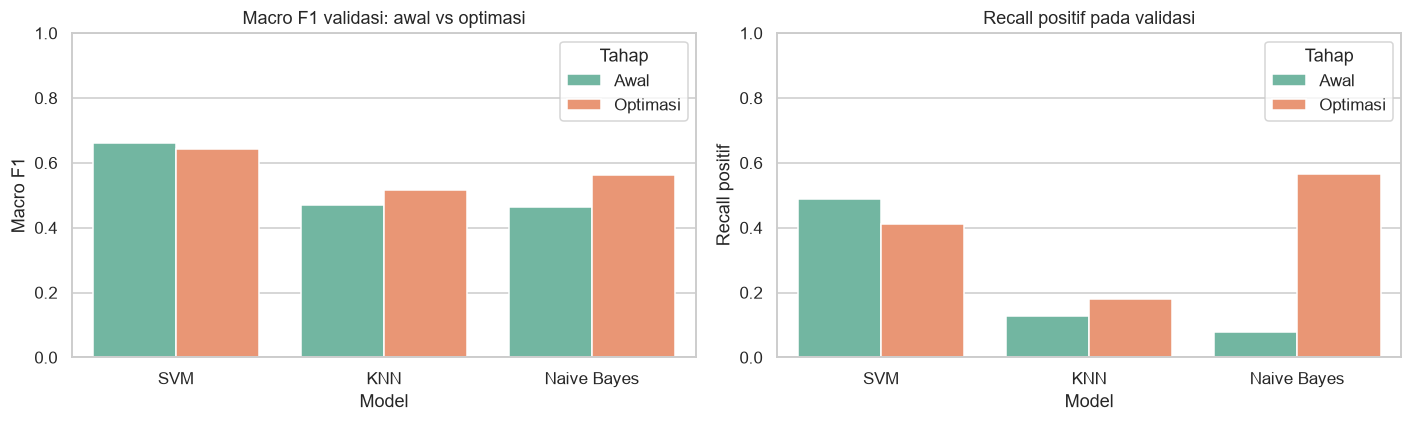

**SVM:** perubahan macro F1 validasi -0.0185. Konfigurasi dipertahankan berdasarkan validasi, bukan karena pencarian lebih luas selalu lebih baik.

**KNN:** perubahan macro F1 validasi +0.0450. Konfigurasi dipertahankan berdasarkan validasi, bukan karena pencarian lebih luas selalu lebih baik.

**Naive Bayes:** perubahan macro F1 validasi +0.0991. Konfigurasi dipertahankan berdasarkan validasi, bukan karena pencarian lebih luas selalu lebih baik.

Pilihan terkunci sebelum audit test lanjutan: **SVM (Awal)**, macro F1 validasi **0.6619**. Nilai ini masih dapat optimistis akibat pemakaian validasi berulang.

In [ ]:
opt_searches={};opt_candidates={};opt_validation_rows=[]
for name,model in opt_models.items():
    print('Optimasi lanjutan:',name,flush=True)
    start=time.perf_counter()
    search=RandomizedSearchCV(optimized_pipeline(clone(model)),opt_spaces[name],n_iter=OPT_N_ITER,scoring='f1_macro',cv=cv,random_state=SEED,n_jobs=1,refit=True,error_score='raise',return_train_score=True)
    search.fit(Xtr,ytr)
    duration=time.perf_counter()-start
    opt_searches[name]=search
    results=pd.DataFrame(search.cv_results_)
    results.to_csv(OPT/'tables'/f'randomized_search_{name.replace(" ","_")}.csv',index=False)
    initial=searches[name].best_estimator_
    candidate_list=[('Awal',initial,searches[name].best_score_,pd.DataFrame(searches[name].cv_results_).loc[searches[name].best_index_,'std_test_score'],searches[name].best_params_,np.nan),
                    ('Optimasi',search.best_estimator_,search.best_score_,results.loc[search.best_index_,'std_test_score'],search.best_params_,duration)]
    for phase,estimator,cv_mean,cv_std,params,elapsed in candidate_list:
        key=(name,phase);opt_candidates[key]=estimator
        start=time.perf_counter();pred=estimator.predict(Xv);prediction_seconds=time.perf_counter()-start
        report=classification_report(yv,pred,labels=CLASSES,output_dict=True,zero_division=0)
        opt_validation_rows.append({'Model':name,'Tahap':phase,'cv_mean':cv_mean,'cv_std':cv_std,**metrics(yv,pred),'positive_recall':report['positif']['recall'],'positive_f1':report['positif']['f1-score'],'search_seconds':elapsed,'prediction_seconds':prediction_seconds,'params':json.dumps(params,default=float)})
    print(name,'CV terbaik:',round(search.best_score_,4),'waktu:',round(duration,1),'detik',flush=True)
opt_validation=pd.DataFrame(opt_validation_rows)
opt_table(opt_validation,'validation_before_after')
opt_selected=opt_validation.sort_values(['f1_macro','cv_mean','Tahap'],ascending=[False,False,True]).drop_duplicates('Model').copy()
opt_table(opt_selected,'selected_per_algorithm')
opt_winner_row=opt_selected.sort_values(['f1_macro','cv_mean','Model'],ascending=[False,False,True]).iloc[0]
opt_winner=opt_winner_row['Model'];opt_phase=opt_winner_row['Tahap']
opt_choice={'winner':opt_winner,'phase':opt_phase,'validation_macro_f1':float(opt_winner_row.f1_macro),'criterion':'validation macro F1, CV tie-break','test_status':'previously exposed; exploratory audit only','n_iter':OPT_N_ITER,'seed':SEED,'params':json.loads(opt_winner_row.params)}
(OPT/'reports/selection_locked.json').write_text(json.dumps(opt_choice,indent=2,ensure_ascii=False),encoding='utf-8')
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.barplot(data=opt_validation,x='Model',y='f1_macro',hue='Tahap',ax=axes[0]);axes[0].set(title='Macro F1 validasi: awal vs optimasi',ylabel='Macro F1',ylim=(0,1))
sns.barplot(data=opt_validation,x='Model',y='positive_recall',hue='Tahap',ax=axes[1]);axes[1].set(title='Recall positif pada validasi',ylabel='Recall positif',ylim=(0,1));opt_figure('validation_before_after')
for name in opt_models:
    part=opt_validation[opt_validation.Model==name].set_index('Tahap')
    delta=part.loc['Optimasi','f1_macro']-part.loc['Awal','f1_macro']
    note(f'**{name}:** perubahan macro F1 validasi {delta:+.4f}. Konfigurasi dipertahankan berdasarkan validasi, bukan karena pencarian lebih luas selalu lebih baik.')
note(f'Pilihan terkunci sebelum audit test lanjutan: **{opt_winner} ({opt_phase})**, macro F1 validasi **{opt_winner_row.f1_macro:.4f}**. Nilai ini masih dapat optimistis akibat pemakaian validasi berulang.')


## 15. Refit, Audit Test Eksploratif, dan Penyimpanan Model Optimasi
**Tujuan:** melatih ulang konfigurasi terpilih tiap algoritma pada training+validation, lalu melaporkan test lama secara eksploratif. Pemenang tidak diubah setelah audit test. Model awal dan laporan awal tetap tersedia; pipeline hasil optimasi disimpan terpisah. Angka test baru tidak dapat diperlakukan sebagai konfirmasi independen setelah studi awal sudah melihat test yang sama.

,kelas,precision,recall,f1-score,support
0,positif,0.418182,0.575000,0.484211,40.000000
1,netral,0.722772,0.690852,0.706452,317.000000
2,negatif,0.802703,0.800539,0.801619,371.000000
3,accuracy,0.740385,0.740385,0.740385,0.740385
4,macro avg,0.647886,0.688797,0.664094,728.000000
5,weighted avg,0.746770,0.740385,0.742740,728.000000


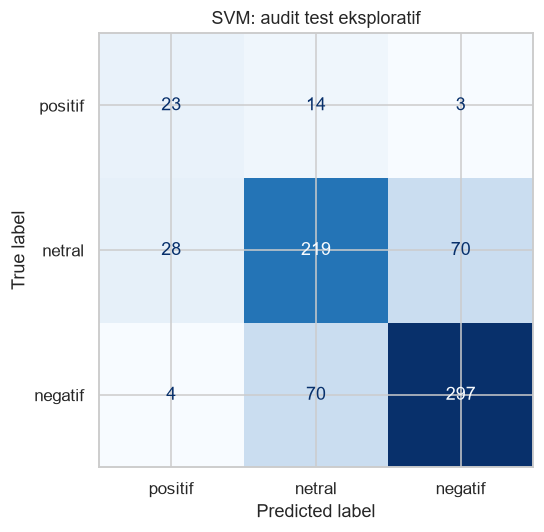

,kelas,precision,recall,f1-score,support
0,positif,0.241379,0.525000,0.330709,40.000000
1,netral,0.679688,0.548896,0.607330,317.000000
2,negatif,0.748052,0.776280,0.761905,371.000000
3,accuracy,0.663462,0.663462,0.663462,0.663462
4,macro avg,0.556373,0.616725,0.566648,728.000000
5,weighted avg,0.690444,0.663462,0.670905,728.000000


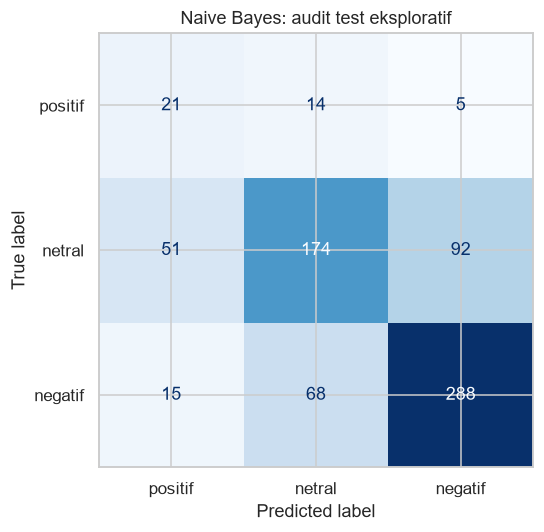

,kelas,precision,recall,f1-score,support
0,positif,0.260870,0.150000,0.190476,40.00000
1,netral,0.517327,0.659306,0.579750,317.00000
2,negatif,0.651163,0.528302,0.583333,371.00000
3,accuracy,0.564560,0.564560,0.564560,0.56456
4,macro avg,0.476453,0.445869,0.451187,728.00000
5,weighted avg,0.571441,0.564560,0.560188,728.00000


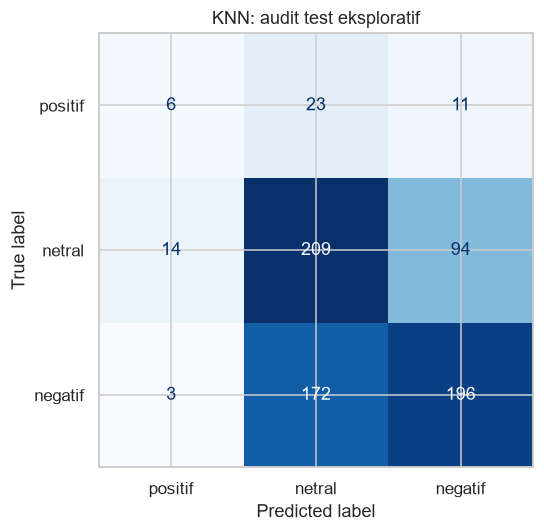

,Model,Tahap terpilih,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,fit_seconds,predict_seconds,Status
0,SVM,Awal,0.740385,0.647886,0.688797,0.664094,0.746770,0.740385,0.742740,0.575,0.484211,0.559262,0.076472,Test lama; eksploratif
1,Naive Bayes,Optimasi,0.663462,0.556373,0.616725,0.566648,0.690444,0.663462,0.670905,0.525,0.330709,3.376395,0.410625,Test lama; eksploratif
2,KNN,Optimasi,0.564560,0.476453,0.445869,0.451187,0.571441,0.564560,0.560188,0.150,0.190476,1.865562,0.578511,Test lama; eksploratif


,source_row,raw_text,label,prediction,Model
0,2094,MBG = Makan Bergizi Gratis ❌ MBG = Mari Bersyu...,negatif,netral,SVM
1,4243,aku yakin pak presiden baik... aku bangga puny...,netral,positif,SVM
2,1218,gw malah setuju idenya pak Ahok yang memberday...,netral,negatif,SVM
3,2784,Gimana kalo diberikan bahan makanan bergizi sa...,netral,negatif,SVM
4,1920,Mungkin buat mereka yg kelas menegah keatas dg...,positif,negatif,SVM
...,...,...,...,...,...
746,1088,Aku jadi kepikiran kalau makan siang gratis in...,negatif,netral,KNN
747,2028,Stuju banget sama pendapatnya ttg saling tuduh...,negatif,netral,KNN
748,2157,Saya sangat setuju dengan apa yang anda sampai...,netral,negatif,KNN
749,782,Program meresahkan anak sekolah dan orangtua.....,netral,negatif,KNN


,kelas,precision,recall,f1-score,support,Model
0,positif,0.418182,0.575000,0.484211,40.0,SVM
1,netral,0.722772,0.690852,0.706452,317.0,SVM
2,negatif,0.802703,0.800539,0.801619,371.0,SVM
3,positif,0.241379,0.525000,0.330709,40.0,Naive Bayes
4,netral,0.679688,0.548896,0.607330,317.0,Naive Bayes
5,negatif,0.748052,0.776280,0.761905,371.0,Naive Bayes
6,positif,0.260870,0.150000,0.190476,40.0,KNN
7,netral,0.517327,0.659306,0.579750,317.0,KNN
8,negatif,0.651163,0.528302,0.583333,371.0,KNN


,Model,accuracy,f1_macro,Tahap
0,SVM,0.740385,0.664094,Awal
1,KNN,0.568681,0.475683,Awal
2,Naive Bayes,0.648352,0.485322,Awal
3,SVM,0.740385,0.664094,Terpilih lanjutan
4,Naive Bayes,0.663462,0.566648,Terpilih lanjutan
5,KNN,0.564560,0.451187,Terpilih lanjutan


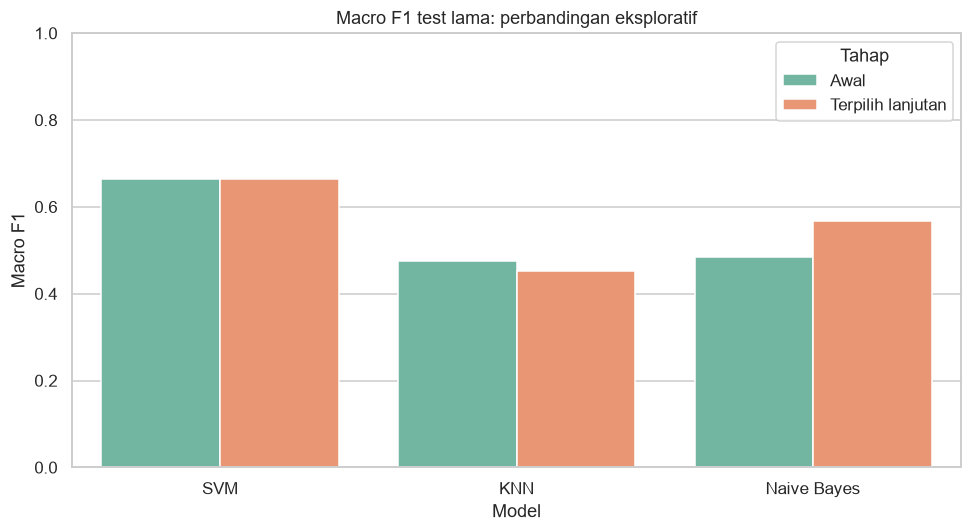

,Komentar,Prediksi Sentimen
0,Program MBG sangat membantu anak sekolah,negatif


In [ ]:
opt_final_models={};opt_predictions={};opt_test_rows=[];opt_reports=[];opt_errors=[]
for row in opt_selected.itertuples(index=False):
    name,phase=row.Model,row.Tahap
    pipeline=clone(opt_candidates[(name,phase)])
    start=time.perf_counter();pipeline.fit(trainval.raw_text,trainval.label);fit_seconds=time.perf_counter()-start
    start=time.perf_counter();pred=pipeline.predict(Xte);predict_seconds=time.perf_counter()-start
    opt_final_models[name]=pipeline;opt_predictions[name]=pred
    report=classification_report(yte,pred,labels=CLASSES,output_dict=True,zero_division=0)
    opt_test_rows.append({'Model':name,'Tahap terpilih':phase,**metrics(yte,pred),'positive_recall':report['positif']['recall'],'positive_f1':report['positif']['f1-score'],'fit_seconds':fit_seconds,'predict_seconds':predict_seconds,'Status':'Test lama; eksploratif'})
    report_frame=pd.DataFrame(report).T
    opt_table(report_frame.rename_axis('kelas').reset_index(),f'classification_report_{name.replace(" ","_")}')
    opt_reports.append(report_frame.loc[CLASSES].rename_axis('kelas').reset_index().assign(Model=name))
    ConfusionMatrixDisplay.from_predictions(yte,pred,labels=CLASSES,cmap='Blues',colorbar=False);plt.title(f'{name}: audit test eksploratif');opt_figure(f'confusion_{name.replace(" ","_")}')
    e=test[['source_row','raw_text','label']].copy();e['prediction']=pred;e['Model']=name
    opt_errors.append(e[e.label!=e.prediction])
    pd.DataFrame({'source_row':test.source_row,'label':yte,'prediction':pred,'Model':name}).to_csv(OPT/'tables'/f'test_predictions_{name.replace(" ","_")}.csv',index=False)
opt_final=pd.DataFrame(opt_test_rows);opt_table(opt_final,'test_exploratory')
opt_table(pd.concat(opt_errors,ignore_index=True),'errors')
opt_table(pd.concat(opt_reports,ignore_index=True),'per_class_metrics')
old_test=final[['Model','accuracy','f1_macro']].assign(Tahap='Awal')
new_test=opt_final[['Model','accuracy','f1_macro']].assign(Tahap='Terpilih lanjutan')
comparison=pd.concat([old_test,new_test],ignore_index=True);opt_table(comparison,'test_before_after_exploratory')
sns.barplot(data=comparison,x='Model',y='f1_macro',hue='Tahap');plt.ylim(0,1);plt.title('Macro F1 test lama: perbandingan eksploratif');plt.ylabel('Macro F1');opt_figure('test_before_after_exploratory')
opt_model_path=OPT/'models/best_pipeline_optimized.joblib'
joblib.dump(opt_final_models[opt_winner],opt_model_path)
opt_loaded=joblib.load(opt_model_path)
opt_demo=pd.DataFrame({'Komentar':new_comments,'Prediksi Sentimen':opt_loaded.predict(new_comments)})
opt_table(opt_demo,'prediction_demo')
assert np.array_equal(opt_loaded.predict(Xte),opt_predictions[opt_winner])


## 16. Ringkasan Optimasi dan Audit
**Tujuan:** menyatakan besar perubahan yang benar-benar diperoleh, tanpa memaksakan kenaikan akurasi. Hasil negatif tetap dilaporkan. Untuk pengembangan berikutnya, prioritaskan audit label kelas positif dan data baru sebelum menambah budget pencarian terus-menerus.

In [ ]:
old_best=float(validation.f1_macro.max())
new_best=float(opt_winner_row.f1_macro)
opt_test_best=opt_final.set_index('Model').loc[opt_winner]
opt_summary=f"""# Hasil Optimasi Lanjutan MBG

Pencarian tambahan memakai RandomizedSearchCV: {OPT_N_ITER} kandidat untuk masing-masing dari tiga algoritma, dengan {len(cv)} fold identik ({OPT_N_ITER*3*len(cv)} fit CV tambahan). Ruang fitur mencakup TF-IDF kata dan karakter, unigram sampai trigram kata, document frequency, batas vocabulary, bobot fitur, stemming, serta parameter classifier dan penanganan prior/bobot kelas.

Macro F1 validasi terbaik awal: **{old_best:.4f}**. Pilihan lanjutan: **{opt_winner} ({opt_phase})**, macro F1 validasi **{new_best:.4f}**, perubahan **{new_best-old_best:+.4f}** (setara {(new_best-old_best)*100:+.2f} poin persentase). Pilihan ini sudah dikunci sebelum audit test lanjutan. Konfigurasi awal boleh tetap menang bila pencarian baru tidak membaik.

Audit pada test lama: accuracy **{opt_test_best.accuracy:.4f}**, macro F1 **{opt_test_best.f1_macro:.4f}**, recall positif **{opt_test_best.positive_recall:.4f}**. Angka ini **eksploratif**, karena test yang sama telah dilihat pada penelitian awal. Jangan mengklaimnya sebagai estimasi independen baru. Dibutuhkan test eksternal yang belum dilihat untuk konfirmasi.

Variasi karakter berpotensi menangani ejaan/slang, tetapi kombinasi fitur dan parameter berubah bersamaan sehingga tidak membuktikan satu penyebab peningkatan. Bobot/prior kelas dapat menambah recall positif sekaligus mengurangi precision; lihat tabel per kelas. Selisih kecil juga belum membuktikan signifikansi. Dataset masih memiliki minoritas positif kecil dan validasi telah dipakai berulang.

Pipeline terbaik disimpan terpisah di `outputs/optimization/models/best_pipeline_optimized.joblib`; pipeline dan laporan awal tidak ditimpa. Seluruh ruang pencarian, kandidat, fold scores, perbandingan validasi, prediksi test, contoh kesalahan, grafik, serta laporan optimasi tersedia di folder `outputs/optimization/`.

Langkah berikutnya: tambah anotasi positif yang representatif, audit kasus salah/ambigu bersama beberapa anotator, validasi pada sumber/waktu baru, serta jalankan nested CV bila sumber daya memadai. Menaikkan OPT_N_ITER memperluas pencarian dan biaya komputasi, tanpa menjamin perbaikan.
"""
(OPT/'reports/optimization_summary.md').write_text(opt_summary,encoding='utf-8')
display(Markdown(opt_summary))
assert opt_choice['winner']==opt_winner
assert len(opt_validation)==6 and len(opt_final)==3
assert all(s.n_splits_==len(cv) and len(s.cv_results_['params'])==OPT_N_ITER for s in opt_searches.values())
assert opt_final.filter(regex='^accuracy$|^f1_|^precision_|^recall_').apply(lambda s:s.between(0,1).all()).all()
assert not list(ROOT.rglob('*.py'))
opt_qa={'status':'PASS','n_iter_per_model':OPT_N_ITER,'cv_folds':len(cv),'total_additional_cv_fits':OPT_N_ITER*3*len(cv),'validation_selected_model':opt_winner,'selected_phase':opt_phase,'validation_macro_f1':new_best,'validation_delta':new_best-old_best,'test_status':'previously exposed; exploratory only','same_split':True,'model_reload_matches_predictions':True,'figures':len(list((OPT/'figures').glob('*.png'))),'tables':len(list((OPT/'tables').glob('*.csv')))}
(OPT/'reports/qa.json').write_text(json.dumps(opt_qa,indent=2),encoding='utf-8')
display(opt_qa)


# Hasil Optimasi Lanjutan MBG

Pencarian tambahan memakai RandomizedSearchCV: 24 kandidat untuk masing-masing dari tiga algoritma, dengan 5 fold identik (360 fit CV tambahan). Ruang fitur mencakup TF-IDF kata dan karakter, unigram sampai trigram kata, document frequency, batas vocabulary, bobot fitur, stemming, serta parameter classifier dan penanganan prior/bobot kelas.

Macro F1 validasi terbaik awal: **0.6619**. Pilihan lanjutan: **SVM (Awal)**, macro F1 validasi **0.6619**, perubahan **+0.0000** (setara +0.00 poin persentase). Pilihan ini sudah dikunci sebelum audit test lanjutan. Konfigurasi awal boleh tetap menang bila pencarian baru tidak membaik.

Audit pada test lama: accuracy **0.7404**, macro F1 **0.6641**, recall positif **0.5750**. Angka ini **eksploratif**, karena test yang sama telah dilihat pada penelitian awal. Jangan mengklaimnya sebagai estimasi independen baru. Dibutuhkan test eksternal yang belum dilihat untuk konfirmasi.

Variasi karakter berpotensi menangani ejaan/slang, tetapi kombinasi fitur dan parameter berubah bersamaan sehingga tidak membuktikan satu penyebab peningkatan. Bobot/prior kelas dapat menambah recall positif sekaligus mengurangi precision; lihat tabel per kelas. Selisih kecil juga belum membuktikan signifikansi. Dataset masih memiliki minoritas positif kecil dan validasi telah dipakai berulang.

Pipeline terbaik disimpan terpisah di `outputs/optimization/models/best_pipeline_optimized.joblib`; pipeline dan laporan awal tidak ditimpa. Seluruh ruang pencarian, kandidat, fold scores, perbandingan validasi, prediksi test, contoh kesalahan, grafik, serta laporan optimasi tersedia di folder `outputs/optimization/`.

Langkah berikutnya: tambah anotasi positif yang representatif, audit kasus salah/ambigu bersama beberapa anotator, validasi pada sumber/waktu baru, serta jalankan nested CV bila sumber daya memadai. Menaikkan OPT_N_ITER memperluas pencarian dan biaya komputasi, tanpa menjamin perbaikan.


{'status': 'PASS',
 'n_iter_per_model': 24,
 'cv_folds': 5,
 'total_additional_cv_fits': 360,
 'validation_selected_model': 'SVM',
 'selected_phase': 'Awal',
 'validation_macro_f1': 0.6618782177510403,
 'validation_delta': 0.0,
 'test_status': 'previously exposed; exploratory only',
 'same_split': True,
 'model_reload_matches_predictions': True,
 'figures': 5,
 'tables': 17}

## 17. Diagnostik Generalisasi dan Audit Mandiri
**Tujuan:** menambahkan selisih macro F1 training–CV untuk setiap kandidat, memeriksa ulang metrik dari file prediksi, serta memuat pipeline di proses/kernel baru. Selisih training–CV adalah diagnostik, bukan kriteria pemilihan tambahan. Pada KNN, skor training dapat optimistis karena sampel ikut menjadi tetangganya sendiri, terutama dengan distance weights. Nilai gap tidak membuktikan penyebab kesalahan dan tidak menggantikan evaluasi held-out.

Sel ini dapat dijalankan mandiri setelah keluaran optimasi tersedia. Ringkasan pemilihan tetap mengacu pada macro F1 validasi yang sudah dikunci sebelum audit test eksploratif.

,Model,Train Macro F1,CV Macro F1,CV SD,Train-CV Gap
0,SVM,0.919787,0.679887,0.025550,0.239900
1,KNN,0.701059,0.507844,0.018512,0.193215
2,Naive Bayes,0.764369,0.561848,0.009935,0.202520


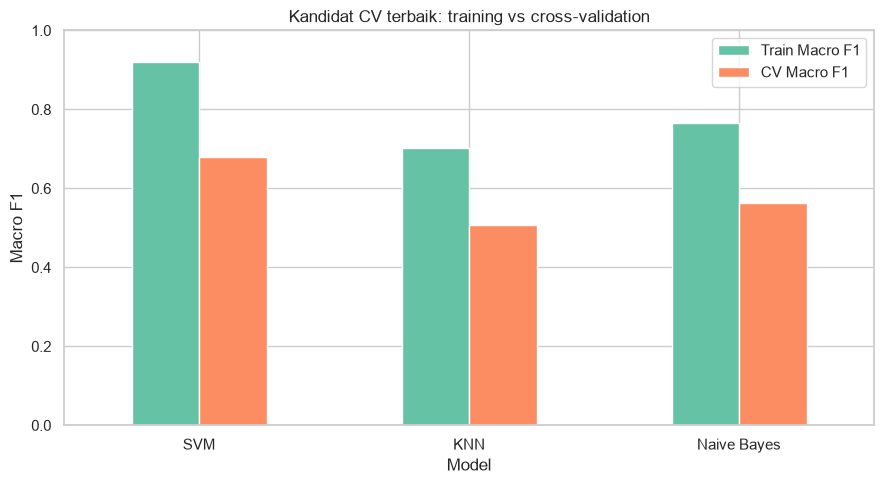

Gap yang besar perlu diperiksa bersama kurva pembelajaran, jumlah data, dan validasi. Skor training KNN cenderung optimistis karena self-neighbor; gunakan skor held-out untuk menilai generalisasi.

Tahap,Awal,Optimasi,Delta validasi
Model,,,
KNN,0.470781,0.515787,0.045006
Naive Bayes,0.464692,0.563812,0.099119
SVM,0.661878,0.643400,-0.018478


{'status': 'PASS',
 'n_iter_per_model': 24,
 'cv_folds': 5,
 'total_additional_cv_fits': 360,
 'validation_selected_model': 'SVM',
 'selected_phase': 'Awal',
 'validation_macro_f1': 0.6618782177510403,
 'validation_delta': 0.0,
 'test_status': 'previously exposed; exploratory only',
 'same_split': True,
 'model_reload_matches_predictions': True,
 'figures': 6,
 'tables': 19,
 'fresh_kernel_model_reload': 'PASS',
 'all_saved_test_metrics_recomputed': 'PASS',
 'split_leakage_check': 'PASS',
 'source_py_files': 0}

Audit optimasi lulus: metrik aktual, split konsisten, pipeline dapat dimuat mandiri.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display, Markdown
DIAG_ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'MBG-Sentiment-Research'] if (p/'dataset/MBG-label.csv').exists())
DIAG_OPT=DIAG_ROOT/'outputs/optimization'
gap_summaries=[];gap_candidates=[]
for diag_name in ['SVM','KNN','Naive Bayes']:
    diag_path=DIAG_OPT/'tables'/f'randomized_search_{diag_name.replace(" ","_")}.csv'
    candidates=pd.read_csv(diag_path)
    candidates['train_cv_gap']=candidates.mean_train_score-candidates.mean_test_score
    candidates.to_csv(diag_path,index=False)
    candidates['Model']=diag_name
    candidates['Kandidat']=np.arange(1,len(candidates)+1)
    gap_candidates.append(candidates[['Model','Kandidat','mean_train_score','mean_test_score','std_test_score','train_cv_gap','mean_fit_time','rank_test_score']])
    top=candidates.loc[candidates.mean_test_score.idxmax()]
    gap_summaries.append({'Model':diag_name,'Train Macro F1':top.mean_train_score,'CV Macro F1':top.mean_test_score,'CV SD':top.std_test_score,'Train-CV Gap':top.train_cv_gap})
gap_summary=pd.DataFrame(gap_summaries)
gap_summary.to_csv(DIAG_OPT/'tables/generalization_gap_summary.csv',index=False)
pd.concat(gap_candidates,ignore_index=True).to_csv(DIAG_OPT/'tables/tuning_generalization_gap.csv',index=False)
display(gap_summary)
sns.set_theme(style='whitegrid',palette='Set2')
gap_summary.set_index('Model')[['Train Macro F1','CV Macro F1']].plot.bar(rot=0,ylim=(0,1),figsize=(9,5),title='Kandidat CV terbaik: training vs cross-validation',ylabel='Macro F1',xlabel='Model')
plt.tight_layout();plt.savefig(DIAG_OPT/'figures/train_cv_gap.png',dpi=160,bbox_inches='tight');plt.show();plt.close()
display(Markdown('Gap yang besar perlu diperiksa bersama kurva pembelajaran, jumlah data, dan validasi. Skor training KNN cenderung optimistis karena self-neighbor; gunakan skor held-out untuk menilai generalisasi.'))
# Verifikasi semua metrik dari prediksi tersimpan, tanpa memilih parameter ulang.
diag_scores=pd.read_csv(DIAG_OPT/'tables/test_exploratory.csv')
for record in diag_scores.itertuples(index=False):
    pred_file=DIAG_OPT/'tables'/f'test_predictions_{record.Model.replace(" ","_")}.csv'
    stored=pd.read_csv(pred_file)
    assert np.isclose(accuracy_score(stored.label,stored.prediction),record.accuracy)
    for average in ['macro','weighted']:
        precision,recall,f1,_=precision_recall_fscore_support(stored.label,stored.prediction,labels=['positif','netral','negatif'],average=average,zero_division=0)
        assert np.isclose(precision,getattr(record,'precision_'+average))
        assert np.isclose(recall,getattr(record,'recall_'+average))
        assert np.isclose(f1,getattr(record,'f1_'+average))
diag_choice=json.loads((DIAG_OPT/'reports/selection_locked.json').read_text(encoding='utf-8'))
diag_loaded=joblib.load(DIAG_OPT/'models/best_pipeline_optimized.joblib')
diag_manifest=pd.read_csv(DIAG_ROOT/'outputs/tables/split_manifest.csv')
diag_test=diag_manifest[diag_manifest.subset=='Testing']
for subset_a,subset_b in [('Training','Validation'),('Training','Testing'),('Validation','Testing')]:
    a=diag_manifest[diag_manifest.subset==subset_a];b=diag_manifest[diag_manifest.subset==subset_b]
    for key in ['source_row','raw_key','final_text']:assert not set(a[key])&set(b[key])
diag_pred=diag_loaded.predict(diag_test.raw_text)
diag_stored=pd.read_csv(DIAG_OPT/'tables'/f'test_predictions_{diag_choice["winner"].replace(" ","_")}.csv').set_index('source_row')
assert np.array_equal(diag_pred,diag_stored.loc[diag_test.source_row,'prediction'].to_numpy())
assert not list(DIAG_ROOT.rglob('*.py'))
diag_validation=pd.read_csv(DIAG_OPT/'tables/validation_before_after.csv')
diag_deltas=diag_validation.pivot(index='Model',columns='Tahap',values='f1_macro')
diag_deltas['Delta validasi']=diag_deltas.Optimasi-diag_deltas.Awal
display(diag_deltas)
diag_qa=json.loads((DIAG_OPT/'reports/qa.json').read_text(encoding='utf-8'))
diag_qa.update({'fresh_kernel_model_reload':'PASS','all_saved_test_metrics_recomputed':'PASS','split_leakage_check':'PASS','source_py_files':0,'figures':len(list((DIAG_OPT/'figures').glob('*.png'))),'tables':len(list((DIAG_OPT/'tables').glob('*.csv')))})
(DIAG_OPT/'reports/qa.json').write_text(json.dumps(diag_qa,indent=2),encoding='utf-8')
display(diag_qa)
print('Audit optimasi lulus: metrik aktual, split konsisten, pipeline dapat dimuat mandiri.')

# Perbarui checksum setelah semua keluaran optimasi selesai dibuat.
import hashlib
artifact_rows=[{'path':str(p.relative_to(DIAG_ROOT)),'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in (DIAG_ROOT/'outputs').rglob('*') if p.is_file() and p.name!='artifact_manifest.csv']
pd.DataFrame(artifact_rows).to_csv(DIAG_ROOT/'outputs/reports/artifact_manifest.csv',index=False)


## 18. Optimasi dengan Sasaran Accuracy >70% untuk Ketiga Algoritma
**Perubahan tujuan:** bagian ini memakai **accuracy** sebagai metrik utama CV dan pemilihan pada validasi, sesuai tujuan lanjutan pengguna. Penelitian awal berbasis macro F1 tetap tersedia sebagai eksperimen terpisah. Target >70% adalah sasaran eksperimen, bukan angka yang boleh dipaksakan atau jaminan hasil. Macro F1 dan recall positif tetap dilaporkan untuk mengungkap trade-off kelas minoritas.

**Eksperimen:** SVM dituning ulang untuk accuracy; MultinomialNB membandingkan CountVectorizer, binary counts, dan TF-IDF dengan seleksi fitur chi-square. KNN membandingkan ruang sparse, latent semantic analysis melalui TruncatedSVD, serta SVD + proyeksi LDA. Pada varian terakhir **LDA adalah ekstraktor fitur terawasi**, sedangkan classifier akhirnya tetap KNN; hasilnya harus ditulis sebagai KNN dengan proyeksi SVD–LDA, bukan disamakan dengan KNN TF-IDF polos. Semua seleksi fitur, SVD, dan LDA di-fit di dalam training fold. Tidak ada fitting transformasi terawasi pada validasi atau test.

**Protokol:** split 70/15/15 dan fold tetap sama. Pencarian memakai scoring accuracy dan macro F1, dengan refit accuracy. Kandidat terbaik CV dibandingkan dengan konfigurasi historis pada validasi. Setelah keputusan dikunci, ketiga model di-refit pada training+validation dan diaudit pada test lama secara eksploratif. Target diperiksa secara terpisah pada validasi dan test; tidak ada perubahan parameter berdasarkan test. Karena validasi/test telah digunakan pada eksperimen sebelumnya, konfirmasi independen tetap memerlukan dataset baru.

Untuk menjalankan bagian ini tanpa mengulang pencarian historis, jalankan sel import pada bagian 1 lalu bagian 18–21; file split dan tabel hasil historis harus sudah tersedia. Sel setup memeriksa kembali identitas data sumber.


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.decomposition import TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from scipy.stats import loguniform
from threadpoolctl import threadpool_limits
import copyreg
ACC=OUT/'accuracy_optimization'
for folder in ['figures','tables','models','reports']:(ACC/folder).mkdir(parents=True,exist_ok=True)
# Semua definisi preprocessing tetap bersumber dari code cell notebook ini.
if 'stages' not in globals():
    import nbformat
    source_notebook=nbformat.read(ROOT/'notebooks/MBG_Sentiment_Analysis.ipynb',as_version=4)
    preprocessing_source=next(c.source for c in source_notebook.cells if c.id=='cell-007')
    exec(preprocessing_source.split('records=')[0],globals())
def accuracy_preprocess(texts,mode='normalized'):
    if mode=='keep_stopwords':return [' '.join(stages(str(text),False)[3]) for text in texts]
    return [stages(str(text),mode=='stemmed')[-1] for text in texts]
def acc_restore_cached(function,parameters):return lru_cache(**parameters)(function)
def acc_reduce_cached(function):return acc_restore_cached,(function.__wrapped__,function.cache_parameters())
copyreg.pickle(type(stages),acc_reduce_cached)
acc_manifest=pd.read_csv(OUT/'tables/split_manifest.csv')
acc_raw=pd.read_csv(ROOT/'dataset/MBG-label.csv')
assert len(acc_raw)==json.loads((OUT/'reports/qa.json').read_text())['dataset_rows'],'Dataset berubah: jalankan ulang persiapan dan split.'
source_records=acc_raw.iloc[acc_manifest.source_row.to_numpy()-2]
assert np.array_equal(source_records['comment'].astype(str).str.replace(r'\s+',' ',regex=True).str.strip().to_numpy(),acc_manifest.raw_text.to_numpy())
assert np.array_equal(source_records['sentiment'].astype(str).str.strip().str.lower().to_numpy(),acc_manifest.label.to_numpy())
for sa,sb in [('Training','Validation'),('Training','Testing'),('Validation','Testing')]:
    a=acc_manifest[acc_manifest.subset==sa];b=acc_manifest[acc_manifest.subset==sb]
    for key in ['source_row','raw_key','final_text']:assert not set(a[key])&set(b[key])
acc_train=acc_manifest[acc_manifest.subset=='Training'].copy()
acc_valid=acc_manifest[acc_manifest.subset=='Validation'].copy()
acc_test=acc_manifest[acc_manifest.subset=='Testing'].copy()
acc_trainval=pd.concat([acc_train,acc_valid],ignore_index=True)
acc_cv=list(StratifiedKFold(n_splits=min(5,int(acc_train.label.value_counts().min())),shuffle=True,random_state=SEED).split(acc_train.raw_text,acc_train.label))
ACC_SCORING={'accuracy':'accuracy','f1_macro':'f1_macro'}
ACC_BUDGET={'SVM':20,'Naive Bayes':40,'KNN_per_branch':12}
def acc_table(frame,name):frame.to_csv(ACC/'tables'/f'{name}.csv',index=False);display(frame)
def acc_figure(name):
    plt.tight_layout();plt.savefig(ACC/'figures'/f'{name}.png',dpi=160,bbox_inches='tight');plt.show();plt.close()
def acc_metrics(y,pred):
    values={'accuracy':accuracy_score(y,pred)}
    for average in ['macro','weighted']:
        p,r,f,_=precision_recall_fscore_support(y,pred,labels=CLASSES,average=average,zero_division=0)
        values.update({f'precision_{average}':p,f'recall_{average}':r,f'f1_{average}':f})
    rep=classification_report(y,pred,labels=CLASSES,output_dict=True,zero_division=0)
    values.update({'positive_recall':rep['positif']['recall'],'positive_f1':rep['positif']['f1-score']})
    return values
def acc_vectorizer(kind):
    if kind=='word_uni':return TfidfVectorizer(ngram_range=(1,1),max_features=15000,sublinear_tf=True)
    if kind=='word_bi':return TfidfVectorizer(ngram_range=(1,2),max_features=20000,sublinear_tf=True)
    if kind=='char':return TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),max_features=20000,min_df=2,sublinear_tf=True)
    if kind=='count_uni':return CountVectorizer(ngram_range=(1,1),max_features=20000,min_df=2)
    if kind=='count_bi':return CountVectorizer(ngram_range=(1,2),max_features=20000,min_df=2)
    if kind=='binary_bi':return CountVectorizer(ngram_range=(1,2),max_features=20000,min_df=2,binary=True)
    raise ValueError(kind)
acc_modes=[{'mode':'normalized'},{'mode':'stemmed'},{'mode':'keep_stopwords'}]
acc_classifiers={'SVM':LinearSVC(random_state=SEED,max_iter=30000),'KNN':KNeighborsClassifier(algorithm='brute',n_jobs=1),'Naive Bayes':MultinomialNB()}
def acc_base(model):
    # Fungsi biasa selama tuning: cache deterministik dibagi tanpa serialisasi berulang.
    # Wrapper by-value dipasang pada pipeline final ketika disimpan.
    return Pipeline([('preprocess',FunctionTransformer(accuracy_preprocess,kw_args={'mode':'normalized'})),('features',acc_vectorizer('word_bi')),('select',SelectKBest(chi2,k='all')),('reduce','passthrough'),('projection','passthrough'),('normalize','passthrough'),('model',clone(model))])
acc_shared={'preprocess__kw_args':acc_modes,'select__k':['all',300,1000,3000]}
acc_spaces={
 'SVM':{**acc_shared,'features':[acc_vectorizer(k) for k in ['word_uni','word_bi','char']],'model__C':loguniform(.005,20),'model__class_weight':[None,'balanced']},
 'Naive Bayes':{**acc_shared,'features':[acc_vectorizer(k) for k in ['count_uni','count_bi','binary_bi','word_uni','word_bi','char']],'model__alpha':loguniform(.0001,10),'model__fit_prior':[True,False]}
}
acc_knn_shared={**acc_shared,'features':[acc_vectorizer(k) for k in ['word_uni','word_bi','char']],'model__n_neighbors':[1,3,5,7,11,21,41,81],'model__weights':['uniform','distance'],'model__metric':['cosine','euclidean']}
acc_knn_spaces={
 'Sparse':{**acc_knn_shared,'normalize':[Normalizer()]},
 'SVD':{**acc_knn_shared,'select__k':['all',1000,3000],'reduce':[TruncatedSVD(n_components=d,n_iter=5,random_state=SEED) for d in [32,64,128,256]],'normalize':[Normalizer()]},
 'SVD_LDA':{**acc_knn_shared,'select__k':['all',1000,3000],'reduce':[TruncatedSVD(n_components=d,n_iter=5,random_state=SEED) for d in [32,64,128]],'projection':[LinearDiscriminantAnalysis(solver='eigen',shrinkage='auto',n_components=2)],'normalize':['passthrough',Normalizer()]}
}
space_rows=[]
for name,space in list(acc_spaces.items())+[(f'KNN {branch}',sp) for branch,sp in acc_knn_spaces.items()]:
    for parameter,options in space.items():
        description='loguniform(0.005,20)' if parameter=='model__C' else 'loguniform(0.0001,10)' if parameter=='model__alpha' else str(options)
        space_rows.append({'Model/varian':name,'Parameter':parameter,'Pilihan':description})
acc_table(pd.DataFrame(space_rows),'search_space')
print('Budget kandidat baru:',ACC_BUDGET['SVM']+ACC_BUDGET['Naive Bayes']+3*ACC_BUDGET['KNN_per_branch'])


,Model/varian,Parameter,Pilihan
0,SVM,preprocess__kw_args,"[{'mode': 'normalized'}, {'mode': 'stemmed'}, ..."
1,SVM,select__k,"['all', 300, 1000, 3000]"
2,SVM,features,"[TfidfVectorizer(max_features=15000, sublinear..."
3,SVM,model__C,"loguniform(0.005,20)"
4,SVM,model__class_weight,"[None, 'balanced']"
5,Naive Bayes,preprocess__kw_args,"[{'mode': 'normalized'}, {'mode': 'stemmed'}, ..."
6,Naive Bayes,select__k,"['all', 300, 1000, 3000]"
7,Naive Bayes,features,"[CountVectorizer(max_features=20000, min_df=2)..."
8,Naive Bayes,model__alpha,"loguniform(0.0001,10)"
9,Naive Bayes,model__fit_prior,"[True, False]"


Budget kandidat baru: 96


## 19. Tuning Accuracy pada Fold Training yang Sama
**Tujuan:** memilih satu kandidat baru per algoritma dari CV accuracy. Pada KNN, ketiga cabang fitur mendapat budget yang sama; pemenang cabang dipilih berdasarkan CV sebelum melihat validasi. Konfigurasi historis juga dibandingkan ulang dengan CV accuracy, sehingga kandidat lama yang masih unggul tidak hilang. Validasi dipakai untuk memilih konfigurasi final tiap algoritma. Skor test tidak digunakan di sini.

Accuracy tuning: SVM Randomized kandidat: 20


SVM Randomized CV accuracy: 0.8149 detik: 88.2


,Model,Branch,cv_accuracy,cv_std,cv_f1_macro,seconds
0,SVM,Randomized,0.814857,0.011884,0.673333,88.228087


Accuracy tuning: Naive Bayes Randomized kandidat: 40


Naive Bayes Randomized CV accuracy: 0.6492 detik: 55.7


...

Accuracy tuning: KNN SVD_LDA kandidat: 12


KNN SVD_LDA CV accuracy: 0.6633 detik: 30.9


,Model,Branch,cv_accuracy,cv_std,cv_f1_macro,seconds
1,KNN,SVD,0.703117,0.020343,0.640381,47.312068
0,KNN,Sparse,0.676916,0.061819,0.462672,13.078972
2,KNN,SVD_LDA,0.663331,0.014077,0.593139,30.949688


,Model,Varian,cv_accuracy,cv_std,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,predict_seconds,parameters
0,SVM,Historis Awal,0.749706,0.014230,0.751032,0.654080,0.671243,0.661878,0.753902,0.751032,0.752328,0.487179,0.452381,0.213569,"{""model__C"": 0.1, ""model__class_weight"": ""bala..."
1,SVM,Historis Optimasi,0.755309,0.017190,0.748281,0.640937,0.646042,0.643400,0.749094,0.748281,0.748666,0.410256,0.400000,0.186202,"{""features__character__max_features"": 10000, ""..."
2,SVM,Accuracy Randomized,0.814857,0.011884,0.807428,0.682987,0.648882,0.661671,0.799752,0.807428,0.802297,0.282051,0.333333,0.150567,"{""features"": ""TfidfVectorizer(analyzer='char_w..."
3,KNN,Historis Awal,0.597581,0.024262,0.587345,0.640714,0.458164,0.470781,0.615325,0.587345,0.575383,0.128205,0.217391,0.072957,"{""model__metric"": ""cosine"", ""model__n_neighbor..."
4,KNN,Historis Optimasi,0.586375,0.015019,0.625860,0.601078,0.497088,0.515787,0.631197,0.625860,0.619064,0.179487,0.269231,0.219028,"{""preprocess__kw_args"": {""stem"": false}, ""mode..."
5,KNN,Accuracy SVD,0.703117,0.020343,0.700138,0.582827,0.524037,0.531710,0.692028,0.700138,0.690980,0.102564,0.156863,0.173942,"{""select__k"": 3000, ""reduce"": ""TruncatedSVD(n_..."
6,Naive Bayes,Historis Awal,0.634439,0.011385,0.632737,0.592476,0.459201,0.464692,0.630273,0.632737,0.609793,0.076923,0.133333,0.040316,"{""model__alpha"": 0.01, ""preprocess__kw_args"": ..."
7,Naive Bayes,Historis Optimasi,0.643575,0.008229,0.654746,0.554781,0.622113,0.563812,0.685868,0.654746,0.662202,0.564103,0.341085,0.123077,"{""features__character__max_features"": 5000, ""f..."
8,Naive Bayes,Accuracy Randomized,0.649177,0.015611,0.672627,0.598833,0.519524,0.535988,0.666106,0.672627,0.659058,0.179487,0.254545,0.116382,"{""features"": ""TfidfVectorizer(analyzer='char_w..."


,Model,Varian,cv_accuracy,cv_std,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,predict_seconds,parameters,Target validasi >70%
2,SVM,Accuracy Randomized,0.814857,0.011884,0.807428,0.682987,0.648882,0.661671,0.799752,0.807428,0.802297,0.282051,0.333333,0.150567,"{""features"": ""TfidfVectorizer(analyzer='char_w...",True
5,KNN,Accuracy SVD,0.703117,0.020343,0.700138,0.582827,0.524037,0.531710,0.692028,0.700138,0.690980,0.102564,0.156863,0.173942,"{""select__k"": 3000, ""reduce"": ""TruncatedSVD(n_...",True
8,Naive Bayes,Accuracy Randomized,0.649177,0.015611,0.672627,0.598833,0.519524,0.535988,0.666106,0.672627,0.659058,0.179487,0.254545,0.116382,"{""features"": ""TfidfVectorizer(analyzer='char_w...",False


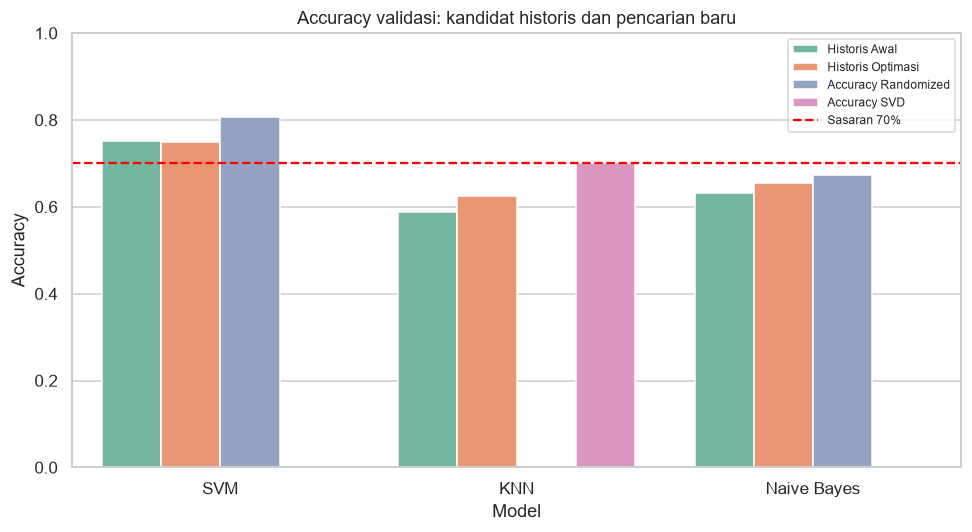

**SVM: Accuracy Randomized**, accuracy validasi **80.74%**, macro F1 **0.6617**, recall positif **28.21%**.

**KNN: Accuracy SVD**, accuracy validasi **70.01%**, macro F1 **0.5317**, recall positif **10.26%**.

**Naive Bayes: Accuracy Randomized**, accuracy validasi **67.26%**, macro F1 **0.5360**, recall positif **17.95%**.

In [ ]:
acc_searches={};acc_new_best={};acc_candidates={};acc_validation_rows=[]
for name in ['SVM','Naive Bayes','KNN']:
    branches=acc_knn_spaces if name=='KNN' else {'Randomized':acc_spaces[name]}
    branch_scores=[]
    for branch,space in branches.items():
        budget=ACC_BUDGET['KNN_per_branch'] if name=='KNN' else ACC_BUDGET[name]
        print('Accuracy tuning:',name,branch,'kandidat:',budget,flush=True)
        start=time.perf_counter()
        search=RandomizedSearchCV(acc_base(acc_classifiers[name]),space,n_iter=budget,scoring=ACC_SCORING,refit='accuracy',cv=acc_cv,random_state=SEED,n_jobs=1,error_score='raise',return_train_score=False)
        with threadpool_limits(limits=2):search.fit(acc_train.raw_text,acc_train.label)
        duration=time.perf_counter()-start
        result=pd.DataFrame(search.cv_results_);result['branch']=branch
        result.to_csv(ACC/'tables'/f'tuning_{name.replace(" ","_")}_{branch}.csv',index=False)
        search.accuracy_branch_=branch
        acc_searches[(name,branch)]=search
        branch_scores.append({'Model':name,'Branch':branch,'cv_accuracy':search.best_score_,'cv_std':result.loc[search.best_index_,'std_test_accuracy'],'cv_f1_macro':result.loc[search.best_index_,'mean_test_f1_macro'],'seconds':duration})
        print(name,branch,'CV accuracy:',round(search.best_score_,4),'detik:',round(duration,1),flush=True)
    branch_table=pd.DataFrame(branch_scores).sort_values(['cv_accuracy','cv_f1_macro','Branch'],ascending=[False,False,True])
    acc_table(branch_table,f'branches_{name.replace(" ","_")}')
    selected_branch=branch_table.iloc[0].Branch
    acc_new_best[name]=acc_searches[(name,selected_branch)]
# Konfigurasi awal dan optimasi macro F1 dibangun ulang persis dari metadata historis.
# Plain callable membuat clone selama CV tidak menggandakan cache preprocessing.
def acc_historical_pipeline(name,params):
    historical=dict(params)
    old_kw=historical.pop('preprocess__kw_args',{'stem':True})
    mode='stemmed' if old_kw['stem'] else 'normalized'
    for key,value in list(historical.items()):
        if key.endswith('ngram_range'):historical[key]=tuple(value)
    if any(key.startswith('features__') for key in historical):
        features=FeatureUnion([('word',TfidfVectorizer(max_features=10000,ngram_range=(1,2),sublinear_tf=True)),('character',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),max_features=10000,sublinear_tf=True))],transformer_weights={'word':1.0,'character':.5})
        pipeline=Pipeline([('preprocess',FunctionTransformer(accuracy_preprocess,kw_args={'mode':mode})),('features',features),('normalize',Normalizer()),('model',clone(acc_classifiers[name]))])
    else:
        pipeline=Pipeline([('preprocess',FunctionTransformer(accuracy_preprocess,kw_args={'mode':mode})),('tfidf',TfidfVectorizer(max_features=10000,min_df=1,max_df=1.,sublinear_tf=True)),('model',clone(acc_classifiers[name]))])
    return pipeline.set_params(**historical)
history=pd.read_csv(OUT/'optimization/tables/validation_before_after.csv')
for name in ['SVM','KNN','Naive Bayes']:
    candidate_definitions=[]
    for record in history[history.Model==name].itertuples(index=False):
        pipeline=acc_historical_pipeline(name,json.loads(record.params))
        with threadpool_limits(limits=2):
            scores=cross_validate(pipeline,acc_train.raw_text,acc_train.label,cv=acc_cv,scoring=ACC_SCORING,n_jobs=1,error_score='raise')
            pipeline.fit(acc_train.raw_text,acc_train.label)
        candidate_definitions.append(('Historis '+record.Tahap,pipeline,float(np.mean(scores['test_accuracy'])),float(np.std(scores['test_accuracy'])),json.loads(record.params)))
    search=acc_new_best[name];res=pd.DataFrame(search.cv_results_)
    candidate_definitions.append(('Accuracy '+search.accuracy_branch_,search.best_estimator_,search.best_score_,float(res.loc[search.best_index_,'std_test_accuracy']),search.best_params_))
    for variant,pipeline,cv_score,cv_std,parameters in candidate_definitions:
        acc_candidates[(name,variant)]=pipeline
        start=time.perf_counter()
        with threadpool_limits(limits=2):pred=pipeline.predict(acc_valid.raw_text)
        acc_validation_rows.append({'Model':name,'Varian':variant,'cv_accuracy':cv_score,'cv_std':cv_std,**acc_metrics(acc_valid.label,pred),'predict_seconds':time.perf_counter()-start,'parameters':json.dumps(parameters,default=str)})
acc_validation=pd.DataFrame(acc_validation_rows)
acc_table(acc_validation,'validation_candidates')
acc_selected=acc_validation.sort_values(['accuracy','cv_accuracy','f1_macro','Varian'],ascending=[False,False,False,True]).drop_duplicates('Model').copy()
acc_selected['Target validasi >70%']=acc_selected.accuracy.gt(.70)
acc_table(acc_selected,'selected_per_algorithm')
acc_locked={'criterion':'validation accuracy; CV accuracy and macro F1 tie-break','seed':SEED,'target':'strictly greater than 0.70','test_status':'previously exposed; exploratory only','models':acc_selected[['Model','Varian','accuracy','cv_accuracy','parameters']].to_dict(orient='records')}
(ACC/'reports/selection_locked.json').write_text(json.dumps(acc_locked,indent=2,ensure_ascii=False),encoding='utf-8')
sns.barplot(data=acc_validation,x='Model',y='accuracy',hue='Varian');plt.axhline(.70,color='red',ls='--',label='Sasaran 70%');plt.ylim(0,1);plt.title('Accuracy validasi: kandidat historis dan pencarian baru');plt.ylabel('Accuracy');plt.legend(fontsize=8);acc_figure('validation_accuracy')
for row in acc_selected.itertuples(index=False):note(f'**{row.Model}: {row.Varian}**, accuracy validasi **{row.accuracy:.2%}**, macro F1 **{row.f1_macro:.4f}**, recall positif **{row.positive_recall:.2%}**.')


## 20. Refit dan Audit Test Eksploratif untuk Sasaran Accuracy
**Tujuan:** melatih ulang pilihan terkunci pada training+validation, menyimpan pipeline lengkap masing-masing algoritma, serta menghitung test satu kali pada bagian ini. Keberhasilan target dilaporkan dari hasil aktual; test yang sudah digunakan sebelumnya tetap eksploratif. Tidak ada pencarian ulang berdasarkan test, perubahan label, penghapusan contoh sulit, atau pemilihan seed untuk mencapai angka target.

,kelas,precision,recall,f1-score,support
0,positif,0.461538,0.300000,0.363636,40.000000
1,netral,0.816720,0.801262,0.808917,317.000000
2,negatif,0.859335,0.905660,0.881890,371.000000
3,accuracy,0.826923,0.826923,0.826923,0.826923
4,macro avg,0.712531,0.668974,0.684814,728.000000
5,weighted avg,0.818922,0.826923,0.821639,728.000000


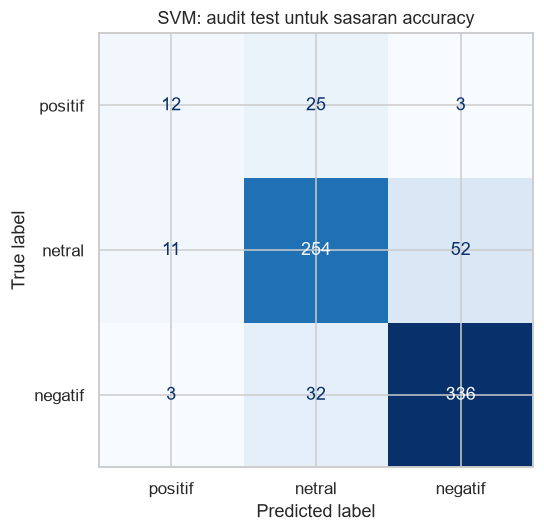

,kelas,precision,recall,f1-score,support
0,positif,0.464286,0.325000,0.382353,40.000000
1,netral,0.661972,0.741325,0.699405,317.000000
2,negatif,0.773913,0.719677,0.745810,371.000000
3,accuracy,0.707418,0.707418,0.707418,0.707418
4,macro avg,0.633390,0.595334,0.609189,728.000000
5,weighted avg,0.708157,0.707418,0.705633,728.000000


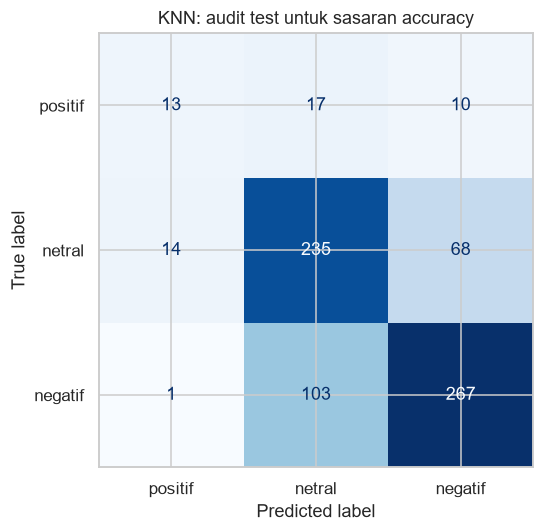

,kelas,precision,recall,f1-score,support
0,positif,0.533333,0.200000,0.290909,40.000000
1,netral,0.675472,0.564669,0.615120,317.000000
2,negatif,0.683036,0.824798,0.747253,371.000000
3,accuracy,0.677198,0.677198,0.677198,0.677198
4,macro avg,0.630614,0.529822,0.551094,728.000000
5,weighted avg,0.671517,0.677198,0.664643,728.000000


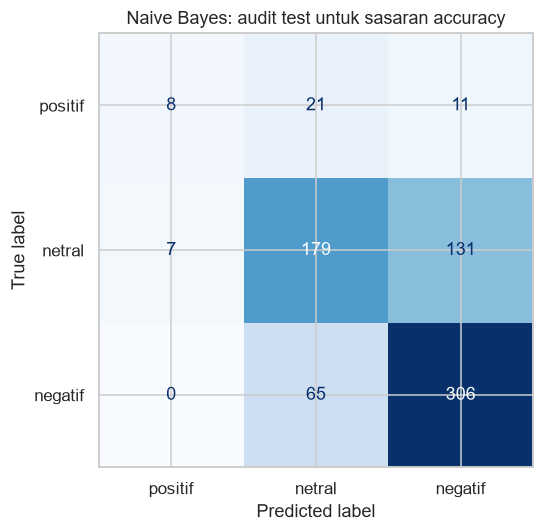

,Model,Varian,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,fit_seconds,predict_seconds,test_status,Target test >70%
0,SVM,Accuracy Randomized,0.826923,0.712531,0.668974,0.684814,0.818922,0.826923,0.821639,0.300,0.363636,1.031957,0.192827,Eksploratif; test sebelumnya sudah dilihat,True
1,KNN,Accuracy SVD,0.707418,0.633390,0.595334,0.609189,0.708157,0.707418,0.705633,0.325,0.382353,1.452135,0.186087,Eksploratif; test sebelumnya sudah dilihat,True
2,Naive Bayes,Accuracy Randomized,0.677198,0.630614,0.529822,0.551094,0.671517,0.677198,0.664643,0.200,0.290909,0.644898,0.299453,Eksploratif; test sebelumnya sudah dilihat,False


,Model,Varian,validation_accuracy,validation_macro_f1,validation_positive_recall,test_accuracy,test_macro_f1,test_positive_recall,validation_target_met,test_target_met
0,SVM,Accuracy Randomized,0.807428,0.661671,0.282051,0.826923,0.684814,0.300,True,True
1,KNN,Accuracy SVD,0.700138,0.531710,0.102564,0.707418,0.609189,0.325,True,True
2,Naive Bayes,Accuracy Randomized,0.672627,0.535988,0.179487,0.677198,0.551094,0.200,False,False


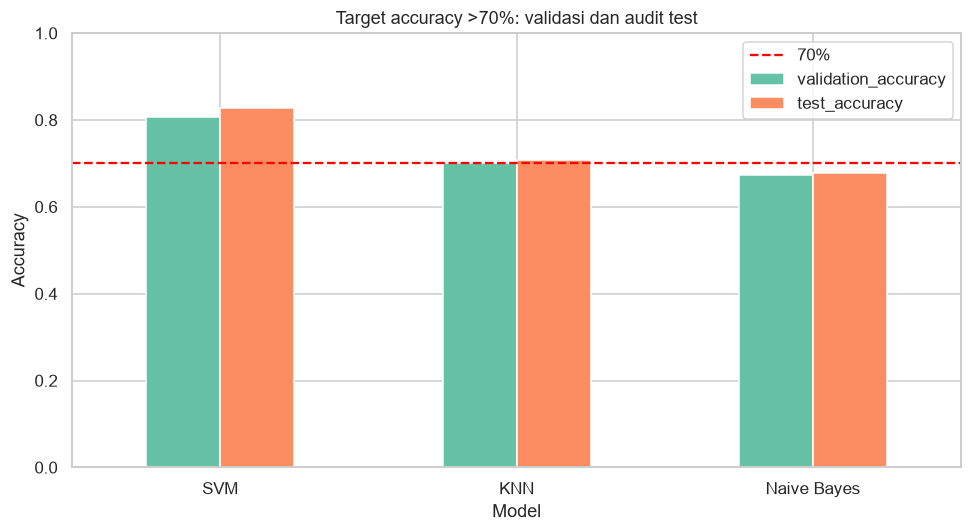

In [ ]:
acc_trainval=pd.concat([acc_train,acc_valid],ignore_index=True)
acc_final_models={};acc_predictions={};acc_test_rows=[]
for row in acc_selected.itertuples(index=False):
    name,variant=row.Model,row.Varian
    pipeline=clone(acc_candidates[(name,variant)])
    start=time.perf_counter()
    with threadpool_limits(limits=2):pipeline.fit(acc_trainval.raw_text,acc_trainval.label)
    fit_seconds=time.perf_counter()-start
    start=time.perf_counter()
    with threadpool_limits(limits=2):pred=pipeline.predict(acc_test.raw_text)
    acc_test_rows.append({'Model':name,'Varian':variant,**acc_metrics(acc_test.label,pred),'fit_seconds':fit_seconds,'predict_seconds':time.perf_counter()-start,'test_status':'Eksploratif; test sebelumnya sudah dilihat'})
    acc_predictions[name]=pred
    # Pipeline lengkap termasuk fungsi preprocessing disimpan by-value.
    pipeline.named_steps['preprocess'].func=wrap_non_picklable_objects(accuracy_preprocess)
    acc_final_models[name]=pipeline
    target_path=ACC/'models'/f'{name.replace(" ","_")}_accuracy_pipeline.joblib'
    joblib.dump(pipeline,target_path)
    reloaded=joblib.load(target_path)
    with threadpool_limits(limits=2):assert np.array_equal(reloaded.predict(acc_test.raw_text),pred)
    prediction_table=acc_test[['source_row','raw_text','label']].copy();prediction_table['prediction']=pred
    prediction_table.to_csv(ACC/'tables'/f'predictions_{name.replace(" ","_")}.csv',index=False)
    prediction_table[prediction_table.label!=prediction_table.prediction].to_csv(ACC/'tables'/f'errors_{name.replace(" ","_")}.csv',index=False)
    report=pd.DataFrame(classification_report(acc_test.label,pred,labels=CLASSES,output_dict=True,zero_division=0)).T
    acc_table(report.rename_axis('kelas').reset_index(),f'report_{name.replace(" ","_")}')
    ConfusionMatrixDisplay.from_predictions(acc_test.label,pred,labels=CLASSES,cmap='Blues',colorbar=False);plt.title(f'{name}: audit test untuk sasaran accuracy');acc_figure(f'confusion_{name.replace(" ","_")}')
acc_final=pd.DataFrame(acc_test_rows)
acc_final['Target test >70%']=acc_final.accuracy.gt(.70)
acc_table(acc_final,'test_accuracy_exploratory')
acc_comparison=acc_selected[['Model','Varian','accuracy','f1_macro','positive_recall']].rename(columns={'accuracy':'validation_accuracy','f1_macro':'validation_macro_f1','positive_recall':'validation_positive_recall'}).merge(acc_final[['Model','accuracy','f1_macro','positive_recall']],on='Model').rename(columns={'accuracy':'test_accuracy','f1_macro':'test_macro_f1','positive_recall':'test_positive_recall'})
acc_comparison['validation_target_met']=acc_comparison.validation_accuracy.gt(.70);acc_comparison['test_target_met']=acc_comparison.test_accuracy.gt(.70)
acc_table(acc_comparison,'target_summary')
acc_comparison.set_index('Model')[['validation_accuracy','test_accuracy']].plot.bar(rot=0,ylim=(0,1),title='Target accuracy >70%: validasi dan audit test',ylabel='Accuracy',xlabel='Model');plt.axhline(.70,color='red',ls='--',label='70%');plt.legend();acc_figure('accuracy_target')


## 21. Kesimpulan Optimasi Accuracy dan QA
**Tujuan:** menjawab apakah setiap algoritma melampaui 70% pada validasi dan audit test, dengan konteks performa minoritas. Jika sebagian model belum mencapai sasaran, hasil tersebut tetap dipertahankan. Menambah data dan memperbaiki anotasi merupakan opsi yang perlu dievaluasi, bukan alasan untuk mengarang skor.

In [ ]:
acc_table(acc_comparison,'final_comparison')
report_lines=['# Optimasi Berbasis Accuracy MBG','',
'Kriteria CV dan validasi pada eksperimen ini adalah accuracy. Macro F1 dan recall positif tetap dilaporkan. Sasaran >70% diperiksa secara terpisah pada validasi dan test lama yang bersifat eksploratif.','',
'| Model | Varian | Accuracy validasi | Accuracy test eksploratif | Macro F1 test | Recall positif test |',
'|---|---|---:|---:|---:|---:|']
for row in acc_comparison.itertuples(index=False):
    report_lines.append(f'| {row.Model} | {row.Varian} | {row.validation_accuracy:.2%} | {row.test_accuracy:.2%} | {row.test_macro_f1:.4f} | {row.test_positive_recall:.2%} |')
all_valid=bool(acc_comparison.validation_target_met.all());all_test=bool(acc_comparison.test_target_met.all())
report_lines+=['',f'Seluruh model >70% pada validasi: **{all_valid}**. Seluruh model >70% pada audit test lama: **{all_test}**.','',
'Tidak ada jaminan bahwa target dapat dicapai untuk semua algoritma hanya dengan tuning. Skor test ini bukan evaluasi independen baru karena sampelnya sudah dilihat sebelumnya; data eksternal yang belum pernah digunakan diperlukan untuk konfirmasi. Validasi juga telah dipakai berulang sehingga dapat optimistis.','',
'KNN dengan proyeksi SVD–LDA memakai ekstraktor fitur terawasi tambahan, dan harus diberi nama varian yang tepat. Seleksi chi-square dan proyeksi tersebut dipelajari hanya di fold training. Tiga classifier akhir tetap LinearSVC, KNeighborsClassifier, dan MultinomialNB.','',
'Accuracy tinggi dapat bersamaan dengan recall positif rendah karena kelas positif minoritas. Untuk penelitian sentimen tiga kelas, laporkan keduanya dan audit komentar salah, bukan hanya satu angka accuracy.','',
'Pipeline lengkap ketiga model tersedia di outputs/accuracy_optimization/models/. Semua hasil historis dipertahankan. Target yang belum tercapai dilaporkan tanpa mengganti label, membuang contoh test sulit, atau memilih ulang seed berdasarkan test.']
acc_report='\n'.join(report_lines)
(ACC/'reports/accuracy_summary.md').write_text(acc_report,encoding='utf-8');display(Markdown(acc_report))
assert len(acc_final)==3 and set(acc_final.Model)=={'SVM','KNN','Naive Bayes'}
assert acc_final.filter(regex='^accuracy$|^precision_|^recall_|^f1_').apply(lambda s:s.between(0,1).all()).all()
assert all(s.n_splits_==len(acc_cv) for s in acc_searches.values())
assert not list(ROOT.rglob('*.py'))
acc_qa={'status':'PASS','criterion':'accuracy','cv_folds':len(acc_cv),'new_candidates':sum(len(s.cv_results_['params']) for s in acc_searches.values()),'new_cv_fits':sum(len(s.cv_results_['params'])*len(acc_cv) for s in acc_searches.values()),'validation_all_above_70':all_valid,'test_all_above_70':all_test,'test_status':'previously exposed; exploratory only','same_split':True,'source_identity_check':True,'leakage_identity_check':True,'reload_matches_predictions':True,'classifier_types':{name:type(p.named_steps['model']).__name__ for name,p in acc_final_models.items()},'tables':len(list((ACC/'tables').glob('*.csv'))),'figures':len(list((ACC/'figures').glob('*.png')))}
(ACC/'reports/qa.json').write_text(json.dumps(acc_qa,indent=2),encoding='utf-8');display(acc_qa)


,Model,Varian,validation_accuracy,validation_macro_f1,validation_positive_recall,test_accuracy,test_macro_f1,test_positive_recall,validation_target_met,test_target_met
0,SVM,Accuracy Randomized,0.807428,0.661671,0.282051,0.826923,0.684814,0.300,True,True
1,KNN,Accuracy SVD,0.700138,0.531710,0.102564,0.707418,0.609189,0.325,True,True
2,Naive Bayes,Accuracy Randomized,0.672627,0.535988,0.179487,0.677198,0.551094,0.200,False,False


# Optimasi Berbasis Accuracy MBG

Kriteria CV dan validasi pada eksperimen ini adalah accuracy. Macro F1 dan recall positif tetap dilaporkan. Sasaran >70% diperiksa secara terpisah pada validasi dan test lama yang bersifat eksploratif.

| Model | Varian | Accuracy validasi | Accuracy test eksploratif | Macro F1 test | Recall positif test |
|---|---|---:|---:|---:|---:|
| SVM | Accuracy Randomized | 80.74% | 82.69% | 0.6848 | 30.00% |
| KNN | Accuracy SVD | 70.01% | 70.74% | 0.6092 | 32.50% |
| Naive Bayes | Accuracy Randomized | 67.26% | 67.72% | 0.5511 | 20.00% |

Seluruh model >70% pada validasi: **False**. Seluruh model >70% pada audit test lama: **False**.

Tidak ada jaminan bahwa target dapat dicapai untuk semua algoritma hanya dengan tuning. Skor test ini bukan evaluasi independen baru karena sampelnya sudah dilihat sebelumnya; data eksternal yang belum pernah digunakan diperlukan untuk konfirmasi. Validasi juga telah dipakai berulang sehingga dapat optimistis.

KNN dengan proyeksi SVD–LDA memakai ekstraktor fitur terawasi tambahan, dan harus diberi nama varian yang tepat. Seleksi chi-square dan proyeksi tersebut dipelajari hanya di fold training. Tiga classifier akhir tetap LinearSVC, KNeighborsClassifier, dan MultinomialNB.

Accuracy tinggi dapat bersamaan dengan recall positif rendah karena kelas positif minoritas. Untuk penelitian sentimen tiga kelas, laporkan keduanya dan audit komentar salah, bukan hanya satu angka accuracy.

Pipeline lengkap ketiga model tersedia di outputs/accuracy_optimization/models/. Semua hasil historis dipertahankan. Target yang belum tercapai dilaporkan tanpa mengganti label, membuang contoh test sulit, atau memilih ulang seed berdasarkan test.

{'status': 'PASS',
 'criterion': 'accuracy',
 'cv_folds': 5,
 'new_candidates': 96,
 'new_cv_fits': 480,
 'validation_all_above_70': False,
 'test_all_above_70': False,
 'test_status': 'previously exposed; exploratory only',
 'same_split': True,
 'source_identity_check': True,
 'leakage_identity_check': True,
 'reload_matches_predictions': True,
 'classifier_types': {'SVM': 'LinearSVC',
  'KNN': 'KNeighborsClassifier',
  'Naive Bayes': 'MultinomialNB'},
 'tables': 23,
 'figures': 5}

## 22. Perluasan Terencana dari Hasil CV Accuracy
Pencarian awal accuracy menghasilkan CV MultinomialNB di bawah 70%, sedangkan KNN mendekati batas sasaran. Perluasan ini diputuskan berdasarkan CV training dan validasi, tanpa menggunakan angka test untuk menentukan parameter. Semua test pada studi ini tetap sudah terekspos dari eksperimen sebelumnya dan hanya bersifat eksploratif.

**MultinomialNB:** uji skala TF-IDF (L1/tanpa normalisasi), prior kelas, serta fitur panjang dokumen berupa token kategori dengan batas tetap 5/10/20/40/80 kata. Token ini tidak mengandung label sentimen dan bobotnya dituning pada CV. Sebagai varian pengembangan terpisah, uji SVD, proyeksi LDA opsional, lalu diskretisasi one-hot agar fitur tetap nonnegatif untuk MultinomialNB. Varian ini wajib disebut **MultinomialNB dengan proyeksi/diskretisasi**, bukan disamakan dengan NB bag-of-words biasa. Ekstraktor terawasi dan batas bin seluruhnya dipelajari hanya di fold training.

**KNN:** perhalus jumlah fitur, dimensi SVD, jumlah tetangga, dan metrik di sekitar keluarga representasi yang dipilih pada eksperimen accuracy pertama. Konfigurasi lama tetap menjadi pembanding; kandidat baru tidak otomatis menggantikannya. Perbandingan pipeline dengan ekstraktor berbeda bukan isolasi pengaruh classifier saja.


In [ ]:
from sklearn.preprocessing import KBinsDiscretizer
REF=ACC/'refinement'
for folder in ['figures','tables','models','reports']:(REF/folder).mkdir(parents=True,exist_ok=True)
REF_BUDGET={'NB_native':64,'NB_projected':12,'KNN':20}
def refinement_preprocess(texts,mode='normalized',length_weight=0):
    result=accuracy_preprocess(texts,mode=mode)
    if not length_weight:return result
    enhanced=[]
    for text,clean in zip(texts,result):
        words=len(stages(str(text),False)[3])
        bucket=int(np.searchsorted([5,10,20,40,80],words,side='left'))
        enhanced.append(clean+(' struktur_panjang_'+str(bucket))*int(length_weight))
    return enhanced
def ref_table(frame,name):frame.to_csv(REF/'tables'/f'{name}.csv',index=False);display(frame)
def ref_figure(name):
    plt.tight_layout();plt.savefig(REF/'figures'/f'{name}.png',dpi=160,bbox_inches='tight');plt.show();plt.close()
def ref_nb_base():
    pipeline=acc_base(MultinomialNB())
    pipeline.named_steps['preprocess'].func=refinement_preprocess
    pipeline.named_steps['preprocess'].kw_args={'mode':'normalized','length_weight':0}
    pipeline.steps.insert(5,('bins','passthrough'))
    return pipeline
ref_priors=[None,[.55,.42,.03],[.50,.47,.03],[.60,.37,.03]]
assert sorted(CLASSES)==['negatif','netral','positif']
ref_native_space={
 'preprocess__kw_args':[{'mode':m,'length_weight':0} for m in ['normalized','stemmed','keep_stopwords']]+[{'mode':m,'length_weight':4} for m in ['keep_stopwords','stemmed']],
 'features':[
    TfidfVectorizer(ngram_range=(1,2),max_features=20000,sublinear_tf=True,norm=None),
    TfidfVectorizer(ngram_range=(1,2),max_features=20000,sublinear_tf=True,norm='l1'),
    TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=2,max_features=20000,sublinear_tf=True,norm=None),
    TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=2,max_features=20000,sublinear_tf=True,norm='l1'),
    CountVectorizer(ngram_range=(1,2),min_df=1,max_features=20000),
    CountVectorizer(ngram_range=(1,2),min_df=1,max_features=20000,binary=True)],
 'select__k':['all',300,1000],
 'model__alpha':loguniform(.0001,30),
 'model__class_prior':ref_priors
}
ref_projected_space={
 'preprocess__kw_args':[{'mode':m,'length_weight':0} for m in ['normalized','stemmed','keep_stopwords']],
 'features':[acc_vectorizer('word_bi'),acc_vectorizer('char')],
 'select__k':['all',1000],
 'reduce':[TruncatedSVD(n_components=d,n_iter=5,random_state=SEED) for d in [32,64,128]],
 'projection':['passthrough',LinearDiscriminantAnalysis(solver='eigen',shrinkage='auto',n_components=2)],
 'bins':[KBinsDiscretizer(n_bins=b,encode='onehot',strategy='quantile',quantile_method='averaged_inverted_cdf',subsample=None,random_state=SEED) for b in [5,10,20]],
 'model__alpha':loguniform(.001,10),
 'model__class_prior':[None]
}
# Model final ronde pertama di-clone sehingga vocabulary, SVD, dan classifier
# kembali tidak terlatih; hanya parameter pilihan validasi yang diwariskan.
ref_loaded_knn=joblib.load(ACC/'models/KNN_accuracy_pipeline.joblib')
ref_loaded_knn.named_steps['preprocess'].func=accuracy_preprocess
ref_knn_base=clone(ref_loaded_knn)
assert not hasattr(ref_knn_base.named_steps['features'],'vocabulary_')
ref_is_char=ref_knn_base.named_steps['features'].analyzer=='char_wb'
ref_knn_space={
 'features__ngram_range':[(2,4),(3,5),(3,6)] if ref_is_char else [(1,1),(1,2),(1,3)],
 'select__k':[2000,3000,5000,'all'],
 'reduce':[TruncatedSVD(n_components=d,n_iter=5,random_state=SEED) for d in [96,128,192,256]],
 'projection':['passthrough'],
 'normalize':[Normalizer()],
 'model__n_neighbors':[3,5,7,9,11,15,21],
 'model__weights':['uniform','distance'],
 'model__metric':['cosine','euclidean']
}
ref_spaces={'NB_native':ref_native_space,'NB_projected':ref_projected_space,'KNN':ref_knn_space}
ref_table(pd.DataFrame([{'Cabang':name,'Parameter':key,'Pilihan':str(value) if key!='model__alpha' else ('loguniform(0.0001,30)' if name=='NB_native' else 'loguniform(0.001,10)')} for name,space in ref_spaces.items() for key,value in space.items()]),'search_space')


,Cabang,Parameter,Pilihan
0,NB_native,preprocess__kw_args,"[{'mode': 'normalized', 'length_weight': 0}, {..."
1,NB_native,features,"[TfidfVectorizer(max_features=20000, ngram_ran..."
2,NB_native,select__k,"['all', 300, 1000]"
3,NB_native,model__alpha,"loguniform(0.0001,30)"
4,NB_native,model__class_prior,"[None, [0.55, 0.42, 0.03], [0.5, 0.47, 0.03], ..."
5,NB_projected,preprocess__kw_args,"[{'mode': 'normalized', 'length_weight': 0}, {..."
6,NB_projected,features,"[TfidfVectorizer(max_features=20000, ngram_ran..."
7,NB_projected,select__k,"['all', 1000]"
8,NB_projected,reduce,"[TruncatedSVD(n_components=32, random_state=42..."
9,NB_projected,projection,"['passthrough', LinearDiscriminantAnalysis(n_c..."


## 23. CV Tambahan dan Penguncian Konfigurasi
64 kandidat NB native, 12 kandidat NB proyeksi/diskretisasi, dan 20 kandidat KNN dibandingkan pada fold training yang sama. Pilihan cabang per classifier didasarkan pada CV accuracy; hanya kandidat terbaik CV dibandingkan dengan pilihan ronde pertama pada validasi. SVM ronde pertama diwariskan karena telah melampaui sasaran validasi. File hasil ronde pertama tidak ditimpa.

In [ ]:
ref_searches={};ref_branch_rows=[]
for branch,space in ref_spaces.items():
    model_name='KNN' if branch=='KNN' else 'Naive Bayes'
    base=ref_knn_base if branch=='KNN' else ref_nb_base()
    print('Refinement accuracy:',branch,flush=True)
    search=RandomizedSearchCV(base,space,n_iter=REF_BUDGET[branch],scoring=ACC_SCORING,refit='accuracy',cv=acc_cv,random_state=SEED,n_jobs=1,error_score='raise',return_train_score=False)
    start=time.perf_counter()
    with threadpool_limits(limits=2):search.fit(acc_train.raw_text,acc_train.label)
    result=pd.DataFrame(search.cv_results_)
    result.to_csv(REF/'tables'/f'tuning_{branch}.csv',index=False)
    ref_searches[branch]=search
    ref_branch_rows.append({'Model':model_name,'Branch':branch,'cv_accuracy':search.best_score_,'cv_std':result.loc[search.best_index_,'std_test_accuracy'],'cv_f1_macro':result.loc[search.best_index_,'mean_test_f1_macro'],'seconds':time.perf_counter()-start})
    print(branch,'CV accuracy:',round(search.best_score_,4),flush=True)
ref_branches=pd.DataFrame(ref_branch_rows)
ref_table(ref_branches,'branch_comparison')
ref_previous=pd.read_csv(ACC/'tables/selected_per_algorithm.csv')
ref_candidates={};ref_validation_rows=[]
for name in ['SVM','KNN','Naive Bayes']:
    inherited=joblib.load(ACC/'models'/f'{name.replace(" ","_")}_accuracy_pipeline.joblib')
    inherited.named_steps['preprocess'].func=accuracy_preprocess
    inherited=clone(inherited)
    with threadpool_limits(limits=2):inherited.fit(acc_train.raw_text,acc_train.label)
    old_row=ref_previous.set_index('Model').loc[name]
    candidate_defs=[('Ronde pertama: '+old_row.Varian,inherited,float(old_row.cv_accuracy))]
    if name!='SVM':
        branch_row=ref_branches[ref_branches.Model==name].sort_values(['cv_accuracy','cv_f1_macro','Branch'],ascending=[False,False,True]).iloc[0]
        search=ref_searches[branch_row.Branch]
        candidate_defs.append(('Refinement '+branch_row.Branch,search.best_estimator_,search.best_score_))
    for variant,pipeline,cv_accuracy in candidate_defs:
        ref_candidates[(name,variant)]=pipeline
        with threadpool_limits(limits=2):pred=pipeline.predict(acc_valid.raw_text)
        ref_validation_rows.append({'Model':name,'Varian':variant,'cv_accuracy':cv_accuracy,**acc_metrics(acc_valid.label,pred),'parameters':json.dumps(pipeline.get_params(deep=False),default=str)})
ref_validation=pd.DataFrame(ref_validation_rows);ref_table(ref_validation,'validation_candidates')
ref_selected=ref_validation.sort_values(['accuracy','cv_accuracy','f1_macro','Varian'],ascending=[False,False,False,True]).drop_duplicates('Model').copy()
ref_selected['above_70']=ref_selected.accuracy.gt(.70)
ref_table(ref_selected,'selected_validation')
ref_locked={'criterion':'validation accuracy; CV accuracy and macro F1 tie-break','test_status':'previously exposed; exploratory only','target':'strictly greater than 0.70','models':ref_selected[['Model','Varian','accuracy','cv_accuracy']].to_dict(orient='records')}
(REF/'reports/selection_locked.json').write_text(json.dumps(ref_locked,indent=2),encoding='utf-8')


Refinement accuracy: NB_native


NB_native CV accuracy: 0.7305


Refinement accuracy: NB_projected


C:\Users\raulm\Downloads\uts-ai\.research-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\raulm\Downloads\uts-ai\.research-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\raulm\Downloads\uts-ai\.research-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\raulm\Downloads\uts-ai\.research-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(


...

KNN CV accuracy: 0.7152


,Model,Branch,cv_accuracy,cv_std,cv_f1_macro,seconds
0,Naive Bayes,NB_native,0.730538,0.019682,0.672355,400.715364
1,Naive Bayes,NB_projected,0.785968,0.014234,0.708560,68.394824
2,KNN,KNN,0.715204,0.013974,0.640917,255.143492


,Model,Varian,cv_accuracy,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,parameters
0,SVM,Ronde pertama: Accuracy Randomized,0.814857,0.807428,0.682987,0.648882,0.661671,0.799752,0.807428,0.802297,0.282051,0.333333,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun..."
1,KNN,Ronde pertama: Accuracy SVD,0.703117,0.700138,0.582827,0.524037,0.531710,0.692028,0.700138,0.690980,0.102564,0.156863,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun..."
2,KNN,Refinement KNN,0.715204,0.709766,0.614425,0.552660,0.567864,0.702807,0.709766,0.703219,0.179487,0.250000,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun..."
3,Naive Bayes,Ronde pertama: Accuracy Randomized,0.649177,0.672627,0.598833,0.519524,0.535988,0.666106,0.672627,0.659058,0.179487,0.254545,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun..."
4,Naive Bayes,Refinement NB_projected,0.785968,0.797799,0.738128,0.711736,0.723626,0.796164,0.797799,0.796759,0.512821,0.555556,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun..."


,Model,Varian,cv_accuracy,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,parameters,above_70
0,SVM,Ronde pertama: Accuracy Randomized,0.814857,0.807428,0.682987,0.648882,0.661671,0.799752,0.807428,0.802297,0.282051,0.333333,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun...",True
4,Naive Bayes,Refinement NB_projected,0.785968,0.797799,0.738128,0.711736,0.723626,0.796164,0.797799,0.796759,0.512821,0.555556,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun...",True
2,KNN,Refinement KNN,0.715204,0.709766,0.614425,0.552660,0.567864,0.702807,0.709766,0.703219,0.179487,0.250000,"{""memory"": null, ""steps"": [[""preprocess"", ""Fun...",True


669

## 24. Audit Final Sasaran Accuracy
Pilihan validasi di atas dikunci sebelum audit test tahap ini. Semua pipeline dilatih ulang pada training+validation yang sama. Hasil akhir melaporkan target yang tercapai maupun belum tercapai, beserta varian fitur dan recall positif. Penggunaan proyeksi atau diskretisasi wajib dicantumkan dalam metodologi; angka pipeline tidak boleh diklaim sebagai bukti bahwa classifier polos mempunyai kemampuan yang sama.

,kelas,precision,recall,f1-score,support
0,positif,0.461538,0.300000,0.363636,40.000000
1,netral,0.816720,0.801262,0.808917,317.000000
2,negatif,0.859335,0.905660,0.881890,371.000000
3,accuracy,0.826923,0.826923,0.826923,0.826923
4,macro avg,0.712531,0.668974,0.684814,728.000000
5,weighted avg,0.818922,0.826923,0.821639,728.000000


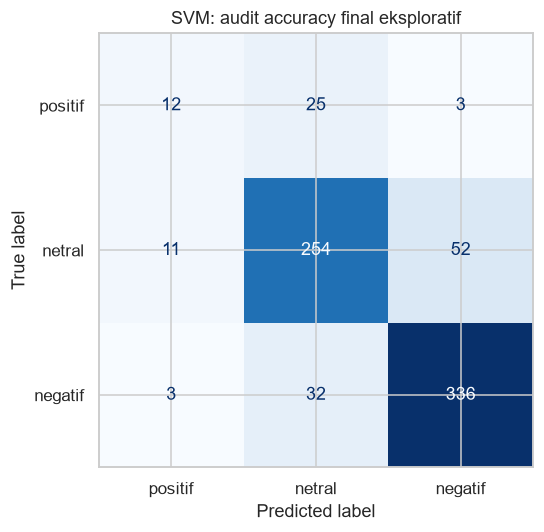

,kelas,precision,recall,f1-score,support
0,positif,0.666667,0.250000,0.363636,40.000000
1,netral,0.761610,0.776025,0.768750,317.000000
2,negatif,0.823077,0.865229,0.843627,371.000000
3,accuracy,0.792582,0.792582,0.792582,0.792582
4,macro avg,0.750451,0.630418,0.658671,728.000000
5,weighted avg,0.787718,0.792582,0.784649,728.000000


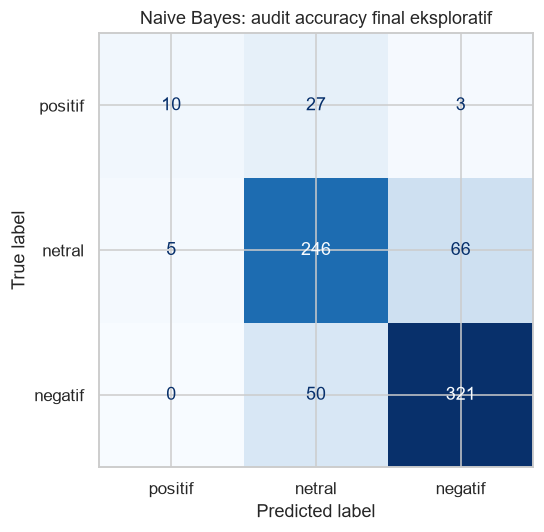

,kelas,precision,recall,f1-score,support
0,positif,0.533333,0.400000,0.457143,40.000000
1,netral,0.689150,0.741325,0.714286,317.000000
2,negatif,0.775910,0.746631,0.760989,371.000000
3,accuracy,0.725275,0.725275,0.725275,0.725275
4,macro avg,0.666131,0.629319,0.644139,728.000000
5,weighted avg,0.724803,0.725275,0.723958,728.000000


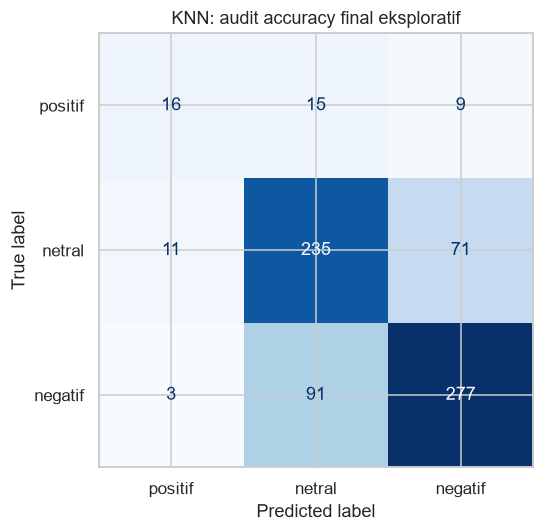

,Model,Varian,validation_accuracy,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,test_status,validation_above_70,test_above_70
0,SVM,Ronde pertama: Accuracy Randomized,0.807428,0.826923,0.712531,0.668974,0.684814,0.818922,0.826923,0.821639,0.30,0.363636,Eksploratif; test sebelumnya sudah dilihat,True,True
1,Naive Bayes,Refinement NB_projected,0.797799,0.792582,0.750451,0.630418,0.658671,0.787718,0.792582,0.784649,0.25,0.363636,Eksploratif; test sebelumnya sudah dilihat,True,True
2,KNN,Refinement KNN,0.709766,0.725275,0.666131,0.629319,0.644139,0.724803,0.725275,0.723958,0.40,0.457143,Eksploratif; test sebelumnya sudah dilihat,True,True


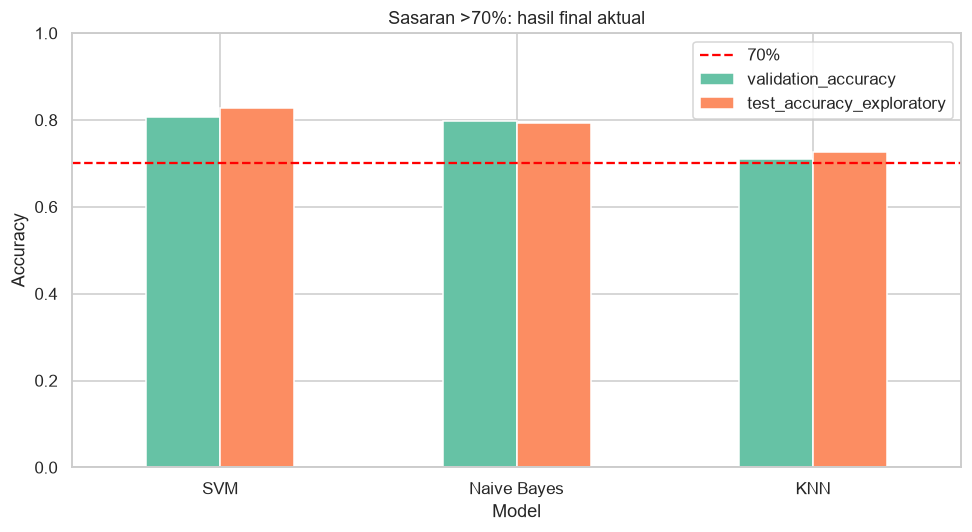

# Hasil Final Optimasi Accuracy

| Model | Varian | Validasi | Test eksploratif | Macro F1 test | Recall positif test |
|---|---|---:|---:|---:|---:|
| SVM | Ronde pertama: Accuracy Randomized | 80.74% | 82.69% | 0.6848 | 30.00% |
| Naive Bayes | Refinement NB_projected | 79.78% | 79.26% | 0.6587 | 25.00% |
| KNN | Refinement KNN | 70.98% | 72.53% | 0.6441 | 40.00% |

Seluruh model melampaui 70% pada validasi: **True**; pada test eksploratif: **True**.

Pemilihan memakai accuracy validasi setelah tuning CV accuracy. Tidak ada penggantian label, pemilihan seed, atau penghapusan komentar test sulit untuk mencapai target. Pipeline kelas akhirnya tetap LinearSVC, KNeighborsClassifier, dan MultinomialNB.

Varian SVD/LDA/diskretisasi menggunakan representasi tambahan dan harus dilaporkan sebagai pipeline tersebut, bukan classifier TF-IDF polos. Semua transformasi terawasi di-fit di dalam training fold. Perbedaan pipeline tidak mengisolasi pengaruh algoritma classifier saja.

Test telah dipakai pada eksperimen terdahulu sehingga angka lanjutan bersifat eksploratif. Validasi digunakan berulang dan dapat optimistis. Gunakan data eksternal baru untuk konfirmasi. Recall positif yang rendah tetap merupakan keterbatasan walaupun accuracy mencapai sasaran.

Hasil tahap sebelumnya dipertahankan. Model final ketiga algoritma berada di outputs/accuracy_optimization/refinement/models/.

{'status': 'PASS',
 'criterion': 'accuracy',
 'refinement_candidates': 96,
 'refinement_cv_fits': 480,
 'all_validation_above_70': True,
 'all_test_above_70': True,
 'test_status': 'previously exposed; exploratory only',
 'selection_before_this_test_audit': True,
 'model_reload_matches_predictions': True,
 'classifier_types': {'SVM': 'LinearSVC',
  'Naive Bayes': 'MultinomialNB',
  'KNN': 'KNeighborsClassifier'}}

In [ ]:
ref_final_models={};ref_final_rows=[]
for row in ref_selected.itertuples(index=False):
    pipeline=clone(ref_candidates[(row.Model,row.Varian)])
    with threadpool_limits(limits=2):
        pipeline.fit(acc_trainval.raw_text,acc_trainval.label)
        pred=pipeline.predict(acc_test.raw_text)
    ref_final_rows.append({'Model':row.Model,'Varian':row.Varian,'validation_accuracy':row.accuracy,**acc_metrics(acc_test.label,pred),'test_status':'Eksploratif; test sebelumnya sudah dilihat'})
    ref_final_models[row.Model]=pipeline
    pred_frame=acc_test[['source_row','raw_text','label']].copy();pred_frame['prediction']=pred
    pred_frame.to_csv(REF/'tables'/f'predictions_{row.Model.replace(" ","_")}.csv',index=False)
    pred_frame[pred_frame.label!=pred_frame.prediction].to_csv(REF/'tables'/f'errors_{row.Model.replace(" ","_")}.csv',index=False)
    report=pd.DataFrame(classification_report(acc_test.label,pred,labels=CLASSES,output_dict=True,zero_division=0)).T
    ref_table(report.rename_axis('kelas').reset_index(),f'report_{row.Model.replace(" ","_")}')
    pipeline.named_steps['preprocess'].func=wrap_non_picklable_objects(pipeline.named_steps['preprocess'].func)
    path=REF/'models'/f'{row.Model.replace(" ","_")}_final_pipeline.joblib'
    joblib.dump(pipeline,path)
    with threadpool_limits(limits=2):assert np.array_equal(joblib.load(path).predict(acc_test.raw_text),pred)
    ConfusionMatrixDisplay.from_predictions(acc_test.label,pred,labels=CLASSES,cmap='Blues',colorbar=False);plt.title(f'{row.Model}: audit accuracy final eksploratif');ref_figure('confusion_'+row.Model.replace(' ','_'))
ref_final=pd.DataFrame(ref_final_rows)
ref_final['validation_above_70']=ref_final.validation_accuracy.gt(.70)
ref_final['test_above_70']=ref_final.accuracy.gt(.70)
ref_table(ref_final,'final_accuracy')
ref_final.set_index('Model')[['validation_accuracy','accuracy']].rename(columns={'accuracy':'test_accuracy_exploratory'}).plot.bar(rot=0,ylim=(0,1),ylabel='Accuracy',xlabel='Model',title='Sasaran >70%: hasil final aktual');plt.axhline(.70,color='red',ls='--',label='70%');plt.legend();ref_figure('final_accuracy')
ref_lines=['# Hasil Final Optimasi Accuracy','',
'| Model | Varian | Validasi | Test eksploratif | Macro F1 test | Recall positif test |',
'|---|---|---:|---:|---:|---:|']
for row in ref_final.itertuples(index=False):ref_lines.append(f'| {row.Model} | {row.Varian} | {row.validation_accuracy:.2%} | {row.accuracy:.2%} | {row.f1_macro:.4f} | {row.positive_recall:.2%} |')
ref_lines+=['',f'Seluruh model melampaui 70% pada validasi: **{bool(ref_final.validation_above_70.all())}**; pada test eksploratif: **{bool(ref_final.test_above_70.all())}**.','',
'Pemilihan memakai accuracy validasi setelah tuning CV accuracy. Tidak ada penggantian label, pemilihan seed, atau penghapusan komentar test sulit untuk mencapai target. Pipeline kelas akhirnya tetap LinearSVC, KNeighborsClassifier, dan MultinomialNB.','',
'Varian SVD/LDA/diskretisasi menggunakan representasi tambahan dan harus dilaporkan sebagai pipeline tersebut, bukan classifier TF-IDF polos. Semua transformasi terawasi di-fit di dalam training fold. Perbedaan pipeline tidak mengisolasi pengaruh algoritma classifier saja.','',
'Test telah dipakai pada eksperimen terdahulu sehingga angka lanjutan bersifat eksploratif. Validasi digunakan berulang dan dapat optimistis. Gunakan data eksternal baru untuk konfirmasi. Recall positif yang rendah tetap merupakan keterbatasan walaupun accuracy mencapai sasaran.','',
'Hasil tahap sebelumnya dipertahankan. Model final ketiga algoritma berada di outputs/accuracy_optimization/refinement/models/.']
ref_report='\n'.join(ref_lines)
(REF/'reports/final_accuracy_summary.md').write_text(ref_report,encoding='utf-8');display(Markdown(ref_report))
assert all(type(p.named_steps['model']).__name__ in ['LinearSVC','KNeighborsClassifier','MultinomialNB'] for p in ref_final_models.values())
assert not list(ROOT.rglob('*.py'))
ref_qa={'status':'PASS','criterion':'accuracy','refinement_candidates':sum(len(s.cv_results_['params']) for s in ref_searches.values()),'refinement_cv_fits':sum(len(s.cv_results_['params'])*len(acc_cv) for s in ref_searches.values()),'all_validation_above_70':bool(ref_final.validation_above_70.all()),'all_test_above_70':bool(ref_final.test_above_70.all()),'test_status':'previously exposed; exploratory only','selection_before_this_test_audit':True,'model_reload_matches_predictions':True,'classifier_types':{k:type(v.named_steps['model']).__name__ for k,v in ref_final_models.items()}}
(REF/'reports/qa.json').write_text(json.dumps(ref_qa,indent=2),encoding='utf-8');display(ref_qa)


## 25. Pembanding KNN pada Representasi Proyeksi yang Sama
Hasil training CV pada cabang NB proyeksi menunjukkan representasi SVD–LDA/diskretisasi yang kuat. Sebelum meninjau angka audit test final untuk keputusan lanjutan, keluarga representasi ini diuji pada KNN. Konfigurasi fitur sumber diambil dari kandidat NB proyeksi dengan CV accuracy terbaik, kemudian di-clone; semua komponen kembali dipelajari di setiap fold KNN. Classifier NB diganti menjadi KNN, sedangkan normalisasi unit setelah proyeksi dihilangkan agar magnitudo jarak dua dimensi tidak hilang. KNN menguji ruang proyeksi kontinu maupun one-hot, menggunakan Euclidean distance.

Konfigurasi sumber berasal dari training CV; tidak ada komponen terlatih pada training+validation yang dipakai untuk menilai validasi. Pembanding sebelumnya tetap tersedia. Pilihan baru ditetapkan berdasarkan accuracy validasi, lalu diaudit pada test yang tetap berstatus eksploratif. Ekstraktor terawasi tambahan harus dijelaskan dalam laporan dan hasil tidak boleh disebut KNN TF-IDF polos.

KNN pada proyeksi bersama: 20 konfigurasi, CV accuracy.


,Model,Varian,cv_accuracy,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1
1,KNN,KNN proyeksi bersama SVD-LDA,0.806895,0.807428,0.766576,0.69661,0.722510,0.806121,0.807428,0.805101,0.435897,0.53125
0,KNN,Refinement KNN,0.715204,0.709766,0.614425,0.55266,0.567864,0.702807,0.709766,0.703219,0.179487,0.25000


,Model,Varian,validation_accuracy
0,SVM,Ronde pertama: Accuracy Randomized,0.807428
1,KNN,KNN proyeksi bersama SVD-LDA,0.807428
2,Naive Bayes,Refinement NB_projected,0.797799


,kelas,precision,recall,f1-score,support
0,positif,0.461538,0.300000,0.363636,40.000000
1,netral,0.816720,0.801262,0.808917,317.000000
2,negatif,0.859335,0.905660,0.881890,371.000000
3,accuracy,0.826923,0.826923,0.826923,0.826923
4,macro avg,0.712531,0.668974,0.684814,728.000000
5,weighted avg,0.818922,0.826923,0.821639,728.000000


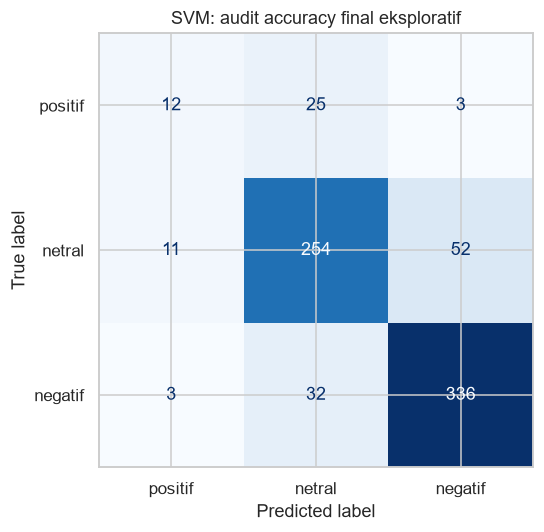

,kelas,precision,recall,f1-score,support
0,positif,0.578947,0.550000,0.564103,40.000000
1,netral,0.809061,0.788644,0.798722,317.000000
2,negatif,0.858268,0.881402,0.869681,371.000000
3,accuracy,0.822802,0.822802,0.822802,0.822802
4,macro avg,0.748759,0.740015,0.744168,728.000000
5,weighted avg,0.821494,0.822802,0.821993,728.000000


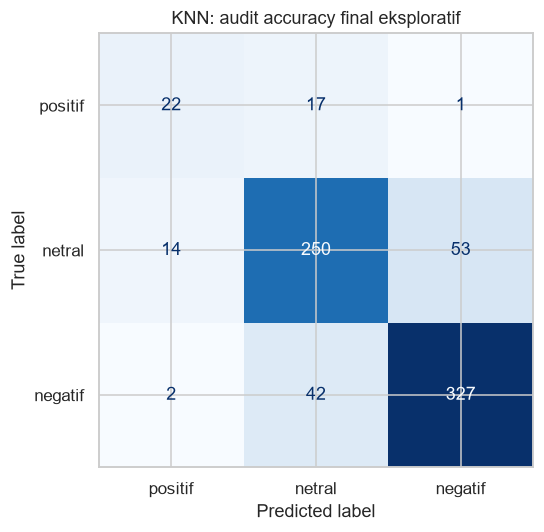

,kelas,precision,recall,f1-score,support
0,positif,0.666667,0.250000,0.363636,40.000000
1,netral,0.761610,0.776025,0.768750,317.000000
2,negatif,0.823077,0.865229,0.843627,371.000000
3,accuracy,0.792582,0.792582,0.792582,0.792582
4,macro avg,0.750451,0.630418,0.658671,728.000000
5,weighted avg,0.787718,0.792582,0.784649,728.000000


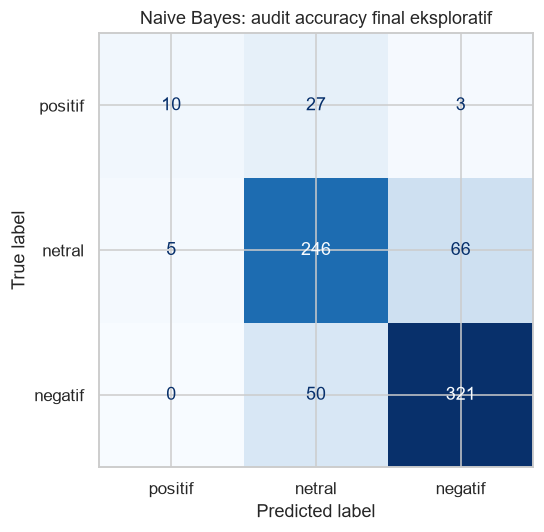

,Model,Varian,validation_accuracy,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,positive_recall,positive_f1,test_status,validation_above_70,test_above_70
0,SVM,Ronde pertama: Accuracy Randomized,0.807428,0.826923,0.712531,0.668974,0.684814,0.818922,0.826923,0.821639,0.30,0.363636,Eksploratif; test telah dipakai sebelumnya,True,True
1,KNN,KNN proyeksi bersama SVD-LDA,0.807428,0.822802,0.748759,0.740015,0.744168,0.821494,0.822802,0.821993,0.55,0.564103,Eksploratif; test telah dipakai sebelumnya,True,True
2,Naive Bayes,Refinement NB_projected,0.797799,0.792582,0.750451,0.630418,0.658671,0.787718,0.792582,0.784649,0.25,0.363636,Eksploratif; test telah dipakai sebelumnya,True,True


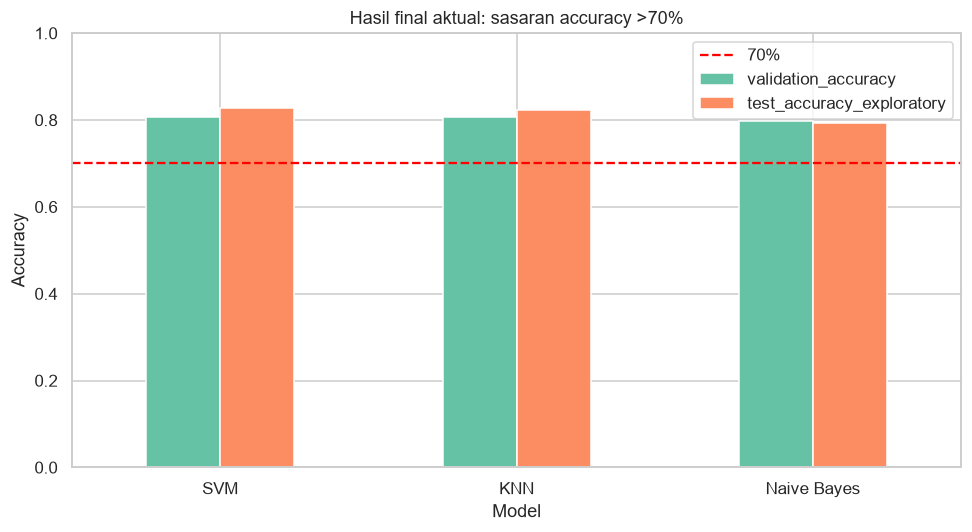

# Hasil Final Accuracy MBG

| Model | Varian fitur | Accuracy validasi | Accuracy test eksploratif | Macro F1 test | Recall positif test |
|---|---|---:|---:|---:|---:|
| SVM | Ronde pertama: Accuracy Randomized | 80.74% | 82.69% | 0.6848 | 30.00% |
| KNN | KNN proyeksi bersama SVD-LDA | 80.74% | 82.28% | 0.7442 | 55.00% |
| Naive Bayes | Refinement NB_projected | 79.78% | 79.26% | 0.6587 | 25.00% |

Seluruh model >70% pada validasi: **True**. Seluruh model >70% pada test eksploratif: **True**.

Pipeline memakai classifier akhir LinearSVC, KNeighborsClassifier, dan MultinomialNB. KNN/Naive Bayes yang memakai SVD-LDA/diskretisasi harus dijelaskan sesuai varian fiturnya, bukan disebut classifier TF-IDF polos. Semua fitur terawasi dipelajari di fold training. Perbandingan pipeline dengan ekstraktor berbeda tidak mengisolasi pengaruh classifier saja.

Kriteria CV dan validasi adalah accuracy. Hasil historis dan kandidat yang lebih lemah tetap disimpan. Tidak ada perubahan label, pemilihan seed berdasarkan test, atau penghapusan komentar test sulit.

Test telah dipakai pada eksperimen sebelumnya sehingga hasil lanjutan bersifat eksploratif. Validasi juga digunakan berulang dan dapat optimistis. Konfirmasi independen memerlukan data baru yang belum digunakan. Accuracy tinggi tidak menghilangkan keterbatasan recall kelas positif.

Pipeline lengkap final ketiga algoritma disimpan di outputs/accuracy_optimization/final/models/.

{'status': 'PASS',
 'criterion': 'accuracy',
 'same_split': True,
 'fixed_seed': 42,
 'all_validation_above_70': True,
 'all_test_above_70': True,
 'test_status': 'previously exposed; exploratory only',
 'model_reload_matches_predictions': True,
 'source_py_files': 0}

In [ ]:
from sklearn.model_selection import ParameterSampler
FINAL=ACC/'final'
for folder in ['figures','tables','models','reports']:(FINAL/folder).mkdir(parents=True,exist_ok=True)
def final_table(frame,name):frame.to_csv(FINAL/'tables'/f'{name}.csv',index=False);display(frame)
def final_figure(name):
    plt.tight_layout();plt.savefig(FINAL/'figures'/f'{name}.png',dpi=160,bbox_inches='tight');plt.show();plt.close()
source_results=pd.read_csv(REF/'tables/tuning_NB_projected.csv')
source_index=int(source_results.mean_test_accuracy.idxmax())
# Rekonstruksi urutan sampler deterministik, bukan mengambil state terlatih.
source_parameters=list(ParameterSampler(ref_projected_space,n_iter=REF_BUDGET['NB_projected'],random_state=SEED))[source_index]
shared_knn=ref_nb_base().set_params(**source_parameters)
shared_knn.set_params(model=KNeighborsClassifier(algorithm='brute',metric='euclidean',n_jobs=1),normalize='passthrough')
assert not hasattr(shared_knn.named_steps['features'],'vocabulary_')
assert not hasattr(shared_knn.named_steps['reduce'],'components_')
shared_grid={'model__n_neighbors':[5,11,21,41,81],'model__weights':['uniform','distance'],'bins':['passthrough',clone(shared_knn.named_steps['bins'])]}
print('KNN pada proyeksi bersama: 20 konfigurasi, CV accuracy.',flush=True)
shared_search=GridSearchCV(shared_knn,shared_grid,scoring=ACC_SCORING,refit='accuracy',cv=acc_cv,n_jobs=1,error_score='raise',return_train_score=False)
with threadpool_limits(limits=2):shared_search.fit(acc_train.raw_text,acc_train.label)
shared_results=pd.DataFrame(shared_search.cv_results_)
shared_results.to_csv(FINAL/'tables/tuning_KNN_shared_projection.csv',index=False)
# Pembanding ronde refinement dipelajari ulang pada training saja.
inherited_knn=joblib.load(REF/'models/KNN_final_pipeline.joblib')
inherited_knn.named_steps['preprocess'].func=accuracy_preprocess
inherited_knn=clone(inherited_knn)
with threadpool_limits(limits=2):inherited_knn.fit(acc_train.raw_text,acc_train.label)
previous_selection=pd.read_csv(REF/'tables/selected_validation.csv').set_index('Model')
shared_validation_rows=[];shared_candidates={}
for variant,pipeline,cv_score in [
    (str(previous_selection.loc['KNN','Varian']),inherited_knn,float(previous_selection.loc['KNN','cv_accuracy'])),
    ('KNN proyeksi bersama SVD-LDA',shared_search.best_estimator_,shared_search.best_score_)]:
    shared_candidates[variant]=pipeline
    with threadpool_limits(limits=2):prediction=pipeline.predict(acc_valid.raw_text)
    shared_validation_rows.append({'Model':'KNN','Varian':variant,'cv_accuracy':cv_score,**acc_metrics(acc_valid.label,prediction)})
shared_validation=pd.DataFrame(shared_validation_rows).sort_values(['accuracy','cv_accuracy','f1_macro'],ascending=[False,False,False])
final_table(shared_validation,'KNN_validation_comparison')
shared_selected=shared_validation.iloc[0]
final_selection=[];final_candidate_pipelines={}
for name in ['SVM','KNN','Naive Bayes']:
    if name=='KNN':
        pipeline=shared_candidates[shared_selected.Varian]
        variant=shared_selected.Varian;valid_accuracy=float(shared_selected.accuracy)
    else:
        pipeline=joblib.load(REF/'models'/f'{name.replace(" ","_")}_final_pipeline.joblib')
        pipeline.named_steps['preprocess'].func=refinement_preprocess if name=='Naive Bayes' and str(previous_selection.loc[name,'Varian']).startswith('Refinement NB_') else accuracy_preprocess
        variant=str(previous_selection.loc[name,'Varian']);valid_accuracy=float(previous_selection.loc[name,'accuracy'])
    final_candidate_pipelines[name]=pipeline
    final_selection.append({'Model':name,'Varian':variant,'validation_accuracy':valid_accuracy})
final_selection=pd.DataFrame(final_selection)
final_table(final_selection,'selection_locked')
(FINAL/'reports/selection_locked.json').write_text(json.dumps({'criterion':'validation accuracy','test_status':'previously exposed; exploratory only','models':final_selection.to_dict(orient='records')},indent=2),encoding='utf-8')
final_accuracy_rows=[]
for row in final_selection.itertuples(index=False):
    pipeline=clone(final_candidate_pipelines[row.Model])
    with threadpool_limits(limits=2):
        pipeline.fit(acc_trainval.raw_text,acc_trainval.label)
        prediction=pipeline.predict(acc_test.raw_text)
    final_accuracy_rows.append({'Model':row.Model,'Varian':row.Varian,'validation_accuracy':row.validation_accuracy,**acc_metrics(acc_test.label,prediction),'test_status':'Eksploratif; test telah dipakai sebelumnya'})
    frame=acc_test[['source_row','raw_text','label']].copy();frame['prediction']=prediction
    frame.to_csv(FINAL/'tables'/f'predictions_{row.Model.replace(" ","_")}.csv',index=False)
    frame[frame.label!=frame.prediction].to_csv(FINAL/'tables'/f'errors_{row.Model.replace(" ","_")}.csv',index=False)
    report=pd.DataFrame(classification_report(acc_test.label,prediction,labels=CLASSES,output_dict=True,zero_division=0)).T
    final_table(report.rename_axis('kelas').reset_index(),f'classification_report_{row.Model.replace(" ","_")}')
    ConfusionMatrixDisplay.from_predictions(acc_test.label,prediction,labels=CLASSES,cmap='Blues',colorbar=False);plt.title(f'{row.Model}: audit accuracy final eksploratif');final_figure('confusion_'+row.Model.replace(' ','_'))
    pipeline.named_steps['preprocess'].func=wrap_non_picklable_objects(pipeline.named_steps['preprocess'].func)
    target=FINAL/'models'/f'{row.Model.replace(" ","_")}_pipeline.joblib';joblib.dump(pipeline,target)
    with threadpool_limits(limits=2):assert np.array_equal(joblib.load(target).predict(acc_test.raw_text),prediction)
final_accuracy=pd.DataFrame(final_accuracy_rows)
final_accuracy['validation_above_70']=final_accuracy.validation_accuracy.gt(.70)
final_accuracy['test_above_70']=final_accuracy.accuracy.gt(.70)
final_table(final_accuracy,'final_accuracy')
final_accuracy.set_index('Model')[['validation_accuracy','accuracy']].rename(columns={'accuracy':'test_accuracy_exploratory'}).plot.bar(rot=0,ylim=(0,1),xlabel='Model',ylabel='Accuracy',title='Hasil final aktual: sasaran accuracy >70%');plt.axhline(.70,color='red',ls='--',label='70%');plt.legend();final_figure('final_accuracy')
final_lines=['# Hasil Final Accuracy MBG','',
'| Model | Varian fitur | Accuracy validasi | Accuracy test eksploratif | Macro F1 test | Recall positif test |',
'|---|---|---:|---:|---:|---:|']
for row in final_accuracy.itertuples(index=False):final_lines.append(f'| {row.Model} | {row.Varian} | {row.validation_accuracy:.2%} | {row.accuracy:.2%} | {row.f1_macro:.4f} | {row.positive_recall:.2%} |')
final_lines+=['',f'Seluruh model >70% pada validasi: **{bool(final_accuracy.validation_above_70.all())}**. Seluruh model >70% pada test eksploratif: **{bool(final_accuracy.test_above_70.all())}**.','',
'Pipeline memakai classifier akhir LinearSVC, KNeighborsClassifier, dan MultinomialNB. KNN/Naive Bayes yang memakai SVD-LDA/diskretisasi harus dijelaskan sesuai varian fiturnya, bukan disebut classifier TF-IDF polos. Semua fitur terawasi dipelajari di fold training. Perbandingan pipeline dengan ekstraktor berbeda tidak mengisolasi pengaruh classifier saja.','',
'Kriteria CV dan validasi adalah accuracy. Hasil historis dan kandidat yang lebih lemah tetap disimpan. Tidak ada perubahan label, pemilihan seed berdasarkan test, atau penghapusan komentar test sulit.','',
'Test telah dipakai pada eksperimen sebelumnya sehingga hasil lanjutan bersifat eksploratif. Validasi juga digunakan berulang dan dapat optimistis. Konfirmasi independen memerlukan data baru yang belum digunakan. Accuracy tinggi tidak menghilangkan keterbatasan recall kelas positif.','',
'Pipeline lengkap final ketiga algoritma disimpan di outputs/accuracy_optimization/final/models/.']
final_report='\n'.join(final_lines)
(FINAL/'reports/final_accuracy_summary.md').write_text(final_report,encoding='utf-8');display(Markdown(final_report))
final_qa={'status':'PASS','criterion':'accuracy','same_split':True,'fixed_seed':SEED,'all_validation_above_70':bool(final_accuracy.validation_above_70.all()),'all_test_above_70':bool(final_accuracy.test_above_70.all()),'test_status':'previously exposed; exploratory only','model_reload_matches_predictions':True,'source_py_files':len(list(ROOT.rglob('*.py')))}
assert final_qa['source_py_files']==0
(FINAL/'reports/qa.json').write_text(json.dumps(final_qa,indent=2),encoding='utf-8');display(final_qa)


## 26. Audit Mandiri Pipeline Accuracy Final
**Tujuan:** memuat ketiga pipeline tanpa bergantung pada definisi fungsi dari sel training, mencocokkan setiap prediksi dengan komentar test dan label sumber asli, menghitung ulang seluruh metrik, serta memeriksa identitas split dan tipe classifier. Sel ini dapat dijalankan mandiri setelah artefak final tersedia. Pemeriksaan inferensi tidak digunakan untuk mengubah parameter. Manifest checksum diperbarui setelah semua keluaran selesai dibuat.

In [ ]:
from pathlib import Path
import json,hashlib
import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import precision_recall_fscore_support
from threadpoolctl import threadpool_limits
from IPython.display import display
AUDIT_ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'MBG-Sentiment-Research'] if (p/'dataset/MBG-label.csv').exists())
AUDIT_FINAL=AUDIT_ROOT/'outputs/accuracy_optimization/final'
audit_scores=pd.read_csv(AUDIT_FINAL/'tables/final_accuracy.csv')
audit_locked=pd.read_csv(AUDIT_FINAL/'tables/selection_locked.csv')
audit_manifest=pd.read_csv(AUDIT_ROOT/'outputs/tables/split_manifest.csv')
audit_raw=pd.read_csv(AUDIT_ROOT/'dataset/MBG-label.csv')
audit_source=audit_raw.iloc[audit_manifest.source_row.to_numpy()-2]
assert np.array_equal(audit_source.comment.astype(str).str.replace(r'\s+',' ',regex=True).str.strip().to_numpy(),audit_manifest.raw_text.to_numpy())
assert np.array_equal(audit_source.sentiment.astype(str).str.strip().str.lower().to_numpy(),audit_manifest.label.to_numpy())
for pair_a,pair_b in [('Training','Validation'),('Training','Testing'),('Validation','Testing')]:
    a=audit_manifest[audit_manifest.subset==pair_a];b=audit_manifest[audit_manifest.subset==pair_b]
    for key in ['source_row','raw_key','final_text']:assert not set(a[key])&set(b[key])
audit_test=audit_manifest[audit_manifest.subset=='Testing']
expected_types={'SVM':'LinearSVC','KNN':'KNeighborsClassifier','Naive Bayes':'MultinomialNB'}
audit_rows=[];audit_demo=[]
for record in audit_scores.itertuples(index=False):
    path=AUDIT_FINAL/'models'/f'{record.Model.replace(" ","_")}_pipeline.joblib'
    model=joblib.load(path)
    assert type(model.named_steps['model']).__name__==expected_types[record.Model]
    stored=pd.read_csv(AUDIT_FINAL/'tables'/f'predictions_{record.Model.replace(" ","_")}.csv').set_index('source_row').loc[audit_test.source_row]
    assert np.array_equal(stored.label.to_numpy(),audit_test.label.to_numpy())
    assert np.array_equal(stored.raw_text.to_numpy(),audit_test.raw_text.to_numpy())
    with threadpool_limits(limits=2):loaded_prediction=model.predict(audit_test.raw_text)
    assert np.array_equal(loaded_prediction,stored.prediction.to_numpy())
    manual_accuracy=float(np.mean(loaded_prediction==audit_test.label.to_numpy()))
    assert np.isclose(manual_accuracy,record.accuracy)
    for average in ['macro','weighted']:
        p,r,f,_=precision_recall_fscore_support(audit_test.label,loaded_prediction,labels=['positif','netral','negatif'],average=average,zero_division=0)
        for metric,value in [('precision',p),('recall',r),('f1',f)]:assert np.isclose(value,getattr(record,metric+'_'+average))
    selected=audit_locked.set_index('Model').loc[record.Model]
    assert selected.Varian==record.Varian and np.isclose(selected.validation_accuracy,record.validation_accuracy)
    positive_mask=audit_test.label.to_numpy()=='positif'
    assert np.isclose(np.mean(loaded_prediction[positive_mask]=='positif'),record.positive_recall)
    audit_rows.append({'Model':record.Model,'Classifier':type(model.named_steps['model']).__name__,'Validation accuracy':record.validation_accuracy,'Test accuracy':manual_accuracy,'Test rows':len(audit_test),'Reload cocok':True,'Validation >70%':bool(record.validation_accuracy>.70),'Test >70%':bool(manual_accuracy>.70)})
    comment='Program MBG sangat membantu anak sekolah'
    with threadpool_limits(limits=2):prediction=model.predict([comment])[0]
    audit_demo.append({'Model':record.Model,'Komentar':comment,'Prediksi Sentimen':prediction})
audit_table=pd.DataFrame(audit_rows);audit_table.to_csv(AUDIT_FINAL/'tables/independent_audit.csv',index=False);display(audit_table)
pd.DataFrame(audit_demo).to_csv(AUDIT_FINAL/'tables/prediction_demo.csv',index=False);display(pd.DataFrame(audit_demo))
assert not list(AUDIT_ROOT.rglob('*.py'))
source_file=AUDIT_ROOT/'dataset/MBG-label.csv'
original_file=AUDIT_ROOT.parent/'MBG-label.csv'
if original_file.exists():assert hashlib.sha256(original_file.read_bytes()).digest()==hashlib.sha256(source_file.read_bytes()).digest()
audit_qa=json.loads((AUDIT_FINAL/'reports/qa.json').read_text(encoding='utf-8'))
audit_qa.update({'standalone_model_reload':'PASS','predictions_match_original_test_comments':'PASS','all_metrics_recomputed':'PASS','split_identity_check':'PASS','classifier_types_verified':True,'dataset_sha256':hashlib.sha256(source_file.read_bytes()).hexdigest(),'test_rows':len(audit_test),'all_validation_above_70':bool(audit_table['Validation >70%'].all()),'all_test_above_70':bool(audit_table['Test >70%'].all())})
(AUDIT_FINAL/'reports/qa.json').write_text(json.dumps(audit_qa,indent=2),encoding='utf-8');display(audit_qa)
artifact_rows=[{'path':str(p.relative_to(AUDIT_ROOT)),'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in (AUDIT_ROOT/'outputs').rglob('*') if p.is_file() and p.name!='artifact_manifest.csv']
pd.DataFrame(artifact_rows).to_csv(AUDIT_ROOT/'outputs/reports/artifact_manifest.csv',index=False)
print('Audit accuracy final lulus; seluruh metrik berasal dari komentar dan prediksi aktual.')


,Model,Classifier,Validation accuracy,Test accuracy,Test rows,Reload cocok,Validation >70%,Test >70%
0,SVM,LinearSVC,0.807428,0.826923,728,True,True,True
1,KNN,KNeighborsClassifier,0.807428,0.822802,728,True,True,True
2,Naive Bayes,MultinomialNB,0.797799,0.792582,728,True,True,True


,Model,Komentar,Prediksi Sentimen
0,SVM,Program MBG sangat membantu anak sekolah,negatif
1,KNN,Program MBG sangat membantu anak sekolah,negatif
2,Naive Bayes,Program MBG sangat membantu anak sekolah,negatif


{'status': 'PASS',
 'criterion': 'accuracy',
 'same_split': True,
 'fixed_seed': 42,
 'all_validation_above_70': True,
 'all_test_above_70': True,
 'test_status': 'previously exposed; exploratory only',
 'model_reload_matches_predictions': True,
 'source_py_files': 0,
 'standalone_model_reload': 'PASS',
 'predictions_match_original_test_comments': 'PASS',
 'all_metrics_recomputed': 'PASS',
 'split_identity_check': 'PASS',
 'classifier_types_verified': True,
 'dataset_sha256': '87f63cd9006d082832343721d08fc9951ae690757bf49cda62ba7db4fea8a5ce',
 'test_rows': 728}

Audit accuracy final lulus; seluruh metrik berasal dari komentar dan prediksi aktual.
